# Import libraries

In [1]:
# General libraries
import gc
import json
from scripts.model import FF
import numpy as np
%pip install -q --upgrade git+https://github.com/Dralliag/opera-python.git
from opera import Mixture
from torch_geometric import seed_everything
from torch_geometric.nn.conv import *

# GraphToolbox
from graphtoolbox.data.dataset import *
from graphtoolbox.interpretability.explain import *
from graphtoolbox.models.gnn import *
from graphtoolbox.optim.optimizer import *
from graphtoolbox.training.metrics import *
from graphtoolbox.training.trainer import Trainer
from graphtoolbox.utils.attention import *
from graphtoolbox.utils.helper_functions import *
from graphtoolbox.utils.visualizations import *

# Autoreload
%load_ext autoreload
%autoreload 2


[notice] A new release of pip is available: 25.1.1 -> 26.1.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


# Import data

In [2]:
### GLOBAL VARIABLES
DATASET = 'weave' # 'rfrance', 'weave'
OPTIMIZE = False
TRAIN = True # whether to train GNNs/FF or just evaluate
OUT_CHANNELS = 48

# Device priority: mps (Apple Silicon) -> cuda -> cpu
if hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
elif torch.cuda.is_available():
    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")

print(f"Selected DEVICE: {DEVICE}")

Selected DEVICE: mps


In [5]:
if DATASET == 'weave':
    print("Weave Dataset")
    data_kwargs = {
        'node_var': 'id_unique',
        'dummies': ['instant', 'id_uniqueInt',],
        'day_inf_train': '2024-02-13',
        'day_sup_train': '2024-02-23',
        'day_inf_val': '2024-02-23',
        'day_sup_val': '2024-02-25',
        'day_inf_test': '2024-02-25',
        'day_sup_test': '2024-02-29'
    }

    dataset_kwargs = {
        'adj_matrix': 'dtw',
        'features_base': ['instant', 'id_uniqueInt', 'weekday'] + [f'consumption_l{t}' for t in range(1, 48+1)],
        'target_base': 'consumption',
    }

    nrows, ncols = 4, 7

    data = DataClass(path_train='./data/weave/train_weave_28.csv', 
                    path_test='./data/weave/test_weave_28.csv', 
                    data_kwargs=data_kwargs,
                    folder_config='.')

    graph_dataset_train = GraphDataset(data=data, period='train', 
                                    graph_folder='./graph_representations_weave',
                                    dataset_kwargs=dataset_kwargs,
                                    out_channels=OUT_CHANNELS)
    graph_dataset_val = GraphDataset(data=data, period='val', 
                                    scalers_feat=graph_dataset_train.scalers_feat, 
                                    scalers_target=graph_dataset_train.scalers_target,
                                    graph_folder='./graph_representations_weave',
                                    dataset_kwargs=dataset_kwargs,
                                    out_channels=OUT_CHANNELS)
    graph_dataset_test = GraphDataset(data=data, period='test',
                                    scalers_feat=graph_dataset_train.scalers_feat, 
                                    scalers_target=graph_dataset_train.scalers_target,
                                    graph_folder='./graph_representations_weave',
                                    dataset_kwargs=dataset_kwargs,
                                    out_channels=OUT_CHANNELS)
else:    
    print("Regional French Dataset")
    data_kwargs = {
        'node_var': 'Region',
        'dummies': ['Instant', 'JourSemaine', 'DayType', 'offset'],
        'day_inf_train': '2015-01-01',
        'day_sup_train': '2018-01-01',
        'day_inf_val': '2018-01-01',
        'day_sup_val': '2018-12-31',
        'day_inf_test': '2019-01-01',
        'day_sup_test': '2019-12-31'
    }

    dataset_kwargs = {
        'adj_matrix': 'gl3sr',
        'features_base': ['temp', 'nebu', 'wind', 'tempMax', 'tempMin', 'Posan', 'Instant', 'JourSemaine', 'JourFerie', 'offset', 'DayType', 'Weekend', 'temp_liss_fort', 'temp_liss_faible'] + [f'load_l{t}' for t in range(1, 48+1)],
        'feature_groups': {
            'temp':     ['temp', 'tempMax', 'tempMin', 'temp_liss_fort'],
            'calendar': ['Instant', 'JourSemaine', 'JourFerie'],
            'lags':     [f'load_l{t}' for t in range(1, 49)],
            'weather':  ['nebu', 'wind']
        },
        'target_base': 'load',
    }

    nrows, ncols = 3, 4

    data = DataClass(path_train='./data/rfrance/train2.csv', 
                    path_test='./data/rfrance/test2.csv', 
                    data_kwargs=data_kwargs,
                    folder_config='.')

    graph_dataset_train = GraphDataset(data=data, period='train', 
                                      graph_folder='./graph_representations_rfrance',
                                      dataset_kwargs=dataset_kwargs,
                                      out_channels=OUT_CHANNELS)
    graph_dataset_val = GraphDataset(data=data, period='val', 
                                     scalers_feat=graph_dataset_train.scalers_feat, 
                                     scalers_target=graph_dataset_train.scalers_target,
                                     graph_folder='./graph_representations_rfrance',
                                     dataset_kwargs=dataset_kwargs,
                                     out_channels=OUT_CHANNELS)
    graph_dataset_test = GraphDataset(data=data, period='test',
                                      scalers_feat=graph_dataset_train.scalers_feat, 
                                      scalers_target=graph_dataset_train.scalers_target,
                                      graph_folder='./graph_representations_rfrance',
                                      dataset_kwargs=dataset_kwargs,
                                      out_channels=OUT_CHANNELS)

Weave Dataset


# GNN Optimization

In [6]:
import torch
import inspect
from torch_geometric.nn import conv as pyg_conv

print("Auto-testing all torch_geometric.nn.conv layers\n")

num_nodes = 15
x = torch.randn(num_nodes, 16)
edge_index = torch.randint(0, num_nodes, (2, 40))

success, fail, skipped = [], [], []

skip_keywords = [
    "CuGraph",  
    "Hetero", "HAN", "HGT", "HEAT",  
    "Point", "PPF", "Hypergraph", 
]

for name, cls in inspect.getmembers(pyg_conv, inspect.isclass):
    if not name.endswith("Conv"):
        continue
    if any(k in name for k in skip_keywords):
        print(f"⏩ {name:<25} -> skipped (unsupported on macOS)")
        skipped.append(name)
        continue

    try:
        model = myGNN(
            in_channels=16,
            hidden_channels=32,
            out_channels=1,
            num_layers=2,
            conv_class=cls,
        )
        with torch.no_grad():
            out = model(x, edge_index)

        if not torch.is_tensor(out):
            raise TypeError("Output is not a tensor")
        success.append((name, tuple(out.shape)))
        print(f"✅ {name:<25} -> output {tuple(out.shape)}")

    except Exception as e:
        msg = str(e).splitlines()[0] if str(e) else "<no message>"
        if "pylibcugraphops" in msg:
            print(f"⏩ {name:<25} -> skipped (requires RAPIDS CUDA libs)")
            skipped.append(name)
            continue
        fail.append((name, type(e).__name__, msg))
        print(f"❌ {name:<25} -> {type(e).__name__}: {msg}")

print(f"\n✅ Successful: {len(success)}")
print(f"❌ Failed:     {len(fail)}")
print(f"⏩ Skipped:    {len(skipped)}")

if fail:
    print("\nExamples of failures:")
    for n, err, msg in fail[:10]:
        print(f"  - {n}: {err} ({msg})")


Auto-testing all torch_geometric.nn.conv layers

✅ AGNNConv                  -> output (15, 1)
✅ ARMAConv                  -> output (15, 1)
✅ AntiSymmetricConv         -> output (15, 1)
✅ CGConv                    -> output (15, 1)
✅ ChebConv                  -> output (15, 1)
✅ ClusterGCNConv            -> output (15, 1)
⏩ CuGraphGATConv            -> skipped (unsupported on macOS)
⏩ CuGraphRGCNConv           -> skipped (unsupported on macOS)
⏩ CuGraphSAGEConv           -> skipped (unsupported on macOS)
✅ DNAConv                   -> output (15, 1)
❌ DirGNNConv                -> AttributeError: type object 'GCNConv' has no attribute 'in_channels'
❌ DynamicEdgeConv           -> TypeError: DynamicEdgeConv.__init__() missing 2 required positional arguments: 'nn' and 'k'
✅ ECConv                    -> output (15, 1)
✅ EGConv                    -> output (15, 1)
✅ EdgeConv                  -> output (15, 1)
✅ FAConv                    -> output (15, 1)
❌ FastRGCNConv              -> TypeE

In [21]:
seed=42
OPTIMIZE = True
seed_everything(seed)
if OPTIMIZE:
    gnn_opt = Optimizer(model=myGNN, 
                        dataset_train=graph_dataset_train, 
                        dataset_val=graph_dataset_val, 
                        out_channels=OUT_CHANNELS,
                        conv_class=APPNP,
                        optim_kwargs={'num_layers': (1, 5),
                                      'hidden_channels': (32, 512),
                                      'lr': (1e-5, 1e-1),
                                    },
                        num_epochs=200)
    gnn_opt.optimize(n_trials=150)

[I 2026-05-28 16:12:15,529] A new study created in memory with name: myGNN_hpo
100%|██████████| 200/200 [00:05<00:00, 37.60it/s]
[I 2026-05-28 16:12:20,885] Trial 0 finished with value: 0.03579862415790558 and parameters: {'num_layers': 2, 'hidden_channels': 137, 'lr': 0.00015017423286675264, 'batch_size': 32, 'adj_matrix': 'precision'}. Best is trial 0 with value: 0.03579862415790558.
100%|██████████| 200/200 [00:19<00:00, 10.15it/s]
[I 2026-05-28 16:12:40,604] Trial 1 finished with value: 0.03808247298002243 and parameters: {'num_layers': 4, 'hidden_channels': 472, 'lr': 7.850913452488448e-05, 'batch_size': 32, 'adj_matrix': 'correlation'}. Best is trial 0 with value: 0.03579862415790558.
100%|██████████| 200/200 [00:15<00:00, 12.95it/s]
[I 2026-05-28 16:12:56,053] Trial 2 finished with value: 0.025201251730322838 and parameters: {'num_layers': 4, 'hidden_channels': 352, 'lr': 0.0036935512759157314, 'batch_size': 128, 'adj_matrix': 'correlation'}. Best is trial 2 with value: 0.025201

Study statistics: 
  Number of finished trials:  150
  Number of pruned trials:  139
  Number of complete trials:  11
Best trial:
  Value:  0.023233944550156593
  Params: 
    num_layers: 1
    hidden_channels: 290
    lr: 0.004275690850254304
    batch_size: 16
    adj_matrix: correlation


# GNN Training

In [19]:
SELECTED_MODELS = ['GCNConv']
ADDITIVE = False
# Load configs where each top-level key is the conv name
if ADDITIVE:
    config_path = f'configs/config_{DATASET}_add.json'
else:
    config_path = f'configs/config_{DATASET}_{n_series}.json'
if not os.path.isfile(config_path):
    raise FileNotFoundError(f"Config file not found: {config_path}")

_CONV_MAP = {
    'GCNConv': GCNConv,
    'GCN2Conv': GCN2Conv,
    'GATConv': GATConv,
    'GATv2Conv': GATv2Conv,
    'TransformerConv': TransformerConv,
    'TAGConv': TAGConv,
    'ChebConv': ChebConv,
    'APPNP': APPNP,
    'GraphSAGE': SAGEConv,
    'ARMAConv': ARMAConv,
    'ResGatedGraphConv': ResGatedGraphConv,
    'FiLMConv': FiLMConv,
    'AGNNConv': AGNNConv,
}

with open(config_path, 'r') as f:
    raw = json.load(f)

# Build CONFIGS from the new JSON shape
_selection = globals().get('SELECTED_MODELS', None)
if isinstance(_selection, str):
    _selection = [s.strip() for s in _selection.split(',') if s.strip()]

available_models = list(raw.keys())
to_keep = available_models if not _selection else [m for m in _selection if m in raw]

if _selection:
    unknown = [m for m in _selection if m not in raw]
    if unknown:
        print(f"Warning: unknown model(s) ignored: {unknown}. Available: {available_models}")

CONFIGS = {}
for model_name in to_keep:
    conf = raw[model_name]
    conv_key = conf.get('conv', model_name)  # utilise la clé si 'conv' absent
    print(conf)

    if isinstance(conv_key, str):
        if conv_key not in _CONV_MAP:
            raise KeyError(f"Unknown conv '{conv_key}' for model '{model_name}'. "
                           f"Available convs: {list(_CONV_MAP.keys())}")
        conv_cls = _CONV_MAP[conv_key]
    else:
        conv_cls = conv_key

    CONFIGS[model_name] = {
        'adj_matrix': conf['adj_matrix'],
        'conv': conv_cls,
        'params': conf['params'],
    }

print(f"Loaded CONFIGS from {config_path}: {list(CONFIGS.keys())}")

results = []
preds = {}
N = 10  # Number of runs per model
n_series = graph_dataset_train.num_nodes
os.makedirs(f"results_{DATASET}_{n_series}", exist_ok=True)

if TRAIN:
    for model_name, cfg in CONFIGS.items():
        conv_class = cfg["conv"]
        adj_matrix = cfg['adj_matrix']   # la configuration decide, cf. tab:gs1and2
        graph_dataset_train._set_adj_matrix(adj_matrix=adj_matrix)
        graph_dataset_val._set_adj_matrix(adj_matrix=adj_matrix)
        graph_dataset_test._set_adj_matrix(adj_matrix=adj_matrix)

        params = cfg["params"]
        results_rmse, results_mape = [], []

        for i in range(N):
            print(f"\n--- {model_name} | Run {i+1}/{N} ---")
            torch.manual_seed(42 + i); np.random.seed(42 + i)
            gc.collect()
            torch.cuda.empty_cache()

            conv_kwargs = {}
            for k in ["heads", "K", "alpha"]:
                if k in params:
                    conv_kwargs[k] = params[k]

            if ADDITIVE:
                model = AdditiveGraphModel(
                    feature_group_dims=graph_dataset_train.feature_group_dims,
                    hidden_channels=params.get("hidden_channels", 64),
                    num_layers=params.get("gnn_layers", params.get("num_layers", 2)),
                    out_channels=OUT_CHANNELS,
                    conv_class=conv_class,
                    conv_kwargs=conv_kwargs,
                ).to(DEVICE)
            else:
                if conv_class is not SAGEConv:
                    model = myGNN(
                        in_channels=graph_dataset_train.num_node_features,
                        num_layers=params["num_layers"],
                        hidden_channels=params["hidden_channels"],
                        out_channels=OUT_CHANNELS,
                        conv_class=conv_class,
                        conv_kwargs=conv_kwargs | {'add_self_loops': False}
                    ).to(DEVICE)
                else:
                    model = myGNN(
                        in_channels=graph_dataset_train.num_node_features,
                        num_layers=params["num_layers"],
                        hidden_channels=params["hidden_channels"],
                        out_channels=OUT_CHANNELS,
                        conv_class=SAGEConv,
                        conv_kwargs=conv_kwargs | {'project': True, 'add_self_loops': False}
                    ).to(DEVICE)
            
            trainer = Trainer(
                model=model,
                dataset_train=graph_dataset_train,
                dataset_val=graph_dataset_val,
                dataset_test=graph_dataset_test,
                batch_size=params['batch_size'],
                return_attention=False,
                model_kwargs={'lr': params['lr'], 'num_epochs': 300},
                lam_reg=0
            )

            if ADDITIVE:
                pred_model_test, target_test, edge_index, edge_weight, group_outputs = trainer.train(
                    plot_loss=False,
                    force_training=False,
                    save=False,
                    patience=300,
                )
            else:
                # print(model)
                pred_model_test, target_test, edge_index, edge_weight = trainer.train(
                    plot_loss=False,
                    force_training=True,
                    save=False,
                    patience=300,
                )

            preds[f"{model_name}_run{i}"] = {
                "predictions": pred_model_test,
            }

            rmse = RMSE(preds=pred_model_test.sum(dim=0).cpu().detach(), targets=target_test.sum(dim=0).cpu().detach()).item()
            results_rmse.append(rmse)
            mape = MAPE(preds=pred_model_test.sum(dim=0).cpu().detach(), targets=target_test.sum(dim=0).cpu().detach()).item()
            results_mape.append(mape)

        results.append({
            "model": model_name,
            "min_rmse": np.min(results_rmse),
            "mean_rmse": np.mean(results_rmse),
            "max_rmse": np.max(results_rmse),
            "std_rmse": np.std(results_rmse),
            "min_mape": np.min(results_mape),
            "mean_mape": np.mean(results_mape),
            "max_mape": np.max(results_mape),
            "std_mape": np.std(results_mape)
        })  
    
    results_df = pd.DataFrame(results)
    results_df = results_df.sort_values(by='mean_rmse')
    # average predictions over runs for each model
    for model_name in CONFIGS.keys():
        all_runs = [preds[f"{model_name}_run{i}"]["predictions"] for i in range(N)]
        avg_pred = torch.mean(torch.stack(all_runs), dim=0)
        preds[f"{model_name}_avg"] = {
            "predictions": avg_pred,
        }

    # compute metrics for averaged predictions
    for model_name in CONFIGS.keys():
        avg_pred = preds[f"{model_name}_avg"]["predictions"]
        rmse = RMSE(preds=avg_pred.sum(dim=0).cpu().detach(), targets=target_test.sum(dim=0).cpu().detach()).item()
        mape = 100*MAPE(preds=avg_pred.sum(dim=0).cpu().detach(), targets=target_test.sum(dim=0).cpu().detach()).item()
        print(f"{model_name} | Averaged Predictions | RMSE: {rmse:.4f}, MAPE: {mape:.4f}")

    # average predictions over all models
    all_model_preds = [preds[f"{model_name}_avg"]["predictions"] for model_name in CONFIGS.keys()]
    final_avg_pred = torch.mean(torch.stack(all_model_preds), dim=0)
    final_rmse = RMSE(preds=final_avg_pred.sum(dim=0).cpu().detach(), targets=target_test.sum(dim=0).cpu().detach()).item()
    final_mape = 100*MAPE(preds=final_avg_pred.sum(dim=0).cpu().detach(), targets=target_test.sum(dim=0).cpu().detach()).item()
    print(f"All Models Averaged Predictions | RMSE: {final_rmse:.4f}, MAPE: {final_mape:.4f}")


{'adj_matrix': 'dtw', 'params': {'num_layers': 2, 'hidden_channels': 96, 'lr': 0.005, 'batch_size': 64, 'lam_reg': 0}}
Loaded CONFIGS from configs/config_weave_28.json: ['GCNConv']

--- GCNConv | Run 1/10 ---
Training model...


100%|██████████| 300/300 [00:07<00:00, 38.53it/s]



--- GCNConv | Run 2/10 ---
Training model...


100%|██████████| 300/300 [00:06<00:00, 45.78it/s]



--- GCNConv | Run 3/10 ---
Training model...


...


--- GCNConv | Run 9/10 ---
Training model...


100%|██████████| 300/300 [00:06<00:00, 48.10it/s]



--- GCNConv | Run 10/10 ---
Training model...


100%|██████████| 300/300 [00:06<00:00, 48.75it/s]

GCNConv | Averaged Predictions | RMSE: 19647.4941, MAPE: 6.6110
All Models Averaged Predictions | RMSE: 19647.4941, MAPE: 6.6110


In [20]:
# save both preds in results_rfrance/ARMAConv/ARMAConv_{i}.pt
for model_name in CONFIGS.keys():
    model_folder = f"results_{DATASET}_{n_series}/{model_name}"
    os.makedirs(model_folder, exist_ok=True)
    for key in preds.keys():
        if key.startswith(model_name):
            save_path = os.path.join(model_folder, f"{key}.pt")
            torch.save(preds[key], save_path)
            print(f"Saved predictions for {key} at {save_path}")

Saved predictions for GCNConv_run0 at results_weave_28/GCNConv/GCNConv_run0.pt
Saved predictions for GCNConv_run1 at results_weave_28/GCNConv/GCNConv_run1.pt
Saved predictions for GCNConv_run2 at results_weave_28/GCNConv/GCNConv_run2.pt
Saved predictions for GCNConv_run3 at results_weave_28/GCNConv/GCNConv_run3.pt
Saved predictions for GCNConv_run4 at results_weave_28/GCNConv/GCNConv_run4.pt
Saved predictions for GCNConv_run5 at results_weave_28/GCNConv/GCNConv_run5.pt
Saved predictions for GCNConv_run6 at results_weave_28/GCNConv/GCNConv_run6.pt
Saved predictions for GCNConv_run7 at results_weave_28/GCNConv/GCNConv_run7.pt
Saved predictions for GCNConv_run8 at results_weave_28/GCNConv/GCNConv_run8.pt
Saved predictions for GCNConv_run9 at results_weave_28/GCNConv/GCNConv_run9.pt
Saved predictions for GCNConv_avg at results_weave_28/GCNConv/GCNConv_avg.pt


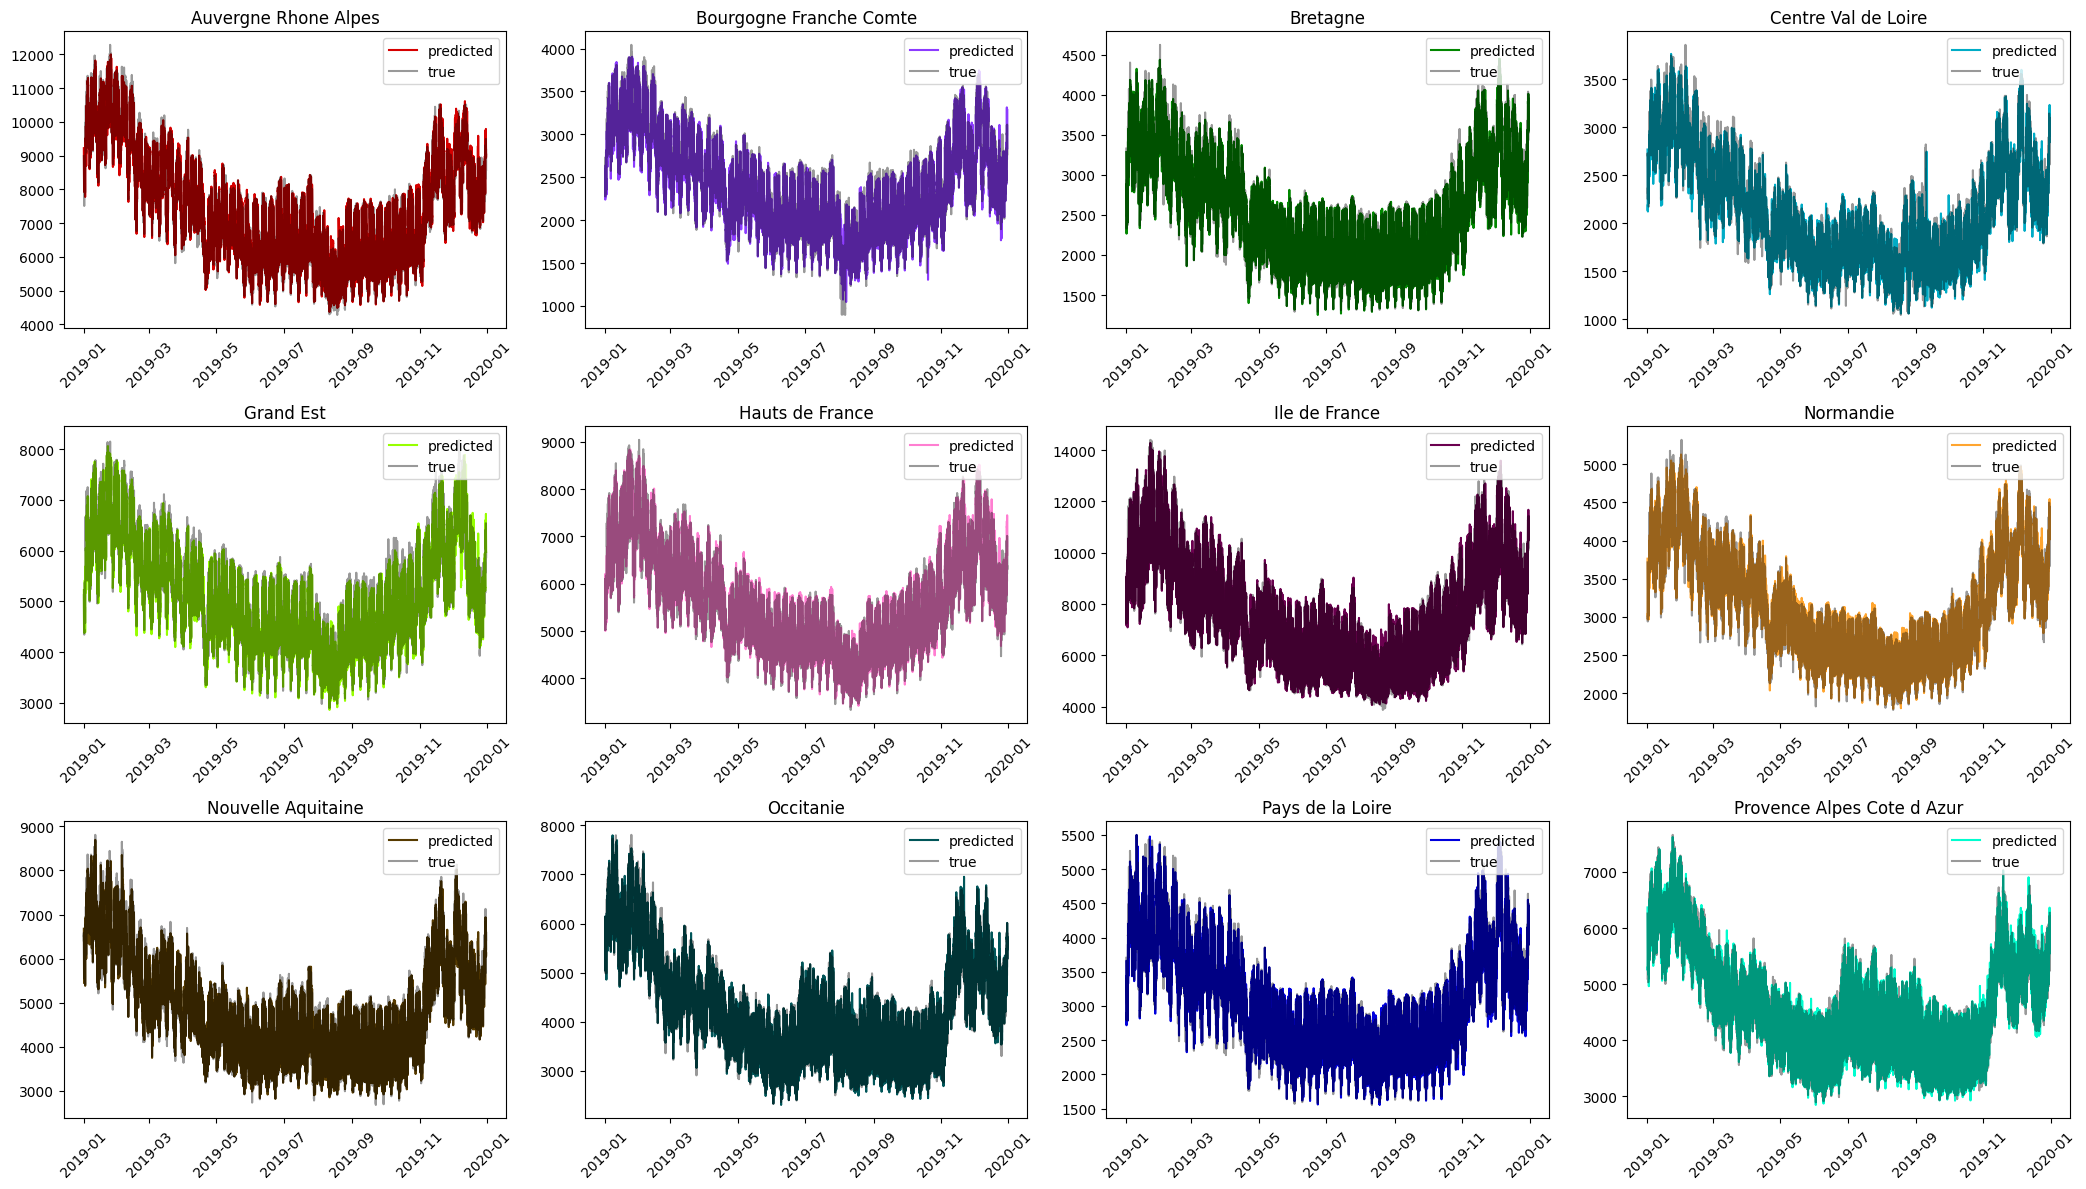

In [43]:
if TRAIN:
    plot_nodes(true=target_test, pred=pred_model_test, graph_dataset=graph_dataset_test, nrows=nrows, ncols=ncols)

In [9]:
if ADDITIVE:
    group_name = 'temp'
    contrib = group_outputs[group_name]  # Tensor [num_nodes, T_pred]
    feat_mats = get_group_feature_mats(group_name, data, graph_dataset_train, graph_dataset_test)

    for idx, (feat, X) in enumerate(feat_mats.items()):
        # Use full overlap, grouped by 48 instants (truncate to multiple of 48)
        Tm = min(X.shape[1], contrib.shape[1])
        if Tm < 48:
            continue
        x_mid, ale_mean, ale_std = compute_ALE_avg_over_instants(
            torch.as_tensor(X[:, :Tm]),  # or X[:, -Tm:] if you prefer aligning to the end
            contrib[:, :Tm],
            n_bins=20, period=48, align='start'  # set align='end' to align from the right@
        )
        plot_ALE_avg(x_mid, ale_mean, ale_std, label=f"load:{feat}", color=f"C{idx % 10}")

    for feat, X in feat_mats.items():
        Tm = min(X.shape[1], contrib.shape[1])
        if Tm < 48:
            continue
        x_mid, ale_nodes, counts = compute_ALE_per_node_avg_over_instants(
            torch.as_tensor(X[:, :Tm]),  # or X[:, -Tm:] with align='end'
            contrib[:, :Tm],
            n_bins=20, period=48, align='start'
        )
        plot_ALE_nodes(x_mid, ale_nodes, counts=counts, title_prefix=f"load:{feat} (avg over 48 instants)")


In [10]:
if ADDITIVE: 
    # ---- Build and plot importance (averaged over 48 instants, aggregated across nodes) ----
    df_imp = compute_feature_importances_from_ALE(
        group_outputs, data, graph_dataset_train, graph_dataset_test,
        n_bins=20, mode='avg48', period=48, align='start', method='rms'
    )
    topk_view = plot_feature_importance_bar(df_imp, top_k=10, normalize='sum', color='C0')

    # ---- Alternative: per-node ALE averaged over 48 instants, then aggregated across nodes ----
    df_imp_regional = compute_feature_importances_from_ALE(
        group_outputs, data, graph_dataset_train, graph_dataset_test,
        n_bins=20, mode='per_node_avg48', period=48, align='start', method='rms'
    )
    topk_view_reg = plot_feature_importance_bar(df_imp_regional, top_k=10, normalize='sum', color='C1')

In [11]:
if ADDITIVE:

    import shap
    import torch
    import numpy as np
    from torch_geometric.loader import DataLoader  # use PyG DataLoader for Data objects

    def _shap_to_2d(shap_raw, output_agg='sum'):
        """
        Convert various SHAP return types to 2D array [B, D].
        - shap_raw can be: np.ndarray, list of arrays (per-output), or shap.Explanation
        - If 3D [B, D, O], aggregate outputs via 'sum' or 'first'
        """
        # shap.Explanation
        if hasattr(shap_raw, 'values'):
            arr = np.asarray(shap_raw.values)
        else:
            arr = shap_raw

        # list of outputs -> stack and aggregate
        if isinstance(arr, list):
            mats = [np.asarray(a) for a in arr]  # each [B,D] or [B,D,1]
            if any(m.ndim == 3 for m in mats):
                mats = [m.squeeze(-1) if m.ndim == 3 and m.shape[-1] == 1 else m for m in mats]
            if output_agg == 'sum':
                arr2d = np.sum(np.stack(mats, axis=0), axis=0)
            else:
                arr2d = mats[0]
            return np.asarray(arr2d)

        # ndarray
        arr = np.asarray(arr)
        if arr.ndim == 3:
            # [B, D, O] -> aggregate outputs
            if output_agg == 'sum':
                arr = np.nansum(arr, axis=-1)
            else:
                arr = arr[..., 0]
        elif arr.ndim == 1:
            arr = arr[:, None]
        elif arr.ndim != 2:
            # Unknown shape -> try to flatten features dimension
            arr = arr.reshape(arr.shape[0], -1)
        return arr

    def _prepare_shap_inputs(
        X_bg_flat: np.ndarray,
        X_eval_flat: np.ndarray,
        q_clip: float = 0.001,
        min_std: float = 1e-8,
        jitter: float = 1e-6
    ):
        """
        Clean and stabilize arrays for SHAP without changing feature dimensionality.
        - replace NaN/Inf by column medians
        - robust clip to quantiles
        - add tiny jitter to near-constant columns
        Returns: X_bg_c (B_bg,D), X_eval_c (B_ev,D), keep_idx (np.ndarray[bool]=all True)
        """
        X_bg = np.asarray(X_bg_flat, dtype=np.float64, order='C')
        X_ev = np.asarray(X_eval_flat, dtype=np.float64, order='C')
        X_all = np.vstack([X_bg, X_ev])

        # Replace non-finite with medians
        finite = np.isfinite(X_all)
        for j in range(X_all.shape[1]):
            col = X_all[:, j]
            f = finite[:, j]
            med = np.median(col[f]) if f.any() else 0.0
            col[~f] = med
            X_all[:, j] = col

        # Robust clipping
        if 0.0 < q_clip < 0.5:
            lo = np.quantile(X_all, q_clip, axis=0)
            hi = np.quantile(X_all, 1.0 - q_clip, axis=0)
            swap = hi < lo
            if np.any(swap):
                lo[swap], hi[swap] = hi[swap], lo[swap]
            X_all = np.clip(X_all, lo, hi)

        # Split back
        n_bg = X_bg.shape[0]
        X_bg = X_all[:n_bg]
        X_ev = X_all[n_bg:]

        # Add tiny jitter to near-constant columns (keep dimensionality)
        std_bg = X_bg.std(axis=0)
        near = std_bg <= 10 * min_std
        if near.any():
            X_bg[:, near] += np.random.normal(scale=jitter, size=(X_bg.shape[0], int(near.sum())))
            X_ev[:, near] += np.random.normal(scale=jitter, size=(X_ev.shape[0], int(near.sum())))

        keep = np.ones(X_bg.shape[1], dtype=bool)
        return X_bg, X_ev, keep

    def _summarize_background(X_flat: np.ndarray, k_bg=20, method='kmeans'):
        X_flat = np.asarray(X_flat, dtype=np.float64, order='C')
        k = int(min(k_bg, len(X_flat)))
        if k <= 1 or method == 'sample':
            idx = np.random.choice(len(X_flat), size=max(1, k), replace=False)
            return X_flat[idx]
        with warnings.catch_warnings(record=True) as wlist:
            warnings.simplefilter("always")
            try:
                Xk = shap.kmeans(X_flat, k=k)
            except Exception:
                idx = np.random.choice(len(X_flat), size=k, replace=False)
                return X_flat[idx]
            bad = any(("overflow" in str(w.message).lower()) or ("divide by zero" in str(w.message).lower())
                    or ("invalid value" in str(w.message).lower()) for w in wlist)
            if bad:
                idx = np.random.choice(len(X_flat), size=k, replace=False)
                return X_flat[idx]
            return Xk

    def _safe_edge_tensors(edge_index, edge_weight, device):
        dev = torch.device(device) if isinstance(device, str) else (device or torch.device('cpu'))
        ei = edge_index
        if isinstance(ei, np.ndarray):
            ei = torch.as_tensor(ei, dtype=torch.long)
        if ei.dtype != torch.long:
            ei = ei.to(torch.long)
        if ei.device != dev:
            ei = ei.to(dev)
        ew = None
        if edge_weight is not None:
            ew = edge_weight
            if isinstance(ew, np.ndarray):
                ew = torch.as_tensor(ew, dtype=torch.float32)
            if ew.dtype != torch.float32:
                ew = ew.to(torch.float32)
            if ew.device != dev:
                ew = ew.to(dev)
        return ei, ew

    def _safe_mask(mask, device):
        if mask is None:
            return None
        if isinstance(mask, np.ndarray):
            mask = torch.as_tensor(mask, dtype=torch.float32)
        if mask.dtype != torch.float32:
            mask = mask.to(torch.float32)
        dev = torch.device(device) if isinstance(device, str) else (device or torch.device('cpu'))
        if mask.device != dev:
            mask = mask.to(dev)
        return mask

    def _ensure_2d_float32(x_np: np.ndarray) -> np.ndarray:
        x_np = np.asarray(x_np, dtype=np.float32)
        if x_np.ndim == 1:
            x_np = x_np[None, :]
        elif x_np.ndim > 2:
            x_np = x_np.reshape(x_np.shape[0], -1)
        return x_np

    def _get_template_mask(dataset):
        # Grab the first Data sample's mask_y if present
        try:
            loader = DataLoader(dataset, batch_size=1, shuffle=False)
            for batch in loader:
                return getattr(batch, 'mask_y', None)
        except Exception:
            return None
        return None

    def gnn_wrapper_factory(model, edge_index, edge_weight=None, device=None,
                            target_reduce='mean_node_mean_horizon', horizon_idx=None,
                            mask=None):
        """
        Wrap GNN into f(X_flat)->np.ndarray[B,1]. Moves inputs/edges/mask to device.
        """
        model.eval()
        dev = torch.device(device) if isinstance(device, str) else (device or next(model.parameters()).device)
        ei, ew = _safe_edge_tensors(edge_index, edge_weight, dev)
        msk = _safe_mask(mask, dev)

        def f(x_np):
            x_np = _ensure_2d_float32(x_np)
            if x_np.shape[0] == 0:
                return np.zeros((0, 1), dtype=np.float32)
            with torch.no_grad():
                x_t = torch.from_numpy(x_np).to(torch.float32).to(dev)  # [B, D]
                B = x_t.shape[0]
                N, F = f.num_nodes, f.num_feats
                try:
                    x_graph = x_t.view(B, N, F)
                except RuntimeError:
                    return np.zeros((B, 1), dtype=np.float32)
                outs = []
                for b in range(B):
                    out = model(x_graph[b], ei, edge_weight=ew, mask=msk)  # align with training API
                    if isinstance(out, dict):
                        out = sum(out.values())
                    if out.dim() == 1:
                        out = out.unsqueeze(-1)
                    if torch.isnan(out).any() or torch.isinf(out).any():
                        val = torch.zeros(1, device=dev)
                    elif target_reduce == 'mean_node_mean_horizon':
                        val = out.mean(dim=0).mean().unsqueeze(0)
                    elif target_reduce == 'sum_nodes_mean_horizon':
                        val = out.sum(dim=0).mean().unsqueeze(0)
                    elif target_reduce in ('sum_nodes_t', 'mean_nodes_t'):
                        idx = 0 if horizon_idx is None else int(horizon_idx)
                        idx = max(0, min(out.shape[1]-1, idx))
                        sl = out[:, idx]
                        val = (sl.sum() if target_reduce == 'sum_nodes_t' else sl.mean()).unsqueeze(0)
                    else:
                        raise ValueError(f"Unknown target_reduce {target_reduce}")
                    outs.append(val)
                if not outs:
                    return np.zeros((0, 1), dtype=np.float32)
                preds = torch.cat(outs, dim=0)  # [B,1]
            return preds.detach().cpu().numpy()
        return f

    def compute_gnn_shap(model, dataset_train, dataset_test, edge_index, edge_weight=None,
                        n_background=50, n_samples_eval=50, device='mps',
                        target_reduce='mean_node_mean_horizon', horizon_idx=None,
                        explainer_type='kernel', nsamples=512, k_bg=20, summarize_bg='kmeans'):
        """
        SHAP with mask-aware wrapper. Returns: shap_vals [B_eval,N,F], X_eval [B_eval,N,F], feature_names [F]
        """
        # Collect CPU float32 background/eval
        def sample_background(dataset, n):
            loader = DataLoader(dataset, batch_size=1, shuffle=True)
            xs = []
            for i, batch in enumerate(loader):
                x = batch.x
                if x.dtype != torch.float32:
                    x = x.to(torch.float32)
                xs.append(x.unsqueeze(0))
                if len(xs) >= n:
                    break
            if not xs:
                raise ValueError("Empty dataset for background.")
            return torch.cat(xs, dim=0)

        X_bg = sample_background(dataset_train, n_background)     # [B_bg,N,F]
        X_ev = sample_background(dataset_test, n_samples_eval)    # [B_ev,N,F]
        N, F = X_bg.shape[1], X_bg.shape[2]

        # Feature names from dataset_train.features if available
        if hasattr(dataset_train, "features"):
            feat_list = getattr(dataset_train, "features")
            if isinstance(feat_list, (list, tuple)) and len(feat_list) == F:
                feature_names = [str(f) for f in feat_list]
            else:
                feature_names = [f"feat_{j}" for j in range(F)]
        else:
            feature_names = [f"feat_{j}" for j in range(F)]

        template_mask = _get_template_mask(dataset_test)
        wrapper = gnn_wrapper_factory(
            model, edge_index=edge_index, edge_weight=edge_weight,
            device=device, target_reduce=target_reduce, horizon_idx=horizon_idx,
            mask=template_mask
        )
        wrapper.num_nodes = N
        wrapper.num_feats = F

        X_check = X_ev[:min(4, X_ev.shape[0])].reshape(-1, N * F).cpu().numpy().astype(np.float32)
        y_check = wrapper(X_check)
        if (not np.isfinite(y_check).all()) or (np.std(y_check) < 1e-12):
            raise RuntimeError("Wrapper returns NaN/Inf or constant outputs. Adjust target_reduce/horizon_idx or mask.")

        X_bg_flat = X_bg.reshape(X_bg.shape[0], -1).cpu().numpy().astype(np.float32)
        X_ev_flat = X_ev.reshape(X_ev.shape[0], -1).cpu().numpy().astype(np.float32)
        X_bg_c, X_ev_c, keep_idx = _prepare_shap_inputs(X_bg_flat, X_ev_flat, q_clip=0.001, min_std=1e-8, jitter=1e-6)

        X_bg_sum = _summarize_background(X_bg_c, k_bg=k_bg, method=('kmeans' if summarize_bg=='kmeans' else 'sample'))

        if explainer_type == 'sampling':
            explainer = shap.SamplingExplainer(wrapper, X_bg_sum)
            shap_c = explainer.shap_values(X_ev_c, nsamples=nsamples)
        elif explainer_type == 'kernel':
            explainer = shap.KernelExplainer(wrapper, X_bg_sum, link="identity")
            shap_c = explainer.shap_values(X_ev_c, nsamples=nsamples)
        else:
            masker = shap.maskers.Independent(X_bg_sum)
            explainer = shap.Explainer(wrapper, masker)
            shap_c = explainer(X_ev_c, max_evals=nsamples).values

        shap_2d = _shap_to_2d(shap_c, output_agg='sum')
        shap_2d = np.nan_to_num(shap_2d, nan=0.0, posinf=0.0, neginf=0.0)

        B_eval, D_keep = shap_2d.shape
        D_full = N * F
        assert D_keep == D_full, f"Dimension mismatch: got {D_keep}, expected {D_full}"

        shap_vals = shap_2d.reshape(B_eval, N, F).astype(np.float32)
        return shap_vals, X_ev.cpu().numpy().astype(np.float32), feature_names

    def aggregate_shap_values(shap_vals, feature_names, agg_nodes='mean', agg_samples='mean', abs_values=True):
        """
        shap_vals: [B, N, F]
        Returns DataFrame feature importances.
        """
        import pandas as pd
        sv = np.abs(shap_vals) if abs_values else shap_vals
        if agg_nodes == 'mean':
            sv = sv.mean(axis=1)  # [B,F]
        elif agg_nodes == 'sum':
            sv = sv.sum(axis=1)
        else:
            raise ValueError("agg_nodes must be 'mean' or 'sum'")
        if agg_samples == 'mean':
            imp = sv.mean(axis=0)
        elif agg_samples == 'sum':
            imp = sv.sum(axis=0)
        else:
            raise ValueError("agg_samples must be 'mean' or 'sum'")
        df = (pd.DataFrame({'feature': feature_names, 'importance': imp})
                .sort_values('importance', ascending=False).reset_index(drop=True))
        return df

    def plot_shap_importance(df, top_k=30, normalize='sum', color='C4'):
        if df.empty:
            return
        vals = df.importance.values.astype(float)
        if normalize == 'sum':
            s = vals.sum()
            vals = vals / s if s > 0 else vals
            ylabel = "Relative SHAP (sum=1)"
        elif normalize == 'max':
            m = vals.max()
            vals = vals / m if m > 0 else vals
            ylabel = "Relative SHAP (max=1)"
        else:
            ylabel = "SHAP importance"
        df_plot = df.copy()
        df_plot['norm'] = vals
        if top_k is not None:
            df_plot = df_plot.head(top_k)
        df_plot = df_plot.sort_values('norm', ascending=True)
        h = max(3, 0.4 * len(df_plot))
        plt.figure(figsize=(10, h))
        plt.barh(df_plot.feature, df_plot.norm, color=color, alpha=0.85)
        plt.xlabel(ylabel); plt.ylabel("Feature")
        plt.title("GNN SHAP feature importance")
        plt.grid(axis='x', alpha=0.2)
        plt.tight_layout()

    shap_vals, X_eval, feat_names = compute_gnn_shap(
        model=model,
        dataset_train=graph_dataset_train,
        dataset_test=graph_dataset_test,
        edge_index=graph_dataset_train.edge_index,
        edge_weight=graph_dataset_train.edge_weight,
        n_background=30,
        n_samples_eval=20,
        device='mps',                     # use MPS
        target_reduce='sum_nodes_mean_horizon',
        explainer_type='kernel',        # faster
        nsamples=128,                 # tune for speed/accuracy
        k_bg=15                        # k-means background size
    )
    df_shap = aggregate_shap_values(shap_vals, feat_names, agg_nodes='mean', agg_samples='mean', abs_values=True)
    plot_shap_importance(df_shap, top_k=10, normalize='sum')

# Baselines

Seven baselines are evaluated against the GNN models: ARIMA, feed-forward networks (global and local), XGBoost (global and local), and two persistence models.

In [17]:
target = graph_dataset_test.target

## ARIMA

One ARIMA model per forecast horizon (48 in total), each fitted on the aggregated node-level series. At inference, predictions are produced sequentially, updating the model state with each new observation.

### Global (per instant)

The consumption across all nodes is summed, and one ARIMA model is trained per half-hour slot.

In [7]:
# ARIMA Baseline (48 independent models with sequential one-step-ahead forecasting)
try:
    from statsmodels.tsa.arima.model import ARIMA
    import warnings
    from statsmodels.tools.sm_exceptions import ConvergenceWarning

    if TRAIN:
        print("\n" + "=" * 60)
        print("Training ARIMA Baseline (48 Models with Sequential Updates)")
        print("=" * 60)

        warnings.filterwarnings("ignore", category=ConvergenceWarning)
        warnings.filterwarnings("ignore", category=UserWarning)

        # Aggregate global time series from raw data
        y_train_arima = graph_dataset_train.dataframe.groupby("date")[[target]].sum().values.ravel()
        y_val_arima = graph_dataset_val.dataframe.groupby("date")[[target]].sum().values.ravel()
        y_test_arima = graph_dataset_test.dataframe.groupby("date")[[target]].sum().values.ravel()

        # Infer ARIMA order using auto_arima
        try:
            from pmdarima import auto_arima

            arma_train_val = np.concatenate([y_train_arima, y_val_arima])
            auto_model = auto_arima(
                arma_train_val,
                seasonal=False,
                stepwise=True,
                trace=False,
                max_p=5,
                max_d=2,
                max_q=5,
                error_action="ignore",
                suppress_warnings=True,
            )
            arma_order = auto_model.order
            print(f"Auto-inferred ARMA{arma_order}")
        except Exception as e:
            print(f"Warning: auto_arima failed ({type(e).__name__}). Using fallback order (1,0,1)")
            arma_order = (1, 0, 1)

        n_horizons = OUT_CHANNELS  # 48

        # Initialize output arrays
        y_pred_arma_train = np.zeros_like(y_train_arima, dtype=float)
        y_pred_arma_val = np.zeros_like(y_val_arima, dtype=float)
        y_pred_arma_test = np.zeros_like(y_test_arima, dtype=float)

        # Train 48 independent ARIMA models (one per instant)
        for h in range(n_horizons):
            # Extract subseries at indices h, h+48, h+96, ...
            idx_train = np.arange(h, len(y_train_arima), n_horizons)
            idx_val = np.arange(h, len(y_val_arima), n_horizons)
            idx_test = np.arange(h, len(y_test_arima), n_horizons)

            subseries_train = y_train_arima[idx_train]
            subseries_val = y_val_arima[idx_val]
            subseries_test = y_test_arima[idx_test]

            # Skip if insufficient training data
            if len(subseries_train) < max(5, sum(arma_order)):
                # Fallback: use persistence
                y_pred_arma_train[idx_train] = np.roll(subseries_train, 1)
                if len(subseries_train) > 0:
                    y_pred_arma_train[idx_train[0]] = subseries_train[0]
                if len(subseries_val) > 0:
                    y_pred_arma_val[idx_val] = np.roll(subseries_val, 1)
                    y_pred_arma_val[idx_val[0]] = subseries_train[-1] if len(subseries_train) > 0 else subseries_val[0]
                if len(subseries_test) > 0:
                    y_pred_arma_test[idx_test] = np.roll(subseries_test, 1)
                    y_pred_arma_test[idx_test[0]] = subseries_val[-1] if len(subseries_val) > 0 else subseries_train[-1]
                continue

            # Fit ARIMA on training subseries (frozen parameters for subsequent forecasts)
            try:
                model_train = ARIMA(subseries_train, order=arma_order)
                fit_train = model_train.fit()

                # In-sample prediction for training
                pred_train = fit_train.fittedvalues.values
                y_pred_arma_train[idx_train[:len(pred_train)]] = pred_train

                # Validation: one-step-ahead forecasting with sequential state updates (no parameter refit)
                if len(subseries_val) > 0:
                    fit_state = fit_train
                    pred_val = np.zeros(len(subseries_val), dtype=float)
                    
                    for t, obs in enumerate(subseries_val):
                        # One-step-ahead forecast
                        forecast = fit_state.get_forecast(steps=1)
                        pred_val[t] = forecast.predicted_mean.values[0]
                        
                        # Update state with new observation (frozen parameters)
                        fit_state = fit_state.append([obs], refit=False)
                    
                    y_pred_arma_val[idx_val] = pred_val

                # Test: one-step-ahead forecasting continuing from validation state
                if len(subseries_test) > 0:
                    fit_state = fit_state if len(subseries_val) > 0 else fit_train
                    pred_test = np.zeros(len(subseries_test), dtype=float)
                    
                    for t, obs in enumerate(subseries_test):
                        # One-step-ahead forecast
                        forecast = fit_state.get_forecast(steps=1)
                        pred_test[t] = forecast.predicted_mean.values[0]
                        
                        # Update state with new observation (frozen parameters)
                        fit_state = fit_state.append([obs], refit=False)
                    
                    y_pred_arma_test[idx_test] = pred_test

            except Exception as e:
                # Fallback to persistence
                y_pred_arma_train[idx_train] = np.roll(subseries_train, 1)
                if len(subseries_train) > 0:
                    y_pred_arma_train[idx_train[0]] = subseries_train[0]
                if len(subseries_val) > 0:
                    y_pred_arma_val[idx_val] = np.roll(subseries_val, 1)
                if len(subseries_test) > 0:
                    y_pred_arma_test[idx_test] = np.roll(subseries_test, 1)

        y_true_arma_train = y_train_arima
        y_true_arma_val = y_val_arima
        y_true_arma_test = y_test_arima

        # Compute metrics
        arma_rmse_train = RMSE(preds=y_pred_arma_train, targets=y_true_arma_train)
        arma_mape_train = 100 * MAPE(preds=y_pred_arma_train, targets=y_true_arma_train)

        arma_rmse_val = RMSE(preds=y_pred_arma_val, targets=y_true_arma_val)
        arma_mape_val = 100 * MAPE(preds=y_pred_arma_val, targets=y_true_arma_val)

        arma_rmse_test = RMSE(preds=y_pred_arma_test, targets=y_true_arma_test)
        arma_mape_test = 100 * MAPE(preds=y_pred_arma_test, targets=y_true_arma_test)

        print(f"\nARIMA (48 Models + Sequential Updates) | Train: RMSE={arma_rmse_train:.4f}, MAPE={arma_mape_train:.4f}%")
        print(f"ARIMA (48 Models + Sequential Updates) | Val:   RMSE={arma_rmse_val:.4f}, MAPE={arma_mape_val:.4f}%")
        print(f"ARIMA (48 Models + Sequential Updates) | Test:  RMSE={arma_rmse_test:.4f}, MAPE={arma_mape_test:.4f}%")
        print(
            f"ARIMA output shape - Train: {y_pred_arma_train.shape}, Val: {y_pred_arma_val.shape}, Test: {y_pred_arma_test.shape}"
        )

except ImportError:
    print("Warning: statsmodels not installed. Install with: pip install statsmodels")


Training ARIMA Baseline (48 Models with Sequential Updates)
Auto-inferred ARMA(5, 1, 2)


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/numpy/linalg/_linalg.py:3383: RuntimeWarning: divide by zero encountered in matmul
  return _core_matmul(x1, x2)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/numpy/linalg/_linalg.py:3383: RuntimeWarning: overflow encountered in matmul
  return _core_matmul(x1, x2)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/numpy/linalg/_linalg.py:3383: RuntimeWarning: invalid value encountered in matmul
  return _core_matmul(x1, x2)



ARIMA (48 Models + Sequential Updates) | Train: RMSE=4538.9841, MAPE=5.7344%
ARIMA (48 Models + Sequential Updates) | Val:   RMSE=4576.8635, MAPE=5.8145%
ARIMA (48 Models + Sequential Updates) | Test:  RMSE=4526.5464, MAPE=5.8009%
ARIMA output shape - Train: (52320,), Val: (17376,), Test: (17376,)


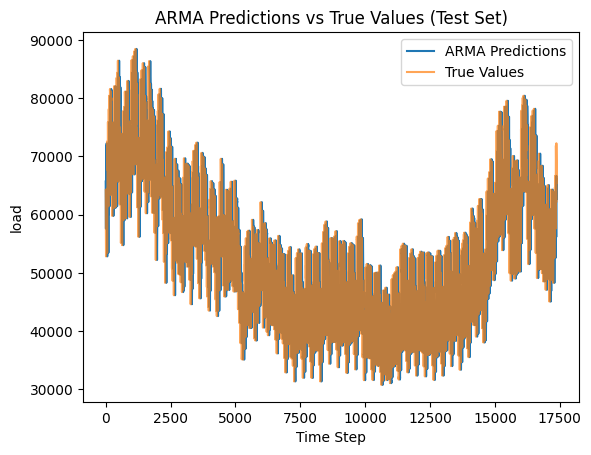

In [8]:
plt.plot(y_pred_arma_test, label='ARMA Predictions')
plt.plot(y_test_arima, label='True Values', alpha=0.7) 
plt.legend() 
plt.title("ARMA Predictions vs True Values (Test Set)") 
plt.xlabel("Time Step") 
plt.ylabel(target) 
plt.show()

## FF

Feed-forward network taking lagged consumption and calendar features as inputs. The global version trains a single shared model across all nodes; the local version trains one model per node.

In [7]:
config = f'configs/config_{DATASET}_ff.json'
with open(config, 'r') as f:
    config_dict = json.load(f)

In [8]:
def create_sequences(X, y, mode='train', horizon=48):
    if mode == 'train':
        X_seqs, y_seqs = [], []
        for i in range(len(X)-horizon+1):
            X_seqs.append(X[i])
            y_seqs.append(y[i:i+horizon])
    else:   
        X_seqs, y_seqs = [], []
        for i in range(len(X)-horizon+1):
            X_seqs.append(X[i])
            y_seqs.append(y[i:i+horizon])
    return np.stack(X_seqs), np.stack(y_seqs)

def fit_global_scaler(datasets_train):
    """
    Fit a global MinMaxScaler across ALL regions/nodes (only on TRAIN).

    Args:
        datasets_train (dict[node] = np.ndarray (n_samples, n_features)):
            Train datasets per node.

    Returns:
        MinMaxScaler fitted on all train data.
    """
    scaler = MinMaxScaler()
    all_train = np.concatenate([arr.reshape(-1, arr.shape[-1]) for arr in datasets_train.values()], axis=0)
    scaler.fit(all_train)
    return scaler


def scale_with_global(scaler, datasets):
    """
    Apply the fitted global scaler to datasets (dict of regions).

    Args:
        scaler (MinMaxScaler): fitted global scaler
        datasets (dict[node] = np.ndarray (n_samples, n_features)): data to transform

    Returns:
        dict[node] = scaled np.ndarray
    """
    scaled = {}
    for node, arr in datasets.items():
        scaled[node] = scaler.transform(arr.reshape(-1, arr.shape[-1]))
    return scaled

def plot_errors(err_train, err_val, err_test, metric="mape"):
    """
    Plot side-by-side bar charts of a chosen error metric for train, validation, and test splits.

    This function creates a 1x3 Matplotlib figure with a shared y-axis, where each subplot
    shows the per-node values of the specified error metric from the corresponding DataFrame.
    The DataFrame index is used as x-axis categories (nodes), and the y-axis label is the
    uppercased metric name. The figure layout is tightened and displayed immediately.

    Parameters
    ----------
    err_train : pandas.DataFrame
        DataFrame of node-level error metrics for the training split. Must contain a column
        named by `metric`; the index provides node labels.
    err_val : pandas.DataFrame
        DataFrame of node-level error metrics for the validation split. Must contain a column
        named by `metric`; the index provides node labels.
    err_test : pandas.DataFrame
        DataFrame of node-level error metrics for the test split. Must contain a column
        named by `metric`; the index provides node labels.
    metric : str, optional
        Name of the error metric column to plot (e.g., "mape", "mae", "rmse"), by default "mape".

    Returns
    -------
    None
        Displays the figure and does not return anything.
    """
    fig, axes = plt.subplots(1, 3, figsize=(15, 8), sharey=True)
    for ax, df, title in zip(axes, [err_train, err_val, err_test], ["Train", "Validation", "Test"]):
        df[metric].plot(kind="bar", ax=ax)
        ax.set_title(title)
        ax.set_xlabel("Node")
        ax.set_ylabel(metric.upper())
    plt.tight_layout()
    plt.show()

features = graph_dataset_train.features
target = graph_dataset_train.target
forecast_horizon = OUT_CHANNELS

def inv_transform_nodes(y_stacked, nodes, scaler_Y_node):
    """Inverse-transform (num_nodes * n_per_node, H) using per-node scalers."""
    n_per_node = y_stacked.shape[0] // len(nodes)
    result = np.zeros_like(y_stacked, dtype=float)
    for j, node in enumerate(nodes):
        result[j*n_per_node:(j+1)*n_per_node] = scaler_Y_node[node].inverse_transform(
            y_stacked[j*n_per_node:(j+1)*n_per_node]
        )
    return result

def eval_test_day_jump(preds, targets, horizon=OUT_CHANNELS):
    """Evaluate test metrics on non-overlapping origins (stride=horizon)."""
    p = np.asarray(preds)
    t = np.asarray(targets)
    if p.shape != t.shape:
        raise ValueError(f"Shape mismatch: preds={p.shape}, targets={t.shape}")

    if p.ndim == 1:
        # Already one prediction per instant (no overlapping windows)
        p_eval, t_eval = p, t
    elif p.ndim == 2:
        idx = np.arange(0, p.shape[0], horizon)
        p_eval = p[idx].reshape(-1)
        t_eval = t[idx].reshape(-1)
    else:
        raise ValueError(f"Unsupported ndim={p.ndim} for day-jump evaluation")

    rmse = RMSE(preds=p_eval, targets=t_eval)
    mape = 100 * MAPE(preds=p_eval, targets=t_eval)
    return rmse, mape


In [9]:
X_train_node = {node: [] for node in data.nodes}
y_train_node = {node: [] for node in data.nodes}
X_val_node = {node: [] for node in data.nodes}
y_val_node = {node: [] for node in data.nodes}
X_test_node = {node: [] for node in data.nodes}
y_test_node = {node: [] for node in data.nodes}

X_train_all = []
y_train_all = []

for node in data.nodes:
    train_r = data.df_train[data.df_train[data.node_var] == node].reset_index(drop=True)[features].values
    y_train_r = data.df_train[data.df_train[data.node_var] == node].reset_index(drop=True)[[target]].values

    X_train_all.append(train_r)
    y_train_all.append(y_train_r)

X_train_all = np.concatenate(X_train_all, axis=0)
y_train_all = np.concatenate(y_train_all, axis=0)

global_scalerX = MinMaxScaler().fit(X_train_all)  # global fallback
global_scalerY = MinMaxScaler().fit(y_train_all)  # global fallback

# Per-node scalers (nodewise + channelwise, as in the paper)
scaler_X_node = {}
scaler_Y_node = {}

for node in data.nodes:
    train_r = data.df_train[data.df_train[data.node_var] == node].reset_index(drop=True)[features].values
    val_r   = data.df_val[data.df_val[data.node_var] == node].reset_index(drop=True)[features].values
    test_r  = data.df_test[data.df_test[data.node_var] == node].reset_index(drop=True)[features].values

    y_train_r = data.df_train[data.df_train[data.node_var] == node].reset_index(drop=True)[[target]].values
    y_val_r   = data.df_val[data.df_val[data.node_var] == node].reset_index(drop=True)[[target]].values
    y_test_r  = data.df_test[data.df_test[data.node_var] == node].reset_index(drop=True)[[target]].values

    scaler_X_node[node] = MinMaxScaler().fit(train_r)
    scaler_Y_node[node] = MinMaxScaler().fit(y_train_r)

    train_r_scaled = scaler_X_node[node].transform(train_r)
    val_r_scaled   = scaler_X_node[node].transform(val_r)
    test_r_scaled  = scaler_X_node[node].transform(test_r)

    y_train_r_scaled = scaler_Y_node[node].transform(y_train_r)
    y_val_r_scaled   = scaler_Y_node[node].transform(y_val_r)
    y_test_r_scaled  = scaler_Y_node[node].transform(y_test_r)

    X_train_seq, y_train_seq = create_sequences(train_r_scaled, y_train_r_scaled, mode='train', horizon=forecast_horizon)
    X_val_seq, y_val_seq     = create_sequences(val_r_scaled, y_val_r_scaled, mode='test', horizon=forecast_horizon)
    X_test_seq, y_test_seq   = create_sequences(test_r_scaled, y_test_r_scaled, mode='test', horizon=forecast_horizon)

    X_train_node[node] = torch.tensor(X_train_seq, dtype=torch.float32).reshape(-1, len(features))
    y_train_node[node] = torch.tensor(y_train_seq, dtype=torch.float32).reshape(-1, forecast_horizon)
    X_val_node[node]   = torch.tensor(X_val_seq, dtype=torch.float32).reshape(-1, len(features))
    y_val_node[node]   = torch.tensor(y_val_seq, dtype=torch.float32).reshape(-1, forecast_horizon)
    X_test_node[node]  = torch.tensor(X_test_seq, dtype=torch.float32).reshape(-1, len(features))
    y_test_node[node]  = torch.tensor(y_test_seq, dtype=torch.float32).reshape(-1, forecast_horizon)


### Global (bottom)

A single FF model trained on the pooled data from all nodes. Node-level predictions are summed to obtain the aggregate forecast.

In [38]:
# Global Feed-Forward Neural Network — multi-seed training
# HPO is run ONCE (fixed rng=42) to select architecture/lr/batch_size.
# The final model is then trained FF_N_SEEDS times from different initialisations
# (seeds 42, 43, …) to produce mean ± std and best test metrics.

if TRAIN:
    import copy, time

    FF_N_SEEDS   = 5
    FF_BASE_SEED = 42

    print("\n" + "=" * 60)
    print("Training Global Feed-Forward Network (multi-seed)")
    print("=" * 60)

    num_nodes    = len(data.nodes)
    num_features = len(features)

    X_train_stacked = np.concatenate([X_train_node[node] for node in data.nodes], axis=0)
    y_train_stacked = np.concatenate([y_train_node[node] for node in data.nodes], axis=0)
    X_val_stacked   = np.concatenate([X_val_node[node]   for node in data.nodes], axis=0)
    y_val_stacked   = np.concatenate([y_val_node[node]   for node in data.nodes], axis=0)
    X_test_stacked  = np.concatenate([X_test_node[node]  for node in data.nodes], axis=0)
    y_test_stacked  = np.concatenate([y_test_node[node]  for node in data.nodes], axis=0)

    X_train_global_ff = torch.as_tensor(X_train_stacked, dtype=torch.float32)
    y_train_global_ff = torch.as_tensor(y_train_stacked, dtype=torch.float32).reshape(-1, OUT_CHANNELS)
    X_val_global_ff   = torch.as_tensor(X_val_stacked,   dtype=torch.float32)
    y_val_global_ff   = torch.as_tensor(y_val_stacked,   dtype=torch.float32).reshape(-1, OUT_CHANNELS)
    X_test_global_ff  = torch.as_tensor(X_test_stacked,  dtype=torch.float32)
    y_test_global_ff  = torch.as_tensor(y_test_stacked,  dtype=torch.float32).reshape(-1, OUT_CHANNELS)

    use_cuda = DEVICE.type == "cuda"
    use_mps  = DEVICE.type == "mps"
    use_gpu  = use_cuda or use_mps   # non_blocking + workers on both; pin_memory CUDA only

    # ------------------------------------------------------------------
    # HPO — run ONCE with fixed rng; selects global_ff_params
    # ------------------------------------------------------------------
    LIGHT_HPO_FF      = True
    FF_HPO_TRIALS     = 6
    FF_HPO_EPOCHS     = 5
    FF_HPO_TRAIN_MAX  = 120000
    FF_HPO_VAL_MAX    = 40000

    global_ff_params = {
        'hidden_channels': 300, 'num_layers': 3,
        'learning_rate': 1e-3,
        'batch_size': 2048 if use_gpu else 512,
        'n_epochs': 150, 'patience': 12,
    }

    if LIGHT_HPO_FF:
        print("\nRunning light FF HPO (once, rng=42)...")
        rng = np.random.default_rng(42)
        tr_idx = rng.choice(X_train_global_ff.shape[0],
                            size=min(FF_HPO_TRAIN_MAX, X_train_global_ff.shape[0]), replace=False)
        va_idx = rng.choice(X_val_global_ff.shape[0],
                            size=min(FF_HPO_VAL_MAX,   X_val_global_ff.shape[0]),   replace=False)
        Xtr_h = X_train_global_ff[tr_idx]
        ytr_h = y_train_global_ff[tr_idx]
        Xva_h = X_val_global_ff[va_idx].to(DEVICE, non_blocking=use_gpu)
        yva_h = y_val_global_ff[va_idx].to(DEVICE, non_blocking=use_gpu)

        cands = {
            'hidden_channels': [128, 192, 256, 320],
            'num_layers':      [2, 3],
            'learning_rate':   [3e-4, 1e-3, 2e-3],
            'batch_size':      [1024, 2048, 4096] if use_gpu else [256, 512, 1024],
        }
        best_cfg, best_rmse_hpo = None, float('inf')
        _hpo_loss = torch.nn.MSELoss().to(DEVICE)
        for t in range(FF_HPO_TRIALS):
            cfg = {k: int(rng.choice(v)) if k != 'learning_rate' else float(rng.choice(v))
                   for k, v in cands.items()}
            _m = FF(in_channels=num_features, num_layers=cfg['num_layers'],
                    hidden_channels=cfg['hidden_channels'], out_channels=OUT_CHANNELS).to(DEVICE)
            _opt = torch.optim.Adam(_m.parameters(), lr=cfg['learning_rate'])
            _ld  = torch.utils.data.DataLoader(
                torch.utils.data.TensorDataset(Xtr_h, ytr_h),
                shuffle=True, batch_size=cfg['batch_size'],
                num_workers=2 if use_gpu else 0, pin_memory=use_cuda, persistent_workers=use_gpu)
            _m.train()
            for _ in range(FF_HPO_EPOCHS):
                for xb, yb in _ld:
                    xb, yb = xb.to(DEVICE, non_blocking=use_gpu), yb.to(DEVICE, non_blocking=use_gpu)
                    _opt.zero_grad(set_to_none=True)
                    ls = _hpo_loss(_m(xb), yb); ls.backward(); _opt.step()
            _m.eval()
            with torch.no_grad():
                _v = torch.sqrt(_hpo_loss(_m(Xva_h), yva_h)).item()
            print(f"  Trial {t+1}/{FF_HPO_TRIALS} RMSE={_v:.6f} | {cfg}")
            if _v < best_rmse_hpo:
                best_rmse_hpo, best_cfg = _v, cfg
        global_ff_params.update(best_cfg)
        print(f"Selected: {best_cfg} (RMSE={best_rmse_hpo:.6f})")

    # ------------------------------------------------------------------
    # Multi-seed final training
    # ------------------------------------------------------------------
    nodes_list = list(data.nodes)
    val_x  = X_val_global_ff.to(DEVICE,  non_blocking=use_gpu)
    val_y  = y_val_global_ff.to(DEVICE,  non_blocking=use_gpu)
    test_x = X_test_global_ff.to(DEVICE, non_blocking=use_gpu)
    train_x = X_train_global_ff.to(DEVICE, non_blocking=use_gpu)
    _loss_fn = torch.nn.MSELoss().to(DEVICE)

    n_test_per_node  = X_test_global_ff.shape[0] // num_nodes
    n_train_per_node = X_train_global_ff.shape[0] // num_nodes

    _all_test_preds_glob  = []
    _ff_glob_test_rmses   = []
    _ff_glob_test_mapes   = []

    t0 = time.time()
    for _s in tqdm(range(FF_N_SEEDS), desc="FF global seeds"):
        seed_everything(FF_BASE_SEED + _s)

        _model = FF(in_channels=num_features,
                    num_layers=global_ff_params['num_layers'],
                    hidden_channels=global_ff_params['hidden_channels'],
                    out_channels=OUT_CHANNELS).to(DEVICE)
        _opt = torch.optim.Adam(_model.parameters(), lr=global_ff_params['learning_rate'])
        _ld  = torch.utils.data.DataLoader(
            torch.utils.data.TensorDataset(X_train_global_ff, y_train_global_ff),
            shuffle=True, batch_size=global_ff_params['batch_size'],
            num_workers=4 if use_gpu else 0, pin_memory=use_cuda,
            persistent_workers=use_gpu, drop_last=False)

        _best_val, _best_state, _no_imp = float('inf'), None, 0
        for epoch in range(global_ff_params['n_epochs']):
            _model.train()
            for xb, yb in _ld:
                xb, yb = xb.to(DEVICE, non_blocking=use_gpu), yb.to(DEVICE, non_blocking=use_gpu)
                _opt.zero_grad(set_to_none=True)
                _loss_fn(_model(xb), yb).backward(); _opt.step()
            _model.eval()
            with torch.no_grad():
                _vr = torch.sqrt(_loss_fn(_model(val_x), val_y)).item()
            if _vr < _best_val:
                _best_val, _best_state, _no_imp = _vr, copy.deepcopy(_model.state_dict()), 0
            else:
                _no_imp += 1
                if _no_imp >= global_ff_params['patience']: break

        _model.load_state_dict(_best_state); _model.eval()
        with torch.no_grad():
            _pred_test_sc  = _model(test_x).cpu().numpy()
            _pred_train_sc = _model(train_x).cpu().numpy()

        # inverse-transform per node, sum to national
        _p_te = _pred_test_sc.reshape(num_nodes, n_test_per_node, OUT_CHANNELS)
        _p_tr = _pred_train_sc.reshape(num_nodes, n_train_per_node, OUT_CHANNELS)
        _t_te = y_test_stacked.reshape(num_nodes, n_test_per_node, OUT_CHANNELS)
        _t_tr = y_train_stacked.reshape(num_nodes, n_train_per_node, OUT_CHANNELS)

        _p_te_inv = np.stack([scaler_Y_node[n].inverse_transform(_p_te[j]) for j,n in enumerate(nodes_list)])
        _t_te_inv = np.stack([scaler_Y_node[n].inverse_transform(_t_te[j]) for j,n in enumerate(nodes_list)])

        _nat_pred_te = _p_te_inv.sum(axis=0).ravel()
        _nat_true_te = _t_te_inv.sum(axis=0).ravel()

        _all_test_preds_glob.append(_nat_pred_te)
        _ff_glob_test_rmses.append(RMSE(preds=torch.as_tensor(_nat_pred_te),
                                        targets=torch.as_tensor(_nat_true_te)).item())
        _ff_glob_test_mapes.append(100 * MAPE(preds=torch.as_tensor(_nat_pred_te),
                                               targets=torch.as_tensor(_nat_true_te)).item())

    print(f"\nFF global ({FF_N_SEEDS} seeds, {time.time()-t0:.0f}s)")
    _rmse_g = np.array(_ff_glob_test_rmses); _mape_g = np.array(_ff_glob_test_mapes)
    print(f"  MAPE : {_mape_g.mean():.2f} \u00b1 {_mape_g.std():.2f}%   best={_mape_g.min():.2f}%")
    print(f"  RMSE : {_rmse_g.mean():.1f} \u00b1 {_rmse_g.std():.1f}   best={_rmse_g.min():.1f}")

    # keep mean prediction and single-run variables for downstream cells
    y_pred_test_ff  = np.mean(_all_test_preds_glob, axis=0)
    y_true_test_ff  = _nat_true_te
    ff_test_rmse    = RMSE(preds=torch.as_tensor(y_pred_test_ff), targets=torch.as_tensor(y_true_test_ff)).item()
    ff_test_mape    = 100 * MAPE(preds=torch.as_tensor(y_pred_test_ff), targets=torch.as_tensor(y_true_test_ff)).item()



Training Global Feed-Forward Network (multi-seed)

Running light FF HPO (once, rng=42)...
  Trial 1/6 RMSE=0.067692 | {'hidden_channels': 320, 'num_layers': 3, 'learning_rate': 0.0003, 'batch_size': 4096}
  Trial 2/6 RMSE=0.073696 | {'hidden_channels': 256, 'num_layers': 2, 'learning_rate': 0.0003, 'batch_size': 4096}
  Trial 3/6 RMSE=0.046805 | {'hidden_channels': 192, 'num_layers': 2, 'learning_rate': 0.0003, 'batch_size': 1024}
  Trial 4/6 RMSE=0.038197 | {'hidden_channels': 256, 'num_layers': 3, 'learning_rate': 0.002, 'batch_size': 1024}
  Trial 5/6 RMSE=0.053130 | {'hidden_channels': 320, 'num_layers': 2, 'learning_rate': 0.0003, 'batch_size': 2048}
  Trial 6/6 RMSE=0.041903 | {'hidden_channels': 256, 'num_layers': 3, 'learning_rate': 0.001, 'batch_size': 2048}
Selected: {'hidden_channels': 256, 'num_layers': 3, 'learning_rate': 0.002, 'batch_size': 1024} (RMSE=0.038197)


FF global seeds: 100%|██████████| 5/5 [06:00<00:00, 72.03s/it]


FF global (5 seeds, 360s)
  MAPE : 1.60 ± 0.03%   best=1.57%
  RMSE : 1363.5 ± 17.6   best=1339.1


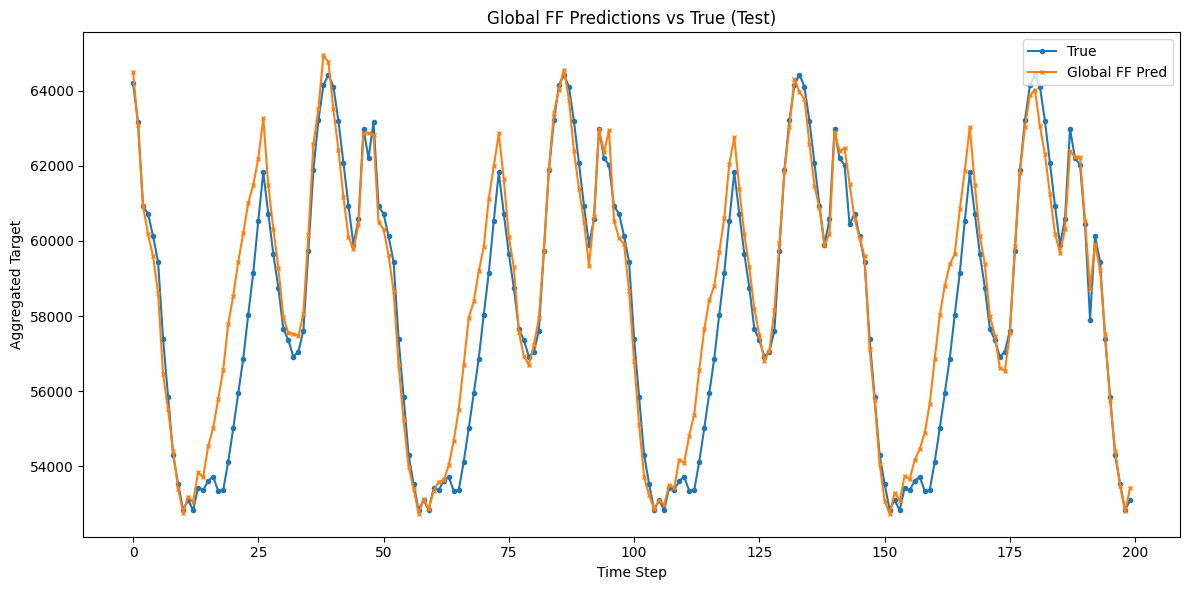

In [39]:
# Plot predictions for global FF
plt.figure(figsize=(12, 6))
plt.subplot(1, 1, 1)
plt.plot(y_true_test_ff[:200], label="True", marker='o', markersize=3)
plt.plot(y_pred_test_ff[:200], label="Global FF Pred", marker='x', markersize=3)
plt.title("Global FF Predictions vs True (Test)")
plt.xlabel("Time Step")
plt.ylabel("Aggregated Target")
plt.legend()
plt.tight_layout()
plt.show()

### Local (bottom)

One FF model per node. Predictions are aggregated bottom-up.

Local FF seeds: 100%|██████████| 5/5 [37:56<00:00, 455.35s/it]


FF local (5 seeds)
  MAPE : 1.53 ± 0.02%   best=1.50%
  RMSE : 1318.1 ± 9.1   best=1302.2


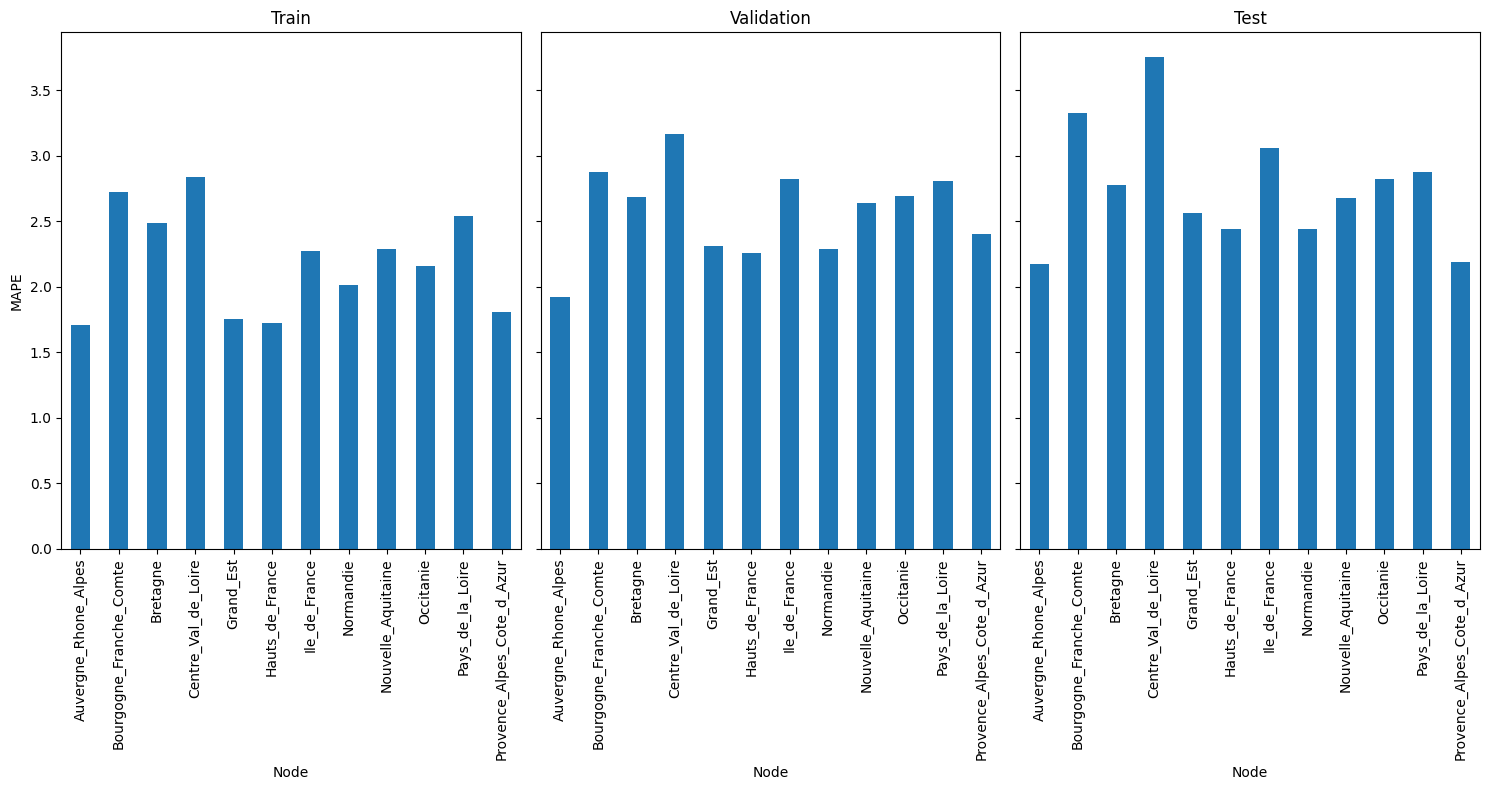

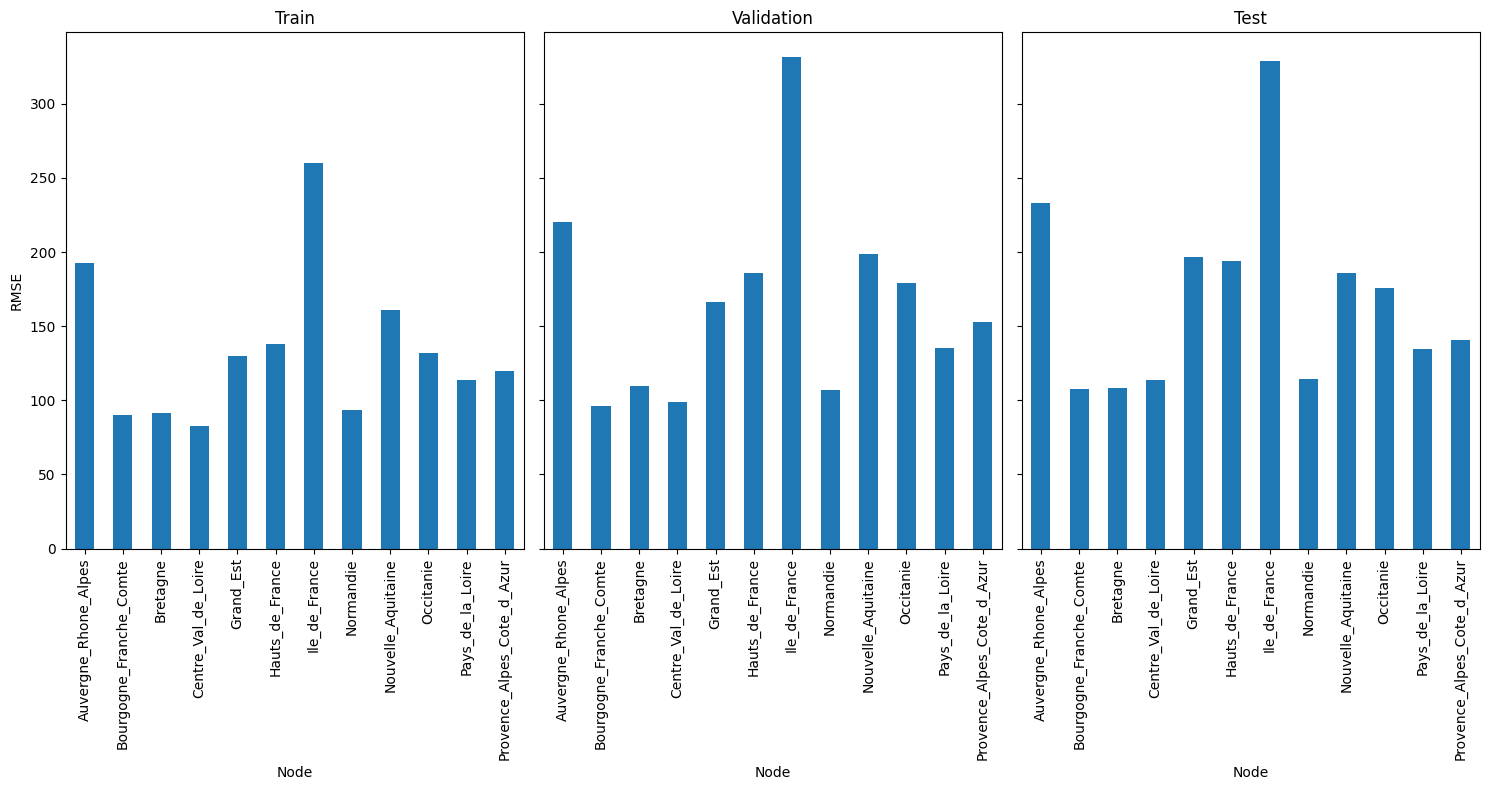

In [41]:
# Local Feed-Forward Neural Network — multi-seed training
# Phase 1: HPO per node (once, fixed rng=42) → best_params_per_node
# Phase 2: final training repeated FF_N_SEEDS times (seeds 42, 43, …)

n_epochs     = 150  # same as FF global: each local model iterates its dataset the same number of times
n_patience   = 12
FF_N_SEEDS   = 5
FF_BASE_SEED = 42

LIGHT_HPO_LOCAL_FF   = True
LOCAL_FF_HPO_TRIALS  = 3
LOCAL_FF_HPO_EPOCHS  = 3
LOCAL_FF_HPO_TRAIN_MAX = 20000
LOCAL_FF_HPO_VAL_MAX   = 6000

if DATASET == 'weave':
    nodes = [node for node in data.nodes if node != '06-06 st andrews road n/b_020-STOKE PLACE']
else:
    nodes = data.nodes

# ── Phase 1: HPO (once per node) ─────────────────────────────────────────────
best_params_per_node = {}

if TRAIN:
    rng = np.random.default_rng(FF_BASE_SEED)

    for region in tqdm(nodes, desc="Local FF HPO"):
        default_p = config_dict.get(region, {}).get('params', {
            'hidden_channels': 192, 'lr': 1e-3, 'num_layers': 2, 'batch_size': 512})
        hc  = int(default_p['hidden_channels'])
        lr  = float(default_p['lr'])
        nl  = int(default_p['num_layers'])
        bs  = int(default_p['batch_size'])

        X_tr = X_train_node[region].to(DEVICE)
        y_tr = y_train_node[region].to(DEVICE)
        X_va = X_val_node[region].to(DEVICE)
        y_va = y_val_node[region].to(DEVICE)

        if LIGHT_HPO_LOCAL_FF:
            tr_idx = torch.as_tensor(rng.choice(X_tr.shape[0],
                size=min(LOCAL_FF_HPO_TRAIN_MAX, X_tr.shape[0]), replace=False), device=DEVICE)
            va_idx = torch.as_tensor(rng.choice(X_va.shape[0],
                size=min(LOCAL_FF_HPO_VAL_MAX,   X_va.shape[0]), replace=False), device=DEVICE)
            Xtr_h, ytr_h = X_tr[tr_idx], y_tr[tr_idx]
            Xva_h, yva_h = X_va[va_idx], y_va[va_idx]

            cands = {'hidden_channels':[128,192,256], 'num_layers':[2,3],
                     'lr':[3e-4,1e-3,2e-3], 'batch_size':[256,512,1024]}
            best_cfg, best_rmse_h = None, float('inf')
            _hl = torch.nn.MSELoss().to(DEVICE)

            for _ in range(LOCAL_FF_HPO_TRIALS):
                cfg = {k: int(rng.choice(v)) if k != 'lr' else float(rng.choice(v))
                       for k, v in cands.items()}
                _m = FF(in_channels=X_tr.shape[-1], num_layers=cfg['num_layers'],
                        hidden_channels=cfg['hidden_channels'], out_channels=OUT_CHANNELS).to(DEVICE)
                _o = torch.optim.Adam(_m.parameters(), lr=cfg['lr'])
                _ld = torch.utils.data.DataLoader(
                    torch.utils.data.TensorDataset(Xtr_h, ytr_h),
                    shuffle=True, batch_size=cfg['batch_size'])
                _m.train()
                for _ in range(LOCAL_FF_HPO_EPOCHS):
                    for xb, yb in _ld:
                        yp = _m(xb.to(DEVICE)); ls = _hl(yp, yb.to(DEVICE))
                        _o.zero_grad(set_to_none=True); ls.backward(); _o.step()
                _m.eval()
                with torch.no_grad():
                    _v = np.sqrt(_hl(_m(Xva_h), yva_h).item())
                if _v < best_rmse_h:
                    best_rmse_h, best_cfg = _v, cfg

            if best_cfg:
                hc, lr, nl, bs = (best_cfg['hidden_channels'], best_cfg['lr'],
                                  best_cfg['num_layers'],     best_cfg['batch_size'])

        best_params_per_node[region] = {'hidden_channels':hc, 'lr':lr, 'num_layers':nl, 'batch_size':bs}

# ── Phase 2: multi-seed training ─────────────────────────────────────────────
results_train = {node: {} for node in nodes}
results_val   = {node: {} for node in nodes}
results_test  = {node: {} for node in nodes}
individual_preds_train = {}
individual_preds_val   = {}
individual_preds_test  = {}
individual_true_train  = {}
individual_true_val    = {}
individual_true_test   = {}

if TRAIN:
    _ff_loc_test_rmses = []
    _ff_loc_test_mapes = []

    for _s in tqdm(range(FF_N_SEEDS), desc="Local FF seeds"):
        seed_everything(FF_BASE_SEED + _s)
        _nat_pred, _nat_true = None, None

        for region in nodes:
            p   = best_params_per_node[region]
            X_tr = X_train_node[region].to(DEVICE)
            y_tr = y_train_node[region].to(DEVICE)
            X_va = X_val_node[region].to(DEVICE)
            y_va = y_val_node[region].to(DEVICE)
            X_te = X_test_node[region].to(DEVICE)
            y_te = y_test_node[region].to(DEVICE)
            scalerY = scaler_Y_node[region]

            model = FF(in_channels=X_tr.shape[-1], num_layers=p['num_layers'],
                       hidden_channels=p['hidden_channels'], out_channels=OUT_CHANNELS).to(DEVICE)
            optimizer = torch.optim.Adam(model.parameters(), lr=p['lr'])
            loss_fn   = torch.nn.MSELoss().to(DEVICE)
            loader    = torch.utils.data.DataLoader(
                torch.utils.data.TensorDataset(X_tr, y_tr),
                shuffle=True, batch_size=p['batch_size'])

            best_val_r, best_state, _no_imp = float('inf'), None, 0
            for _ in range(n_epochs):
                model.train()
                for xb, yb in loader:
                    yp = model(xb.float().to(DEVICE)); ls = loss_fn(yp, yb.to(DEVICE))
                    optimizer.zero_grad(set_to_none=True); ls.backward(); optimizer.step()
                model.eval()
                with torch.no_grad():
                    vr = np.sqrt(loss_fn(model(X_va), y_va).item())
                if vr < best_val_r:
                    best_val_r, best_state, _no_imp = vr, model.state_dict(), 0
                else:
                    _no_imp += 1
                    if _no_imp >= n_patience: break

            model.load_state_dict(best_state); model.eval()
            with torch.no_grad():
                p_te = scalerY.inverse_transform(model(X_te).cpu().detach().numpy())
                t_te = scalerY.inverse_transform(y_te.cpu().detach().numpy())

            _nat_pred = p_te.ravel() if _nat_pred is None else _nat_pred + p_te.ravel()
            _nat_true = t_te.ravel() if _nat_true is None else _nat_true + t_te.ravel()

            # store last seed's per-node results for downstream plotting
            if _s == FF_N_SEEDS - 1:
                individual_preds_test[region] = p_te
                individual_true_test[region]  = t_te
                with torch.no_grad():
                    p_tr = scalerY.inverse_transform(model(X_tr).cpu().detach().numpy())
                    t_tr = scalerY.inverse_transform(y_tr.cpu().detach().numpy())
                    p_va = scalerY.inverse_transform(model(X_va).cpu().detach().numpy())
                    t_va = scalerY.inverse_transform(y_va.cpu().detach().numpy())
                individual_preds_train[region] = p_tr; individual_true_train[region] = t_tr
                individual_preds_val[region]   = p_va; individual_true_val[region]   = t_va
                results_test[region]['mape']  = 100 * MAPE(preds=p_te, targets=t_te)
                results_test[region]['rmse']  = RMSE(preds=p_te, targets=t_te)
                results_train[region]['mape'] = 100 * MAPE(preds=p_tr, targets=t_tr)
                results_train[region]['rmse'] = RMSE(preds=p_tr, targets=t_tr)
                results_val[region]['mape']   = 100 * MAPE(preds=p_va, targets=t_va)
                results_val[region]['rmse']   = RMSE(preds=p_va, targets=t_va)

        _ff_loc_test_rmses.append(RMSE(preds=torch.as_tensor(_nat_pred),
                                       targets=torch.as_tensor(_nat_true)).item())
        _ff_loc_test_mapes.append(100 * MAPE(preds=torch.as_tensor(_nat_pred),
                                              targets=torch.as_tensor(_nat_true)).item())

    _rmse_l = np.array(_ff_loc_test_rmses); _mape_l = np.array(_ff_loc_test_mapes)
    print(f"\nFF local ({FF_N_SEEDS} seeds)")
    print(f"  MAPE : {_mape_l.mean():.2f} \u00b1 {_mape_l.std():.2f}%   best={_mape_l.min():.2f}%")
    print(f"  RMSE : {_rmse_l.mean():.1f} \u00b1 {_rmse_l.std():.1f}   best={_rmse_l.min():.1f}")

    err_train = pd.DataFrame(results_train).T
    err_val   = pd.DataFrame(results_val).T
    err_test  = pd.DataFrame(results_test).T
    plot_errors(err_train, err_val, err_test, "mape")
    plot_errors(err_train, err_val, err_test, "rmse")


In [ ]:
if TRAIN:
    total_preds_train, total_true_train = 0, 0
    total_preds_val, total_true_val = 0, 0
    total_preds_test, total_true_test = 0, 0
    for node in nodes:
        total_preds_train += individual_preds_train[node].ravel()
        total_true_train += individual_true_train[node].ravel()
        total_preds_val += individual_preds_val[node].ravel()
        total_true_val += individual_true_val[node].ravel()
        total_preds_test += individual_preds_test[node].ravel()
        total_true_test += individual_true_test[node].ravel()
    print(100*MAPE(preds=total_preds_train, targets=total_true_train), RMSE(preds=total_preds_train, targets=total_true_train))
    print(100*MAPE(preds=total_preds_val, targets=total_true_val), RMSE(preds=total_preds_val, targets=total_true_val))
    total_preds_test_mat = 0
    total_true_test_mat = 0
    for node in nodes:
        total_preds_test_mat += individual_preds_test[node]
        total_true_test_mat += individual_true_test[node]
    test_rmse = RMSE(preds=total_preds_test, targets=total_true_test)
    test_mape = 100 * MAPE(preds=total_preds_test, targets=total_true_test)
    print(test_mape, test_rmse)

6.850402 10009.602
5.7108173 10700.489
8.317019 15406.421


## XGBoost

Gradient-boosted trees using the same features as the FF baselines.

### Global (bottom)

A single XGBoost model trained on all nodes jointly.

#### Multi-output: $X_h \to y_h$ (H independent models)

In [11]:
import xgboost as xgb
from sklearn.multioutput import MultiOutputRegressor

XGB_N_SEEDS   = 5  # sufficient for tree models; variance is far smaller than SGD-based models
XGB_BASE_SEED = 42

print("\n" + "="*60)
print("XGBoost Global Baseline — multi-seed")
print("="*60)

# ── Data preparation ──────────────────────────────────────────────────────────
def _to_np(t):
    return t.cpu().numpy() if hasattr(t, 'cpu') else np.array(t)

X_train_stacked = np.concatenate([_to_np(X_train_node[n]) for n in data.nodes], axis=0)
y_train_stacked = np.concatenate([_to_np(y_train_node[n]) for n in data.nodes], axis=0)
X_val_stacked   = np.concatenate([_to_np(X_val_node[n])   for n in data.nodes], axis=0)
y_val_stacked   = np.concatenate([_to_np(y_val_node[n])   for n in data.nodes], axis=0)
X_test_stacked  = np.concatenate([_to_np(X_test_node[n])  for n in data.nodes], axis=0)
y_test_stacked  = np.concatenate([_to_np(y_test_node[n])  for n in data.nodes], axis=0)

num_nodes = len(data.nodes)
n_test_per_node = X_test_stacked.shape[0] // num_nodes

# ── HPO (once, rng=42) ───────────────────────────────────────────────────────
LIGHT_HPO_XGB   = True
XGB_HPO_TRIALS  = 10
XGB_HPO_TRAIN_MAX = 120000
XGB_HPO_VAL_MAX   = 40000

xgb_params = {
    'objective': 'reg:squarederror', 'learning_rate': 0.1, 'max_depth': 10,
    'min_child_weight': 9.886189229106565, 'subsample': 0.8929644165419383,
    'colsample_bytree': 0.6933420681040697, 'reg_alpha': 0.0014783970830547111,
    'reg_lambda': 0.11800510269452669, 'n_estimators': 280, 'tree_method': 'hist',
}

if LIGHT_HPO_XGB:
    print("\nRunning XGBoost HPO (once, rng=42)...")
    rng = np.random.default_rng(42)
    tr_idx = rng.choice(X_train_stacked.shape[0],
                        size=min(XGB_HPO_TRAIN_MAX, X_train_stacked.shape[0]), replace=False)
    va_idx = rng.choice(X_val_stacked.shape[0],
                        size=min(XGB_HPO_VAL_MAX, X_val_stacked.shape[0]),   replace=False)
    tune_ch = OUT_CHANNELS // 2
    Xtr_h, ytr_h = X_train_stacked[tr_idx], y_train_stacked[tr_idx, tune_ch]
    Xva_h, yva_h = X_val_stacked[va_idx],   y_val_stacked[va_idx, tune_ch]

    best_rmse_hpo, best_cfg = float('inf'), None
    for t in range(XGB_HPO_TRIALS):
        cfg = {
            'learning_rate':    float(rng.choice([0.03, 0.05, 0.1, 0.2])),
            'max_depth':        int(rng.choice([4, 6, 8, 10])),
            'min_child_weight': float(rng.choice([1.0, 3.0, 6.0, 10.0])),
            'subsample':        float(rng.choice([0.7, 0.85, 1.0])),
            'colsample_bytree': float(rng.choice([0.6, 0.8, 1.0])),
            'reg_alpha':        float(rng.choice([0.0, 1e-4, 1e-3, 1e-2])),
            'reg_lambda':       float(rng.choice([0.1, 1.0, 5.0, 10.0])),
            'n_estimators':     int(rng.choice([120, 180, 260, 340])),
        }
        _m = xgb.XGBRegressor(objective='reg:squarederror', tree_method='hist',
                               random_state=42, **cfg)
        _m.fit(Xtr_h, ytr_h, eval_set=[(Xva_h, yva_h)], verbose=False)
        _v = float(np.sqrt(np.mean((_m.predict(Xva_h) - yva_h)**2)))
        print(f"  Trial {t+1}/{XGB_HPO_TRIALS} RMSE={_v:.6f} | {cfg}")
        if _v < best_rmse_hpo:
            best_rmse_hpo, best_cfg = _v, cfg
    xgb_params.update(best_cfg)
    print(f"Selected: {best_cfg} (RMSE={best_rmse_hpo:.6f})")

# ── Multi-seed training ───────────────────────────────────────────────────────
_xgb_glob_rmses, _xgb_glob_mapes = [], []
_xgb_glob_test_preds = []

for _s in tqdm(range(XGB_N_SEEDS), desc="XGB global seeds"):
    _params_s = {**xgb_params, 'random_state': XGB_BASE_SEED + _s}
    _model = MultiOutputRegressor(xgb.XGBRegressor(**_params_s), n_jobs=-1)
    _model.fit(X_train_stacked, y_train_stacked)

    _p_te = _model.predict(X_test_stacked)
    _p_te_inv = inv_transform_nodes(_p_te, data.nodes, scaler_Y_node)
    _t_te_inv = inv_transform_nodes(y_test_stacked, data.nodes, scaler_Y_node)

    _nat_pred = _p_te_inv.reshape(num_nodes, n_test_per_node, OUT_CHANNELS).sum(axis=0).ravel()
    _nat_true = _t_te_inv.reshape(num_nodes, n_test_per_node, OUT_CHANNELS).sum(axis=0).ravel()

    _xgb_glob_test_preds.append(_nat_pred)
    _xgb_glob_rmses.append(RMSE(preds=torch.as_tensor(_nat_pred),
                                targets=torch.as_tensor(_nat_true)).item())
    _xgb_glob_mapes.append(100 * MAPE(preds=torch.as_tensor(_nat_pred),
                                      targets=torch.as_tensor(_nat_true)).item())

_rg = np.array(_xgb_glob_rmses); _mg = np.array(_xgb_glob_mapes)
print(f"\nXGBoost global ({XGB_N_SEEDS} seeds)")
print(f"  MAPE : {_mg.mean():.2f} \u00b1 {_mg.std():.2f}%   best={_mg.min():.2f}%")
print(f"  RMSE : {_rg.mean():.1f} \u00b1 {_rg.std():.1f}   best={_rg.min():.1f}")

# keep last-seed aggregates for downstream cells
y_pred_test_agg   = _xgb_glob_test_preds[-1]
y_true_test_agg   = _nat_true
xgb_alt_test_rmse = _xgb_glob_rmses[-1]
xgb_alt_test_mape = _xgb_glob_mapes[-1]



XGBoost Global Baseline — multi-seed

Running XGBoost HPO (once, rng=42)...
  Trial 1/10 RMSE=0.144488 | {'learning_rate': 0.03, 'max_depth': 6, 'min_child_weight': 6.0, 'subsample': 0.85, 'colsample_bytree': 1.0, 'reg_alpha': 0.01, 'reg_lambda': 5.0, 'n_estimators': 260}
  Trial 2/10 RMSE=0.147509 | {'learning_rate': 0.05, 'max_depth': 10, 'min_child_weight': 6.0, 'subsample': 0.7, 'colsample_bytree': 1.0, 'reg_alpha': 0.0001, 'reg_lambda': 1.0, 'n_estimators': 180}
  Trial 3/10 RMSE=0.154085 | {'learning_rate': 0.2, 'max_depth': 6, 'min_child_weight': 3.0, 'subsample': 0.7, 'colsample_bytree': 0.8, 'reg_alpha': 0.0, 'reg_lambda': 5.0, 'n_estimators': 340}
  Trial 4/10 RMSE=0.147073 | {'learning_rate': 0.05, 'max_depth': 10, 'min_child_weight': 10.0, 'subsample': 0.7, 'colsample_bytree': 0.8, 'reg_alpha': 0.001, 'reg_lambda': 1.0, 'n_estimators': 340}
  Trial 5/10 RMSE=0.144022 | {'learning_rate': 0.05, 'max_depth': 4, 'min_child_weight': 6.0, 'subsample': 0.7, 'colsample_bytree': 0.

XGB global seeds: 100%|██████████| 5/5 [00:15<00:00,  3.06s/it]


XGBoost global (5 seeds)
  MAPE : 7.56 ± 0.01%   best=7.55%
  RMSE : 13938.5 ± 20.9   best=13917.5


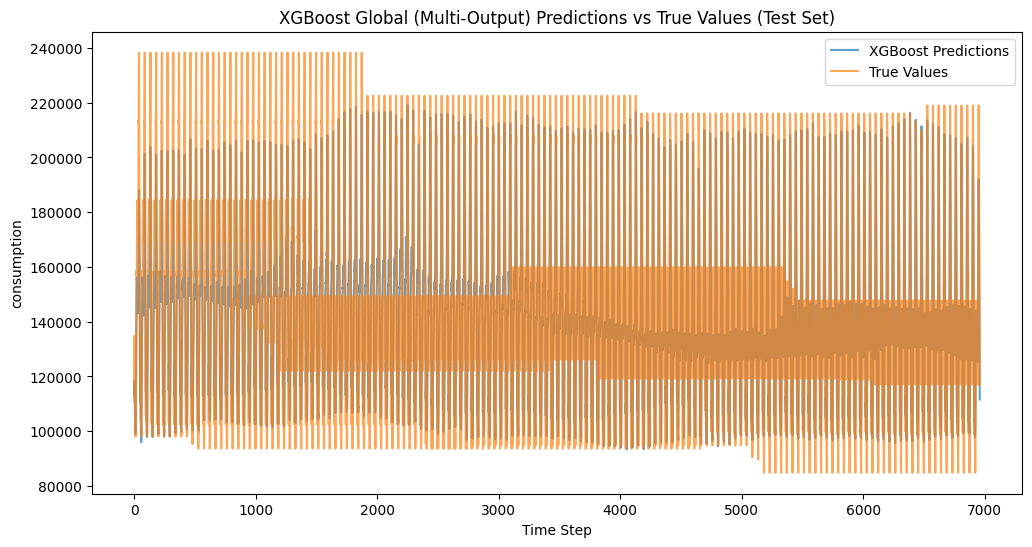

In [12]:
# Plot predictions vs true values for test set
plt.figure(figsize=(12, 6))
plt.plot(y_pred_test_agg, label='XGBoost Predictions', alpha=0.7)
plt.plot(y_true_test_agg, label='True Values', alpha=0.7)
plt.legend()
plt.title("XGBoost Global (Multi-Output) Predictions vs True Values (Test Set)")
plt.xlabel("Time Step")
plt.ylabel(target)
plt.show()

##### Top-down

In [13]:
# from sklearn.preprocessing import StandardScaler


# def add_horizon_feature_only(X, y):
#     """Expand (N, F)->(N*H, F+1) with normalized horizon index."""
#     N, F = X.shape
#     H = y.shape[1]
#     X_rep = np.repeat(X, H, axis=0)
#     h = np.tile(np.arange(H), N).reshape(-1, 1).astype(np.float32)
#     h_norm = h / H
#     X_new = np.concatenate([X_rep, h_norm], axis=1)
#     y_new = y.reshape(-1)
#     return X_new, y_new


# # Build TOP targets in original scale, then scale with a dedicated top scaler
# num_nodes = len(data.nodes)

# # Shapes from stacked node-level data
# n_train_per_node = y_train_stacked.shape[0] // num_nodes
# n_val_per_node = y_val_stacked.shape[0] // num_nodes
# n_test_per_node = y_test_stacked.shape[0] // num_nodes

# # Node-level targets back to original scale
# # Per-node inverse transform (nodewise normalisation per paper)
# y_train_nodes_inv = inv_transform_nodes(y_train_stacked, data.nodes, scaler_Y_node).reshape(num_nodes, n_train_per_node, OUT_CHANNELS)
# y_val_nodes_inv = inv_transform_nodes(y_val_stacked, data.nodes, scaler_Y_node).reshape(num_nodes, n_val_per_node, OUT_CHANNELS)
# y_test_nodes_inv = inv_transform_nodes(y_test_stacked, data.nodes, scaler_Y_node).reshape(num_nodes, n_test_per_node, OUT_CHANNELS)

# # Top-level targets: aggregate across nodes -> (T, H)
# y_train_top = y_train_nodes_inv.sum(axis=0)
# y_val_top = y_val_nodes_inv.sum(axis=0)
# y_test_top = y_test_nodes_inv.sum(axis=0)

# # Scale top targets with train-only statistics
# top_scalerY = StandardScaler()
# y_train_top_scaled = top_scalerY.fit_transform(y_train_top)
# y_val_top_scaled = top_scalerY.transform(y_val_top)
# y_test_top_scaled = top_scalerY.transform(y_test_top)

# def build_global_features(X_nodes, num_nodes):
#     X_nodes = X_nodes.reshape(num_nodes, -1, X_nodes.shape[1])
#     # Global top-level covariates: mean over nodes for each timestamp
#     return X_nodes.mean(axis=0)

# X_train_global = build_global_features(X_train_stacked, num_nodes)
# X_val_global = build_global_features(X_val_stacked, num_nodes)
# X_test_global = build_global_features(X_test_stacked, num_nodes)

# X_train_top_h, y_train_top_h = add_horizon_feature_only(X_train_global, y_train_top_scaled)
# X_val_top_h, y_val_top_h = add_horizon_feature_only(X_val_global, y_val_top_scaled)
# X_test_top_h, y_test_top_h = add_horizon_feature_only(X_test_global, y_test_top_scaled)

# print("\n" + "=" * 60)
# print("XGBoost TOP (direct)")
# print("=" * 60)

# # Very light HPO for top-down model
# LIGHT_HPO_XGB_TOP = True
# XGB_TOP_HPO_TRIALS = 10
# XGB_TOP_HPO_TRAIN_MAX = 150000
# XGB_TOP_HPO_VAL_MAX = 50000

# xgb_top_params = {
#     'objective': 'reg:squarederror',
#     'learning_rate': 0.05,
#     'max_depth': 6,
#     'min_child_weight': 5,
#     'subsample': 0.9,
#     'colsample_bytree': 0.8,
#     'reg_alpha': 1e-3,
#     'reg_lambda': 1.0,
#     'n_estimators': 600,
#     'tree_method': 'hist',
#     'random_state': 42,
# }

# if LIGHT_HPO_XGB_TOP:
#     rng = np.random.default_rng(42)
#     tr_idx = rng.choice(X_train_top_h.shape[0], size=min(XGB_TOP_HPO_TRAIN_MAX, X_train_top_h.shape[0]), replace=False)
#     va_idx = rng.choice(X_val_top_h.shape[0], size=min(XGB_TOP_HPO_VAL_MAX, X_val_top_h.shape[0]), replace=False)

#     Xtr_hpo, ytr_hpo = X_train_top_h[tr_idx], y_train_top_h[tr_idx]
#     Xva_hpo, yva_hpo = X_val_top_h[va_idx], y_val_top_h[va_idx]

#     best_rmse = float('inf')
#     best_cfg = None

#     for t in range(XGB_TOP_HPO_TRIALS):
#         cfg = {
#             'learning_rate': float(rng.choice([0.03, 0.05, 0.1, 0.2])),
#             'max_depth': int(rng.choice([4, 6, 8])),
#             'min_child_weight': float(rng.choice([1.0, 3.0, 6.0, 10.0])),
#             'subsample': float(rng.choice([0.7, 0.85, 1.0])),
#             'colsample_bytree': float(rng.choice([0.6, 0.8, 1.0])),
#             'reg_alpha': float(rng.choice([0.0, 1e-4, 1e-3, 1e-2])),
#             'reg_lambda': float(rng.choice([0.1, 1.0, 5.0, 10.0])),
#             'n_estimators': int(rng.choice([160, 260, 360, 500])),
#         }

#         model_hpo = xgb.XGBRegressor(
#             objective='reg:squarederror',
#             tree_method='hist',
#             random_state=42,
#             **cfg,
#         )
#         model_hpo.fit(Xtr_hpo, ytr_hpo, eval_set=[(Xva_hpo, yva_hpo)], verbose=False)
#         pred_va = model_hpo.predict(Xva_hpo)
#         rmse_va = float(np.sqrt(np.mean((pred_va - yva_hpo) ** 2)))
#         if rmse_va < best_rmse:
#             best_rmse = rmse_va
#             best_cfg = cfg

#     if best_cfg is not None:
#         xgb_top_params.update(best_cfg)
#         print(f"Selected XGB TOP params from light HPO: {best_cfg} (RMSE={best_rmse:.6f})")

# xgb_top = xgb.XGBRegressor(**xgb_top_params)
# xgb_top.fit(
#     X_train_top_h,
#     y_train_top_h,
#     eval_set=[(X_val_top_h, y_val_top_h)],
#     verbose=False,
# )

# def predict_multi_top(model, X_global, H):
#     N = X_global.shape[0]
#     X_rep = np.repeat(X_global, H, axis=0)
#     h = np.tile(np.arange(H), N).reshape(-1, 1).astype(np.float32)
#     h_norm = h / H
#     X_h = np.concatenate([X_rep, h_norm], axis=1)
#     preds = model.predict(X_h)
#     return preds.reshape(N, H)

# # Predict directly at TOP level (T, H)
# y_pred_train_top_scaled = predict_multi_top(xgb_top, X_train_global, OUT_CHANNELS)
# y_pred_val_top_scaled = predict_multi_top(xgb_top, X_val_global, OUT_CHANNELS)
# y_pred_test_top_scaled = predict_multi_top(xgb_top, X_test_global, OUT_CHANNELS)

# # Back to original MW scale
# y_pred_train_top = top_scalerY.inverse_transform(y_pred_train_top_scaled)
# y_pred_val_top = top_scalerY.inverse_transform(y_pred_val_top_scaled)
# y_pred_test_top = top_scalerY.inverse_transform(y_pred_test_top_scaled)

# # Flatten for metric computation over all horizons and timestamps
# y_pred_train_h_top_agg = y_pred_train_top.ravel()
# y_pred_val_h_top_agg = y_pred_val_top.ravel()
# y_pred_test_h_top_agg = y_pred_test_top.ravel()

# y_true_train_h_top_agg = y_train_top.ravel()
# y_true_val_h_top_agg = y_val_top.ravel()
# y_true_test_h_top_agg = y_test_top.ravel()

# xgb_h_top_train_rmse = RMSE(preds=y_pred_train_h_top_agg, targets=y_true_train_h_top_agg)
# xgb_h_top_train_mape = 100 * MAPE(preds=y_pred_train_h_top_agg, targets=y_true_train_h_top_agg)
# xgb_h_top_val_rmse = RMSE(preds=y_pred_val_h_top_agg, targets=y_true_val_h_top_agg)
# xgb_h_top_val_mape = 100 * MAPE(preds=y_pred_val_h_top_agg, targets=y_true_val_h_top_agg)
# xgb_h_top_test_rmse = RMSE(preds=y_pred_test_top.ravel(), targets=y_test_top.ravel())
# xgb_h_top_test_mape = 100 * MAPE(preds=y_pred_test_top.ravel(), targets=y_test_top.ravel())

# print(f"\nXGBoost TOP (direct) | Train: RMSE={xgb_h_top_train_rmse:.4f}, MAPE={xgb_h_top_train_mape:.4f}%")
# print(f"XGBoost TOP (direct) | Val:   RMSE={xgb_h_top_val_rmse:.4f}, MAPE={xgb_h_top_val_mape:.4f}%")
# print(f"XGBoost TOP (direct) | Test:  RMSE={xgb_h_top_test_rmse:.4f}, MAPE={xgb_h_top_test_mape:.4f}%")

### Local (bottom)

One XGBoost model per node, aggregated bottom-up.

In [14]:
# XGBoost Local Baseline — multi-seed training
# HPO is run ONCE per node (fixed rng=42); random_state is varied across seeds.
# 5 seeds suffice: XGBoost tree variance is far smaller than SGD-based models.

XGB_N_SEEDS   = 1
XGB_BASE_SEED = 42

LIGHT_HPO_XGB_LOCAL   = True
XGB_LOCAL_HPO_TRIALS  = 4
XGB_LOCAL_HPO_TRAIN_MAX = 25000
XGB_LOCAL_HPO_VAL_MAX   = 8000

print("\n" + "="*60)
print("XGBoost Local Baseline — multi-seed")
print("="*60)

xgb_local_default = {
    'objective': 'reg:squarederror', 'learning_rate': 0.1, 'max_depth': 10,
    'min_child_weight': 9.886189229106565, 'subsample': 0.8929644165419383,
    'colsample_bytree': 0.6933420681040697, 'reg_alpha': 0.0014783970830547111,
    'reg_lambda': 0.11800510269452669, 'n_estimators': 280, 'tree_method': 'hist',
}

# ── Precompute node arrays once (reused across HPO and all seeds) ─────────────
node_arrays = {}
for node in data.nodes:
    node_arrays[node] = {
        'x_tr': _to_np(X_train_node[node]), 'y_tr': _to_np(y_train_node[node]),
        'x_va': _to_np(X_val_node[node]),   'y_va': _to_np(y_val_node[node]),
        'x_te': _to_np(X_test_node[node]),  'y_te': _to_np(y_test_node[node]),
    }

# ── Phase 1: HPO per node (once, rng=42) ─────────────────────────────────────
best_params_xgb_local = {}
rng = np.random.default_rng(XGB_BASE_SEED)

for node in tqdm(data.nodes, desc="XGB local HPO"):
    a = node_arrays[node]
    x_tr, y_tr, x_va, y_va = a['x_tr'], a['y_tr'], a['x_va'], a['y_va']

    node_params = dict(xgb_local_default)
    if LIGHT_HPO_XGB_LOCAL:
        tr_idx = rng.choice(x_tr.shape[0], size=min(XGB_LOCAL_HPO_TRAIN_MAX, x_tr.shape[0]), replace=False)
        va_idx = rng.choice(x_va.shape[0], size=min(XGB_LOCAL_HPO_VAL_MAX,   x_va.shape[0]), replace=False)
        tune_ch = y_tr.shape[1] // 2
        xtr_h, ytr_h = x_tr[tr_idx], y_tr[tr_idx, tune_ch]
        xva_h, yva_h = x_va[va_idx], y_va[va_idx, tune_ch]

        best_rmse_h, best_cfg = float('inf'), None
        for _ in range(XGB_LOCAL_HPO_TRIALS):
            cfg = {
                'learning_rate':    float(rng.choice([0.03, 0.05, 0.1, 0.2])),
                'max_depth':        int(rng.choice([4, 6, 8, 10])),
                'min_child_weight': float(rng.choice([1.0, 3.0, 6.0, 10.0])),
                'subsample':        float(rng.choice([0.7, 0.85, 1.0])),
                'colsample_bytree': float(rng.choice([0.6, 0.8, 1.0])),
                'reg_alpha':        float(rng.choice([0.0, 1e-4, 1e-3, 1e-2])),
                'reg_lambda':       float(rng.choice([0.1, 1.0, 5.0, 10.0])),
                'n_estimators':     int(rng.choice([120, 180, 260, 340])),
            }
            _m = xgb.XGBRegressor(objective='reg:squarederror', tree_method='hist',
                                   random_state=42, **cfg)
            _m.fit(xtr_h, ytr_h, eval_set=[(xva_h, yva_h)], verbose=False)
            _v = float(np.sqrt(np.mean((_m.predict(xva_h) - yva_h)**2)))
            if _v < best_rmse_h:
                best_rmse_h, best_cfg = _v, cfg
        if best_cfg:
            node_params.update(best_cfg)

    best_params_xgb_local[node] = node_params

# ── Phase 2: multi-seed training ─────────────────────────────────────────────
_xgb_loc_rmses, _xgb_loc_mapes = [], []
local_xgb_preds_test = {}
local_xgb_true_test  = {}

for _s in tqdm(range(XGB_N_SEEDS), desc="XGB local seeds"):
    _nat_pred, _nat_true = None, None

    for node in data.nodes:
        a = node_arrays[node]
        _params_s = {**best_params_xgb_local[node], 'random_state': XGB_BASE_SEED + _s}
        _model = MultiOutputRegressor(xgb.XGBRegressor(**_params_s), n_jobs=-1)
        _model.fit(a['x_tr'], a['y_tr'])

        p_te = scaler_Y_node[node].inverse_transform(_model.predict(a['x_te']))
        t_te = scaler_Y_node[node].inverse_transform(a['y_te'])

        _nat_pred = p_te.ravel() if _nat_pred is None else _nat_pred + p_te.ravel()
        _nat_true = t_te.ravel() if _nat_true is None else _nat_true + t_te.ravel()

        if _s == XGB_N_SEEDS - 1:
            local_xgb_preds_test[node] = p_te
            local_xgb_true_test[node]  = t_te

    _xgb_loc_rmses.append(RMSE(preds=torch.as_tensor(_nat_pred),
                                targets=torch.as_tensor(_nat_true)).item())
    _xgb_loc_mapes.append(100 * MAPE(preds=torch.as_tensor(_nat_pred),
                                      targets=torch.as_tensor(_nat_true)).item())

_rl = np.array(_xgb_loc_rmses); _ml = np.array(_xgb_loc_mapes)
print(f"\nXGBoost local ({XGB_N_SEEDS} seeds)")
print(f"  MAPE : {_ml.mean():.2f} \u00b1 {_ml.std():.2f}%   best={_ml.min():.2f}%")
print(f"  RMSE : {_rl.mean():.1f} \u00b1 {_rl.std():.1f}   best={_rl.min():.1f}")

xgb_local_pred_test_agg = _nat_pred
xgb_local_true_test_agg = _nat_true
xgb_local_test_rmse = _xgb_loc_rmses[-1]
xgb_local_test_mape = _xgb_loc_mapes[-1]



XGBoost Local Baseline — multi-seed


XGB local seeds:   0%|          | 0/1 [00:00<?, ?it/s]/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
XGB local seeds: 100%|██████████| 1/1 [01:12<00:00, 72.24s/it]


XGBoost local (1 seeds)
  MAPE : 8.80 ± 0.00%   best=8.80%
  RMSE : 20316.7 ± 0.0   best=20316.7


In [20]:
xgb_local_test_rmse = RMSE(preds=xgb_local_pred_test_agg, targets=xgb_local_true_test_agg)
xgb_local_test_mape = 100 * MAPE(preds=xgb_local_pred_test_agg, targets=xgb_local_true_test_agg)
print(f"XGBoost Local | Test:  RMSE={xgb_local_test_rmse:.4f}, MAPE={xgb_local_test_mape:.4f}%")

XGBoost Local | Test:  RMSE=1517.1361, MAPE=1.7660%


## Chronos-v2 (strict, bottom-global)

Foundation-model baseline using rolling forecasts over the 48-step horizon.

- **Bottom-global only**: forecast the aggregated load series.
- **Strict mode**: this section requires Chronos-v2 models and does not fall back to v1.

In [21]:
# Chronos-v2 baseline (strict v2 only, bottom-global)
print("\n" + "=" * 60)
print("Chronos-v2 Baseline (bottom-global)")
print("=" * 60)

import importlib
import subprocess
import sys
import time

CHRONOS_V2_SPECS = [
    ("bolt", "amazon/chronos-bolt-small"),  # Lighter model first
    ("chronos2", "amazon/chronos-2"),
]
CHRONOS_PRED_LEN = OUT_CHANNELS
AUTO_FIX_CHRONOS_V2 = True


def _fresh_import_v2_classes():
    """Import Chronos v2 pipeline classes from current site-packages."""
    for k in list(sys.modules.keys()):
        if k == "chronos" or k.startswith("chronos."):
            del sys.modules[k]
    importlib.invalidate_caches()

    from chronos.chronos2 import Chronos2Pipeline
    from chronos.chronos_bolt import ChronosBoltPipeline
    return Chronos2Pipeline, ChronosBoltPipeline


def _load_first_available_v2(Chronos2Pipeline, ChronosBoltPipeline):
    errs = []
    for kind, mid in CHRONOS_V2_SPECS:
        try:
            if kind == "chronos2":
                pipe = Chronos2Pipeline.from_pretrained(mid)
            elif kind == "bolt":
                pipe = ChronosBoltPipeline.from_pretrained(mid)
            else:
                raise ValueError(f"Unknown Chronos v2 kind: {kind}")
            return pipe, kind, mid, errs
        except Exception as err:
            errs.append((kind, mid, str(err)))
    return None, None, None, errs


def _predict_horizon_v2(pipeline, kind, history_1d, pred_len):
    """Predict one full horizon from a 1D history array."""
    ctx = torch.as_tensor(history_1d, dtype=torch.float32).unsqueeze(0)

    if kind == "chronos2":
        # Chronos2 expects (n_series, n_variates, history_length)
        ctx = ctx.unsqueeze(1)
        out = pipeline.predict(ctx, prediction_length=pred_len)
        out_t = torch.as_tensor(out[0] if isinstance(out, list) else out)
    else:
        out_t = torch.as_tensor(pipeline.predict(ctx, prediction_length=pred_len))

    if out_t.ndim == 3:
        pred = out_t[0].median(dim=0).values.detach().cpu().numpy()
    elif out_t.ndim == 2:
        pred = out_t[0].detach().cpu().numpy() if out_t.shape[0] == 1 else out_t.median(dim=0).values.detach().cpu().numpy()
    else:
        pred = out_t.detach().cpu().numpy().reshape(-1)[:pred_len]

    return pred.astype(np.float32)


# 1) Try current environment
chronos_pipeline = None
chronos_model_kind = None
chronos_model_used = None
chronos_is_v2 = False

try:
    Chronos2Pipeline, ChronosBoltPipeline = _fresh_import_v2_classes()
    chronos_pipeline, chronos_model_kind, chronos_model_used, v2_errs = _load_first_available_v2(
        Chronos2Pipeline,
        ChronosBoltPipeline,
    )
except Exception as err:
    v2_errs = [("import", "chronos-v2", str(err))]

if chronos_pipeline is None:
    for kind, mid, msg in v2_errs:
        print(f"Could not load {mid} ({kind}): {msg}")

    mismatch = any("unexpected keyword argument 'input_patch_size'" in msg for _, _, msg in v2_errs)
    if AUTO_FIX_CHRONOS_V2 and mismatch:
        print("Detected Chronos-v2 config mismatch. Installing latest Chronos from GitHub...")
        try:
            subprocess.check_call([
                sys.executable,
                "-m",
                "pip",
                "install",
                "-q",
                "-U",
                "git+https://github.com/amazon-science/chronos-forecasting.git",
            ])
            Chronos2Pipeline, ChronosBoltPipeline = _fresh_import_v2_classes()
            chronos_pipeline, chronos_model_kind, chronos_model_used, v2_errs_retry = _load_first_available_v2(
                Chronos2Pipeline,
                ChronosBoltPipeline,
            )
            if chronos_pipeline is None:
                for kind, mid, msg in v2_errs_retry:
                    print(f"Could not load {mid} ({kind}) after GitHub install: {msg}")
        except Exception as err:
            print(f"Chronos-v2 auto-fix failed: {err}")

if chronos_pipeline is None:
    raise RuntimeError(
        "Chronos-v2 could not be loaded. This baseline is strict v2-only and will not fall back to v1."
    )

chronos_is_v2 = True
print(f"Loaded Chronos-v2 model: {chronos_model_used} ({chronos_model_kind})")

# Build aggregated top series in original scale
df_train = graph_dataset_train.dataframe.pivot(
    index='date',
    columns=graph_dataset_train.data.node_var,
    values=graph_dataset_train.target,
)
df_val = graph_dataset_val.dataframe.pivot(
    index='date',
    columns=graph_dataset_val.data.node_var,
    values=graph_dataset_val.target,
)
df_test = graph_dataset_test.dataframe.pivot(
    index='date',
    columns=graph_dataset_test.data.node_var,
    values=graph_dataset_test.target,
)

nodes_order = list(df_test.columns)
df_train = df_train.reindex(columns=nodes_order)
df_val = df_val.reindex(columns=nodes_order)

train_np = df_train.values.T.astype(np.float32)
val_np = df_val.values.T.astype(np.float32)
test_np = df_test.values.T.astype(np.float32)

train_top_series = train_np.sum(axis=0)
val_top_series = val_np.sum(axis=0)
test_top_series = test_np.sum(axis=0)

# Rolling-origin evaluation with full overlap (same protocol as GNN):
hist_prefix = np.concatenate([train_top_series, val_top_series], axis=0)
test_len = test_top_series.shape[0]

# Full evaluation on all test origins
print(f"\nEvaluating on all {test_len - CHRONOS_PRED_LEN + 1} test origins...")
pred_chunks = []
true_chunks = []

t_start = time.time()
for t0 in range(0, test_len - CHRONOS_PRED_LEN + 1):
    hist_t = np.concatenate([hist_prefix, test_top_series[:t0]], axis=0)
    pred_full = _predict_horizon_v2(
        chronos_pipeline,
        kind=chronos_model_kind,
        history_1d=hist_t,
        pred_len=CHRONOS_PRED_LEN,
    )

    pred_chunks.append(pred_full[:CHRONOS_PRED_LEN])
    true_chunks.append(test_top_series[t0:t0 + CHRONOS_PRED_LEN])

t_elapsed = time.time() - t_start
print(f"Full evaluation completed in {t_elapsed:.1f}s ({t_elapsed/60:.1f}m)")

# Compute metrics on full evaluation
y_pred_test_windows = np.stack(pred_chunks, axis=0)
y_true_test_windows = np.stack(true_chunks, axis=0)
y_pred_test = y_pred_test_windows.ravel()
y_true_test = y_true_test_windows.ravel()

chronos_global_test_rmse = float(RMSE(preds=y_pred_test, targets=y_true_test))
chronos_global_test_mape = float(100 * MAPE(preds=y_pred_test, targets=y_true_test))

# Local baseline intentionally disabled (too expensive).
chronos_local_test_rmse = np.nan
chronos_local_test_mape = np.nan

print(f"\nChronos-v2 Global ({chronos_model_kind}) | Test: RMSE={chronos_global_test_rmse:.4f}, MAPE={chronos_global_test_mape:.4f}%")
print("Chronos-v2 Local skipped by design (bottom-global only).")


Chronos-v2 Baseline (bottom-global)
Loaded Chronos-v2 model: amazon/chronos-bolt-small (bolt)

Evaluating on all 17329 test origins...
Full evaluation completed in 246.2s (4.1m)

Chronos-v2 Global (bolt) | Test: RMSE=2408.3884, MAPE=2.9870%
Chronos-v2 Local skipped by design (bottom-global only).


## Persistence

Naive baselines that repeat the consumption observed one day (Persistence-1) or seven days (Persistence-7) earlier.

In [22]:
# Shared data preparation for persistence baselines
df_train = graph_dataset_train.dataframe.pivot(
    index='date',
    columns=graph_dataset_train.data.node_var,
    values=graph_dataset_train.target
)
df_val = graph_dataset_val.dataframe.pivot(
    index='date',
    columns=graph_dataset_val.data.node_var,
    values=graph_dataset_val.target
)
df_test = graph_dataset_test.dataframe.pivot(
    index='date',
    columns=graph_dataset_test.data.node_var,
    values=graph_dataset_test.target
)

nodes_order = list(df_test.columns)
df_train = df_train.reindex(columns=nodes_order)
df_val = df_val.reindex(columns=nodes_order)

train_np = df_train.values.T.astype(float)
val_np = df_val.values.T.astype(float)
test_np = df_test.values.T.astype(float)

y_true_test = torch.from_numpy(test_np).float()

L_train = train_np.shape[1]
L_val = val_np.shape[1]
L_test = test_np.shape[1]
start = L_train + L_val
step = OUT_CHANNELS
lag1 = step
lag7 = 7 * step

if start < lag7:
    raise ValueError(f"Not enough history for 7-day persistence: have {start} instants before test, need {lag7}.")

full_np = np.hstack([train_np, val_np, test_np])

### Persistence-1 (day)

Repeats the consumption observed exactly one day before.

In [23]:
# Persistence-1: predict using the same period from the previous day
persistence_1d = torch.from_numpy(full_np[:, start - lag1 : start - lag1 + L_test]).float()

true_top_vec = y_true_test.sum(dim=0)
rmse_1d = RMSE(preds=persistence_1d.sum(dim=0), targets=true_top_vec).item()
mape_1d = 100 * MAPE(preds=persistence_1d.sum(dim=0), targets=true_top_vec).item()

print(f"Persistence 1 day  (48 instants) | RMSE: {rmse_1d:.4f} | MAPE: {mape_1d:.2f}%")

Persistence 1 day  (48 instants) | RMSE: 4507.2251 | MAPE: 5.78%


### Persistence-7 (days)

Repeats the consumption observed seven days before.

In [24]:
# Persistence-7: predict using the same period from seven days ago
persistence_7d = torch.from_numpy(full_np[:, start - lag7 : start - lag7 + L_test]).float()

true_top_vec = y_true_test.sum(dim=0)
rmse_7d = RMSE(preds=persistence_7d.sum(dim=0), targets=true_top_vec).item()
mape_7d = 100 * MAPE(preds=persistence_7d.sum(dim=0), targets=true_top_vec).item()

print(f"Persistence 7 days (336 instants)| RMSE: {rmse_7d:.4f} | MAPE: {mape_7d:.2f}%")

Persistence 7 days (336 instants)| RMSE: 4656.0312 | MAPE: 6.03%


## GAM Baseline (French dataset, bottom-global and bottom-local)

**Bottom-global**: 48 `LinearGAM`s — one per Instant — trained on national-level data.
Each model gets `load_l48` (same instant yesterday, national sum) as its single lag.

**Bottom-local**: 12 × 48 = 576 `LinearGAM`s — one per (region, Instant).
Each model gets `load_l48` for that region as its single lag.
This is the exact per-region analog of the global structure: same instant, same lag depth,
no within-day leakage, no GAM weight collapse onto the nearest lag.

Formula per model:
```
load ~ s(temp) + s(temp_liss_fort) + s(Posan)
     + f(JourSemaine) + f(DayType) + l(JourFerie) + l(load_l48)
```

**Requires:** `pip install pygam`

In [47]:
# ── GAM Baseline  (French dataset, one GAM per instant, bottom-global) ──────────
# Standard French electricity GAM (Pierrot & Goude 2011, Fan & Hyndman 2012):
#   load_nat(t) ~ s(temp) + s(temp_liss_fort) + s(Posan)
#                + f(JourSemaine) + f(DayType) + l(JourFerie) + l(load_l48)
# 48 independent GAMs — one per Instant slot (0..47).
# load_l48 = same instant yesterday: only fair lag for per-instant models
# (load_l1..l47 are within-day values — leakage when training on Instant==h rows).
# Data read directly from raw CSVs (DataClass one-hot-encodes Instant, hiding it).
# Requires: pip install pygam

if DATASET != 'rfrance':
    print("GAM baseline is implemented for rfrance only — skipping.")
else:
    try:
        from pygam import LinearGAM, s, f as fac, l
        from functools import reduce
        import operator as _op
        _HAS_PYGAM = True
    except ImportError:
        print("pygam not found — run: pip install pygam")
        _HAS_PYGAM = False

    if _HAS_PYGAM:
        import warnings

        # ── 1.  Load raw CSVs and split train / val / test ───────────────────────
        _df_raw_tr = pd.read_csv('./data/rfrance/train2.csv')
        _df_raw_te = pd.read_csv('./data/rfrance/test2.csv')

        _day_inf_train = data_kwargs['day_inf_train']   # '2015-01-01'
        _day_sup_train = data_kwargs['day_sup_train']   # '2018-01-01'

        _df_train_raw = _df_raw_tr[_df_raw_tr['date'] >= _day_inf_train].copy()
        _df_train_raw = _df_train_raw[_df_train_raw['date'] <  _day_sup_train].copy()
        _df_test_raw  = _df_raw_te.copy()

        # ── 2.  Aggregate to national level per date ──────────────────────────────
        # Calendar features are identical across regions — take first occurrence.
        _cal_cols = ['Instant', 'Posan', 'JourSemaine', 'JourFerie', 'Weekend', 'DayType']
        _wea_cols = ['temp', 'temp_liss_fort']
        _lag_col  = 'load_l48'   # same instant yesterday — only fair lag for per-instant models
        _tgt_col  = 'load'

        def _nat(df):
            avail_cal = [c for c in _cal_cols if c in df.columns]
            avail_wea = [c for c in _wea_cols if c in df.columns]
            agg = {c: 'first' for c in avail_cal}
            agg.update({c: 'mean' for c in avail_wea})
            agg[_lag_col] = 'sum'
            agg[_tgt_col] = 'sum'
            return (df.groupby('date', sort=True)
                      .agg(agg)
                      .reset_index())

        _nat_tr = _nat(_df_train_raw)
        _nat_te = _nat(_df_test_raw)
        print(f"National train: {len(_nat_tr)} half-hours  |  test: {len(_nat_te)} half-hours")

        # ── 3.  GAM term list ─────────────────────────────────────────────────────
        # Feature order passed to pygam:
        #   0: temp          → s()
        #   1: temp_liss_fort → s()
        #   2: Posan         → s()
        #   3: JourSemaine   → f()
        #   4: DayType       → f()
        #   5: JourFerie     → l()
        #   6: load_l1 (nat) → l()
        _feat = [c for c in
                 ['temp', 'temp_liss_fort', 'Posan',
                  'JourSemaine', 'DayType', 'JourFerie', _lag_col]
                 if c in _nat_tr.columns]
        _n    = len(_feat)
        _s_idx   = [_feat.index(c) for c in ['temp','temp_liss_fort','Posan'] if c in _feat]
        _fac_idx = [_feat.index(c) for c in ['JourSemaine','DayType']         if c in _feat]
        _lin_idx = [i for i in range(_n) if i not in _s_idx and i not in _fac_idx]
        # lin_idx covers JourFerie + load_l48

        _terms   = ([s(i) for i in _s_idx] +
                    [fac(i) for i in _fac_idx] +
                    [l(i) for i in _lin_idx])
        _combined = reduce(_op.add, _terms)
        print(f"Features: {_feat}")
        print(f"  s()={_s_idx}  f()={_fac_idx}  l()={_lin_idx}")

        # ── 4.  Fit one GAM per Instant ───────────────────────────────────────────
        H = OUT_CHANNELS   # 48
        _gam_models = {}
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            for _h in tqdm(range(H), desc='Fitting GAMs (one per instant)'):
                _mask = _nat_tr['Instant'].values == _h
                _Xh   = _nat_tr.loc[_mask, _feat].values.astype(float)
                _yh   = _nat_tr.loc[_mask, _tgt_col].values.astype(float)
                _gam  = LinearGAM(_combined)
                _gam.fit(_Xh, _yh)
                _gam_models[_h] = _gam

        # ── 5.  Predict on test ────────────────────────────────────────────────────
        _y_pred = np.empty(len(_nat_te))
        for _h in range(H):
            _mask_te = _nat_te['Instant'].values == _h
            _Xh_te   = _nat_te.loc[_mask_te, _feat].values.astype(float)
            _y_pred[_mask_te] = _gam_models[_h].predict(_Xh_te)

        _y_true = _nat_te[_tgt_col].values.astype(float)

        pred_top_gam = torch.from_numpy(_y_pred).float()
        true_top_gam = torch.from_numpy(_y_true).float()

        gam_rmse = RMSE(preds=pred_top_gam, targets=true_top_gam).item()
        gam_mape = 100 * MAPE(preds=pred_top_gam, targets=true_top_gam).item()
        print(f"\nGAM (one per instant, lag-1 only, national bottom-global)")
        print(f"  Test RMSE : {gam_rmse:.1f} MW")
        print(f"  Test MAPE : {gam_mape:.2f} %")
        print(f"  Reference — pre-computed 'pred' col: RMSE ≈ 1018 MW, MAPE ≈ 1.48 %")
        print(f"  Reference — FF bottom-global       : RMSE ≈ 1382 MW, MAPE ≈ 1.64 %")


National train: 52320 half-hours  |  test: 17424 half-hours
Features: ['temp', 'temp_liss_fort', 'Posan', 'JourSemaine', 'DayType', 'JourFerie', 'load_l48']
  s()=[0, 1, 2]  f()=[3, 4]  l()=[5, 6]


Fitting GAMs (one per instant):   0%|          | 0/48 [00:00<?, ?it/s]


GAM (one per instant, lag-1 only, national bottom-global)
  Test RMSE : 1228.1 MW
  Test MAPE : 1.69 %
  Reference — pre-computed 'pred' col: RMSE ≈ 1018 MW, MAPE ≈ 1.48 %
  Reference — FF bottom-global       : RMSE ≈ 1382 MW, MAPE ≈ 1.64 %


In [48]:
# ── GAM Baseline  (French dataset, 12×48 models, bottom-local) ──────────────────
# One LinearGAM per (region, Instant): 12 regions × 48 slots = 576 models.
# Each model sees only rows for its (region, instant) pair and uses load_l48
# (same instant yesterday) as the single lag — exact regional analog of the
# bottom-global structure. No within-day lags → no weight-collapse bias.
# Predictions are summed across regions (bottom-up) to obtain national totals.

if DATASET != 'rfrance':
    print("GAM local baseline is implemented for rfrance only — skipping.")
else:
    try:
        from pygam import LinearGAM, s, f as fac, l
        from functools import reduce
        import operator as _op
        _HAS_PYGAM = True
    except ImportError:
        print("pygam not found — run: pip install pygam"); _HAS_PYGAM = False

    if _HAS_PYGAM:
        import warnings

        if '_df_raw_tr' not in dir():
            _df_raw_tr = pd.read_csv('./data/rfrance/train2.csv')
            _df_raw_te = pd.read_csv('./data/rfrance/test2.csv')

        _day_inf_train = data_kwargs['day_inf_train']
        _day_sup_train = data_kwargs['day_sup_train']
        _node_var      = data_kwargs['node_var']   # 'Region'

        _df_tr_loc = _df_raw_tr[
            (_df_raw_tr['date'] >= _day_inf_train) &
            (_df_raw_tr['date'] <  _day_sup_train)
        ].copy()
        _df_te_loc = _df_raw_te.copy()

        # ── GAM term list (shared across all 576 models) ─────────────────────────
        _feat_loc = [c for c in
                     ['temp', 'temp_liss_fort', 'Posan',
                      'JourSemaine', 'DayType', 'JourFerie', 'load_l48']
                     if c in _df_tr_loc.columns]

        _s_loc   = [_feat_loc.index(c) for c in ['temp','temp_liss_fort','Posan'] if c in _feat_loc]
        _fac_loc = [_feat_loc.index(c) for c in ['JourSemaine','DayType']         if c in _feat_loc]
        _lin_loc = [i for i in range(len(_feat_loc)) if i not in _s_loc and i not in _fac_loc]

        _comb_loc = reduce(_op.add,
                           [s(i) for i in _s_loc] +
                           [fac(i) for i in _fac_loc] +
                           [l(i) for i in _lin_loc])
        print(f"Local GAM features: {_feat_loc}")

        _regions = sorted(_df_tr_loc[_node_var].unique())
        H = OUT_CHANNELS   # 48

        # ── Fit 576 GAMs ─────────────────────────────────────────────────────────
        _gam_loc = {}   # key: (region, instant)
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            for _reg in tqdm(_regions, desc='Fitting local GAMs (regions)'):
                _df_reg_tr = _df_tr_loc[_df_tr_loc[_node_var] == _reg]
                for _h in range(H):
                    _mask = _df_reg_tr['Instant'].values == _h
                    _Xrh  = _df_reg_tr.loc[_df_reg_tr.index[_mask], _feat_loc].values.astype(float)
                    _yrh  = _df_reg_tr.loc[_df_reg_tr.index[_mask], 'load'].values.astype(float)
                    _gam  = LinearGAM(_comb_loc)
                    _gam.fit(_Xrh, _yrh)
                    _gam_loc[(_reg, _h)] = _gam

        # ── Predict per (region, instant), sum to national ───────────────────────
        # Build a date-aligned output array from the first region's date order
        _dates_te = (_df_te_loc[_df_te_loc[_node_var] == _regions[0]]
                     .sort_values('date')['date'].values)
        _T_te = len(_dates_te)

        _pred_nat_loc = np.zeros(_T_te)
        _true_nat_loc = np.zeros(_T_te)

        for _reg in _regions:
            _df_reg_te = (_df_te_loc[_df_te_loc[_node_var] == _reg]
                          .sort_values('date').reset_index(drop=True))
            _pred_reg = np.empty(_T_te)
            for _h in range(H):
                _mask = _df_reg_te['Instant'].values == _h
                _Xrh  = _df_reg_te.loc[_mask, _feat_loc].values.astype(float)
                _pred_reg[_mask] = _gam_loc[(_reg, _h)].predict(_Xrh)
            _pred_nat_loc += _pred_reg
            _true_nat_loc += _df_reg_te['load'].values.astype(float)

        pred_top_gam_loc = torch.from_numpy(_pred_nat_loc).float()
        true_top_gam_loc = torch.from_numpy(_true_nat_loc).float()

        gam_loc_rmse = RMSE(preds=pred_top_gam_loc, targets=true_top_gam_loc).item()
        gam_loc_mape = 100 * MAPE(preds=pred_top_gam_loc, targets=true_top_gam_loc).item()
        print(f"\nGAM local (12×48 models, one per region×instant, bottom-up aggregation)")
        print(f"  Test RMSE : {gam_loc_rmse:.1f} MW")
        print(f"  Test MAPE : {gam_loc_mape:.2f} %")
        print(f"  Reference — GAM global : RMSE={gam_rmse:.1f} MW, MAPE={gam_mape:.2f} %")
        print(f"  Reference — FF local   : RMSE ≈ 1520 MW, MAPE ≈ 1.91 %  (Table 2)")
        print(f"  Reference — FF global  : RMSE ≈ 1382 MW, MAPE ≈ 1.64 %  (Table 2)")


Local GAM features: ['temp', 'temp_liss_fort', 'Posan', 'JourSemaine', 'DayType', 'JourFerie', 'load_l48']


Fitting local GAMs (regions):   0%|          | 0/12 [00:00<?, ?it/s]


GAM local (12×48 models, one per region×instant, bottom-up aggregation)
  Test RMSE : 1199.7 MW
  Test MAPE : 1.67 %
  Reference — GAM global : RMSE=1228.1 MW, MAPE=1.69 %
  Reference — FF local   : RMSE ≈ 1520 MW, MAPE ≈ 1.91 %  (Table 2)
  Reference — FF global  : RMSE ≈ 1382 MW, MAPE ≈ 1.64 %  (Table 2)


## GAM Baseline (UK/Weave dataset, bottom-global and bottom-local)

**Bottom-global**: 48 `LinearGAM`s — one per `instant` — trained on national-level
(aggregated across all 28 substations) UK consumption.
Only features available: `weekday` and `consumption_l48` (same instant yesterday).
No weather data exists in this dataset.

Formula per model (global):
```
consumption_nat ~ f(weekday) + l(consumption_l48_nat)
```

**Bottom-local**: 28 × 48 = 1344 `LinearGAM`s — one per (`id_unique`, `instant`).
Each substation-instant model has only 11 training observations — too few for
spline or factor smooths — so a fully linear formula is used.

Formula per model (local):
```
consumption ~ l(weekday) + l(consumption_l48)
```

Predictions are summed across substations (bottom-up) to form national totals.

In [59]:
# ── GAM Baseline  (UK/Weave dataset, one GAM per instant, bottom-global) ─────
# 48 independent LinearGAMs — one per instant slot (0..47).
# Features: f(weekday) + l(consumption_l48)  [national sum of consumption_l48]
# consumption_l48 = same instant yesterday — the only fair lag for per-instant models.
# No weather data is available in the UK dataset.
# Data read directly from raw CSVs (DataClass one-hot-encodes 'instant').
# Requires: pip install pygam

import warnings
import numpy as np

H_uk = 48  # half-hour instants per day

# ── 1. Load raw CSVs ──────────────────────────────────────────────────
_uk_tr_full = pd.read_csv('./data/weave/train_weave.csv')
_uk_te = pd.read_csv('./data/weave/test_weave.csv')

# Filter to exact train window from current data_kwargs when compatible
_uk_tr_full['date'] = pd.to_datetime(_uk_tr_full['date'], utc=True)
_uk_te['date'] = pd.to_datetime(_uk_te['date'], utc=True)

_day_inf_tr_uk = pd.Timestamp(data_kwargs['day_inf_train'], tz='UTC')
_day_sup_tr_uk = pd.Timestamp(data_kwargs['day_sup_train'], tz='UTC')
_uk_tr = _uk_tr_full[
    (_uk_tr_full['date'] >= _day_inf_tr_uk) & (_uk_tr_full['date'] < _day_sup_tr_uk)
].copy()

# If the current notebook context is a different dataset (e.g., France),
# the above window can be empty for UK files. Fallback keeps this cell runnable.
if len(_uk_tr) == 0:
    print(
        "Warning: UK train split is empty with current day_inf_train/day_sup_train. "
        "Falling back to full UK train_weave.csv for this GAM baseline cell."
    )
    _uk_tr = _uk_tr_full.copy()

# ── 2. Aggregate to national (sum consumption, sum lag, first weekday) ─
_uk_nat_tr = (
    _uk_tr.groupby('date', sort=True)
    .agg(
        consumption=('consumption', 'sum'),
        consumption_l48=('consumption_l48', 'sum'),
        weekday=('weekday', 'first'),
        instant=('instant', 'first'),
    )
    .reset_index()
)
_uk_nat_te = (
    _uk_te.groupby('date', sort=True)
    .agg(
        consumption=('consumption', 'sum'),
        consumption_l48=('consumption_l48', 'sum'),
        weekday=('weekday', 'first'),
        instant=('instant', 'first'),
    )
    .reset_index()
)

print(f"UK national — train: {len(_uk_nat_tr)} half-hours | test: {len(_uk_nat_te)} half-hours")

# Ensure expected dtypes for per-instant masking
_uk_nat_tr['instant'] = _uk_nat_tr['instant'].astype(int)
_uk_nat_te['instant'] = _uk_nat_te['instant'].astype(int)

# ── 3. Fit 48 GAMs, one per instant ───────────────────────────────────
# Feature matrix columns: [weekday (0), consumption_l48 (1)]
# Terms: f(0) = factor on weekday, l(1) = linear on lag
_uk_feat_glob = ['weekday', 'consumption_l48']
_uk_gam_glob = {}
_skipped_slots = []

from tqdm.auto import tqdm
for _h in tqdm(range(H_uk), desc='Fitting UK global GAMs'):
    _mask_tr = _uk_nat_tr['instant'].values == _h
    if not np.any(_mask_tr):
        _skipped_slots.append(_h)
        continue

    _X = _uk_nat_tr.loc[_mask_tr, _uk_feat_glob].values.astype(float)
    _y = _uk_nat_tr.loc[_mask_tr, 'consumption'].values.astype(float)

    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        _gam = LinearGAM(fac(0) + l(1)).fit(_X, _y)
    _uk_gam_glob[_h] = _gam

print(f"Trained GAMs for {len(_uk_gam_glob)}/{H_uk} instants")
if _skipped_slots:
    print(f"Skipped instants without training samples: {_skipped_slots}")

if not _uk_gam_glob:
    raise RuntimeError('No per-instant GAM could be trained; check UK train file and instant values.')

# ── 4. Predict on test set ─────────────────────────────────────────────
_T_uk_te = len(_uk_nat_te)
_uk_glob_pred = np.empty(_T_uk_te)
_uk_glob_true = _uk_nat_te['consumption'].values.astype(float)

for _h in range(H_uk):
    _mask_te = _uk_nat_te['instant'].values == _h
    if not np.any(_mask_te):
        continue

    _X_te = _uk_nat_te.loc[_mask_te, _uk_feat_glob].values.astype(float)
    if _h in _uk_gam_glob:
        _uk_glob_pred[_mask_te] = _uk_gam_glob[_h].predict(_X_te)
    else:
        # Fallback for slots unseen during train: D-1 persistence at aggregate level
        _uk_glob_pred[_mask_te] = _uk_nat_te.loc[_mask_te, 'consumption_l48'].values.astype(float)

import torch
pred_top_gam_uk_glob = torch.from_numpy(_uk_glob_pred).float()
true_top_gam_uk_glob = torch.from_numpy(_uk_glob_true).float()

uk_gam_glob_rmse = RMSE(preds=pred_top_gam_uk_glob, targets=true_top_gam_uk_glob).item()
uk_gam_glob_mape = 100 * MAPE(preds=pred_top_gam_uk_glob, targets=true_top_gam_uk_glob).item()

print("\nGAM global — UK (48 models, one per instant, bottom-up aggregation)")
print(f"  Test RMSE : {uk_gam_glob_rmse:.1f} W")
print(f"  Test MAPE : {uk_gam_glob_mape:.2f} %")

UK national — train: 432 half-hours | test: 192 half-hours


Fitting UK global GAMs:   0%|          | 0/48 [00:00<?, ?it/s]

Trained GAMs for 48/48 instants

GAM global — UK (48 models, one per instant, bottom-up aggregation)
  Test RMSE : 17300.3 W
  Test MAPE : 9.81 %


In [60]:
# ── GAM Baseline  (UK/Weave dataset, 28×48 models, bottom-local) ─────────────
# One LinearGAM per (substation, instant): 28 × 48 = 1344 models.
# Each model has ~11 training observations — only linear terms are stable.
# Formula: consumption ~ l(weekday) + l(consumption_l48)
# Predictions are summed across substations (bottom-up) to form national totals.

import warnings
import numpy as np

_uk_feat_loc = ['weekday', 'consumption_l48']
_uk_nodes    = sorted(_uk_tr['id_unique'].unique())
_N_uk        = len(_uk_nodes)
_gam_uk_loc  = {}

from tqdm.auto import tqdm

# ── 1. Fit one LinearGAM per (node, instant) ──────────────────────────────
for _node in tqdm(_uk_nodes, desc='Fitting UK local GAMs (substations)'):
    _df_node_tr = _uk_tr[_uk_tr['id_unique'] == _node].reset_index(drop=True)
    for _h in range(H_uk):
        _mask = _df_node_tr['instant'].values == _h
        _X = _df_node_tr.loc[_mask, _uk_feat_loc].values.astype(float)
        _y = _df_node_tr.loc[_mask, 'consumption'].values.astype(float)
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            _gam = LinearGAM(l(0) + l(1)).fit(_X, _y)
        _gam_uk_loc[(_node, _h)] = _gam

# ── 2. Predict per (node, instant) and sum to national ────────────────────
# Use the first node's row order as the date spine
_ref_node   = _uk_nodes[0]
_dates_spine = (_uk_te[_uk_te['id_unique'] == _ref_node]
                .sort_values('date')['date'].values)
_T_te_uk = len(_dates_spine)

_uk_loc_pred_nat = np.zeros(_T_te_uk)
_uk_loc_true_nat = np.zeros(_T_te_uk)

for _node in _uk_nodes:
    _df_node_te = (_uk_te[_uk_te['id_unique'] == _node]
                    .sort_values('date').reset_index(drop=True))
    _pred_node = np.empty(_T_te_uk)
    for _h in range(H_uk):
        _mask = _df_node_te['instant'].values == _h
        _X_te = _df_node_te.loc[_mask, _uk_feat_loc].values.astype(float)
        _pred_node[_mask] = _gam_uk_loc[(_node, _h)].predict(_X_te)
    _uk_loc_pred_nat += _pred_node
    _uk_loc_true_nat += _df_node_te['consumption'].values.astype(float)

import torch
pred_top_gam_uk_loc = torch.from_numpy(_uk_loc_pred_nat).float()
true_top_gam_uk_loc = torch.from_numpy(_uk_loc_true_nat).float()

uk_gam_loc_rmse = RMSE(preds=pred_top_gam_uk_loc, targets=true_top_gam_uk_loc).item()
uk_gam_loc_mape = 100 * MAPE(preds=pred_top_gam_uk_loc, targets=true_top_gam_uk_loc).item()
print(f"\nGAM local — UK (28×48 = 1344 models, one per substation×instant)")
print(f"  Test RMSE : {uk_gam_loc_rmse:.1f} W")
print(f"  Test MAPE : {uk_gam_loc_mape:.2f} %")
print(f"  Reference — GAM global (UK) : RMSE={uk_gam_glob_rmse:.1f} W, MAPE={uk_gam_glob_mape:.2f} %")

Fitting UK local GAMs (substations):   0%|          | 0/28 [00:00<?, ?it/s]


GAM local — UK (28×48 = 1344 models, one per substation×instant)
  Test RMSE : 19488.3 W
  Test MAPE : 11.25 %
  Reference — GAM global (UK) : RMSE=17300.3 W, MAPE=9.81 %


# Load results

## GNN

In [16]:
if DATASET == 'weave':
    nodes = ['01_010-PLOWMAN TOWER WESTLAND T1', '01_040-COURTLAND ROAD',
        '01_040-FOLLY BRIDGE', '01_040-NEW CROSS ROAD',
        '01_060-VIOLET WAY', '01_100-MAIN ROAD TOOT BALDON',
        '01_160-BROAD CLOSE TILBURY FARM', '01_180-OLD HIGH STREET RMU 1',
        '02_030-PEGASUS ROAD', '02_060-VIOLET WAY',
        '02_160-BROAD CLOSE TILBURY FARM', '02_180-OLD HIGH STREET RMU 1',
        '03_020-STOKE PLACE', '03_030-PEGASUS ROAD',
        '03_040-COURTLAND ROAD', '03_040-NEW CROSS ROAD',
        '03_060-VIOLET WAY', '03_160-BROAD CLOSE TILBURY FARM',
        '03_180-OLD HIGH STREET RMU 1', '04_010-PLOWMAN TOWER WESTLAND T1',
        '04_030-PEGASUS ROAD', '04_040-COURTLAND ROAD',
        '04_060-VIOLET WAY', '04_080-ASHMOLEON MUSEUM',
        '04_180-OLD HIGH STREET RMU 1', '05_010-PLOWMAN TOWER WESTLAND T1',
        '05_040-COURTLAND ROAD']
    N = 480 
    base_dir = 'results_weave/'
    true_top = torch.from_numpy(graph_dataset_test.dataframe.pivot(
        index='date',
        columns='id_unique',
        values='consumption'
    ).T.values.sum(axis=0))
else:
    nodes = data.nodes
    N = 80
    base_dir = 'results_rfrance/'
    true_top = torch.from_numpy(graph_dataset_test.dataframe.pivot(
        index='date',
        columns='Region',
        values='load'
    ).T.values.sum(axis=0))

conv_classes = [d for d in os.listdir(base_dir) if os.path.isdir(os.path.join(base_dir, d)) and d != 'FF']
T = len(true_top)

per_model_stats = {}
per_model_avg_preds = {} 

for conv_class in conv_classes:
    folder = os.path.join(base_dir, conv_class)
    if not os.path.isdir(folder):
        continue

    pt_files = sorted([f for f in os.listdir(folder) if f.endswith('.pt')])
    model_runs = []

    for fname in pt_files:
        path = os.path.join(folder, fname)
        try:
            obj = torch.load(path, weights_only=False)
        except Exception:
            continue

        # Handle case where loaded object is a dict (e.g., {predictions: tensor})
        if isinstance(obj, dict):
            obj = obj.get('predictions', None)
            if obj is None:
                continue

        preds_t = torch.as_tensor(obj)
        if preds_t.ndim == 2:
            top_series = preds_t.sum(dim=0)
        else:
            top_series = preds_t.reshape(-1)

        top_series = top_series.detach().cpu().float()
        series_len = min(len(top_series), T)
        if series_len == 0:
            continue

        ts = top_series[:series_len]
        model_runs.append(ts)

    if not model_runs:
        continue

    Tm = min(len(ts) for ts in model_runs)
    aligned = torch.stack([ts[:Tm] for ts in model_runs], dim=0)
    y_true = true_top[:Tm]

    rmse_runs = [RMSE(preds=aligned[i], targets=y_true).item() for i in range(aligned.shape[0])]
    mape_runs = [100 * MAPE(preds=aligned[i], targets=y_true).item() for i in range(aligned.shape[0])]

    avg_pred = aligned.mean(dim=0)
    per_model_avg_preds[conv_class] = avg_pred 

    rmse_avg = RMSE(preds=avg_pred, targets=y_true).item()
    mape_avg = 100 * MAPE(preds=avg_pred, targets=y_true).item()

    per_model_stats[conv_class] = {
        'n_runs': aligned.shape[0],
        'T_used': Tm,
        'rmse_min': float(np.min(rmse_runs)),
        'rmse_mean': float(np.mean(rmse_runs)),
        'rmse_max': float(np.max(rmse_runs)),
        'rmse_std': float(np.std(rmse_runs)),
        'mape_min': float(np.min(mape_runs)),
        'mape_mean': float(np.mean(mape_runs)),
        'mape_max': float(np.max(mape_runs)),
        'mape_std': float(np.std(mape_runs)),
        'rmse_avg_pred': rmse_avg,   
        'mape_avg_pred': mape_avg  
    }

per_model_df = pd.DataFrame.from_dict(per_model_stats, orient='index').sort_values(by='rmse_avg_pred')
per_model_df

,n_runs,T_used,rmse_min,rmse_mean,rmse_max,rmse_std,mape_min,mape_mean,mape_max,mape_std,rmse_avg_pred,mape_avg_pred
APPNP,60,192,12074.001953,15589.021696,24069.353516,2731.143115,6.520901,8.412588,13.285007,1.561292,12608.302734,6.541436
GATConv,60,192,12794.356445,17997.236312,26937.023438,2930.214475,6.597664,10.101198,15.976858,1.828790,14127.779297,7.789934
GraphSAGE,60,192,13105.928711,15593.626953,19990.859375,1529.473865,6.951720,8.645530,10.893113,0.848778,14872.458008,8.193687
GCNConv,62,192,12133.708008,16628.404171,23590.539062,2376.306622,6.911362,9.548079,13.898534,1.457579,15013.624023,8.570872
TransformerConv,60,192,16612.962891,21271.543685,28286.927734,2208.515801,9.690563,11.911637,16.310675,1.344027,15324.468750,8.364760
TAGConv,60,192,15418.621094,18555.647412,22872.171875,1824.331637,8.396568,10.823458,13.388664,1.117823,15787.732422,9.230020
GATv2Conv,60,192,15237.155273,20304.880322,28159.386719,2398.489567,8.211466,11.390736,15.599549,1.467935,16439.173828,8.779301
ChebConv,60,192,15664.028320,18306.162630,27433.722656,1908.468154,7.953387,9.496919,15.111764,1.165751,17232.681641,8.598616
ADLGNN,2,192,17783.515625,17833.077148,17882.638672,49.561523,9.212882,9.292208,9.371535,0.079326,17769.074219,9.239653


### Ablation study

In [55]:
# === Lags-only Ablation: seules les lags de la target comme covariables ===
# - Supprime toute exogène/temps/one-hot/etc. et ne garde que les lags de la target.
# - Utilise exclusivement ces datasets "lags-only" dans l'entraînement/validation/test.

TRAIN_ABLATION = True

if DATASET == 'rfrance':
    data_kwargs = {
        'node_var': 'Region',
        'dummies': [],
        'day_inf_train': '2015-01-01',
        'day_sup_train': '2018-01-01',
        'day_inf_val': '2018-01-01',
        'day_sup_val': '2018-12-31',
        'day_inf_test': '2019-01-01',
        'day_sup_test': '2019-12-31'
    }

    dataset_kwargs = {
        'adj_matrix': 'dtw',
        'features_base': [f'load_l{t}' for t in range(1, 48+1)],
        'target_base': 'load',
    }

    data_ablation = DataClass(
        path_train='./data/rfrance/train2.csv',
        path_test='./data/rfrance/test2.csv',
        data_kwargs=data_kwargs,
        folder_config='.'
    )

    graph_dataset_train_lags = GraphDataset(
        data=data_ablation, period='train',
        graph_folder='./graph_representations_rfrance',
        dataset_kwargs=dataset_kwargs,
        out_channels=OUT_CHANNELS
    )
    graph_dataset_val_lags = GraphDataset(
        data=data_ablation, period='val',
        scalers_feat=graph_dataset_train_lags.scalers_feat,
        scalers_target=graph_dataset_train_lags.scalers_target,
        graph_folder='./graph_representations_rfrance',
        dataset_kwargs=dataset_kwargs,
        out_channels=OUT_CHANNELS
    )
    graph_dataset_test_lags = GraphDataset(
        data=data_ablation, period='test',
        scalers_feat=graph_dataset_train_lags.scalers_feat,
        scalers_target=graph_dataset_train_lags.scalers_target,
        graph_folder='./graph_representations_rfrance',
        dataset_kwargs=dataset_kwargs,
        out_channels=OUT_CHANNELS
    )
else:
    data_kwargs = {
        'node_var': 'id_unique',
        'dummies': [],
        'day_inf_train': '2024-02-13',
        'day_sup_train': '2024-02-23',
        'day_inf_val': '2024-02-23',
        'day_sup_val': '2024-02-25',
        'day_inf_test': '2024-02-25',
        'day_sup_test': '2024-02-29'
    }

    dataset_kwargs = {
        'adj_matrix': 'dtw',
        'features_base': [f'consumption_l{t}' for t in range(1, 48+1)],
        'target_base': 'consumption',
    }

    data_ablation = DataClass(
        path_train='./data/weave/train_weave.csv',
        path_test='./data/weave/test_weave.csv',
        data_kwargs=data_kwargs,
        folder_config='.'
    )

    graph_dataset_train_lags = GraphDataset(
        data=data_ablation, period='train',
        graph_folder='./graph_representations_weave',
        dataset_kwargs=dataset_kwargs,
        out_channels=OUT_CHANNELS
    )
    graph_dataset_val_lags = GraphDataset(
        data=data_ablation, period='val',
        scalers_feat=graph_dataset_train_lags.scalers_feat,
        scalers_target=graph_dataset_train_lags.scalers_target,
        graph_folder='./graph_representations_weave',
        dataset_kwargs=dataset_kwargs,
        out_channels=OUT_CHANNELS
    )
    graph_dataset_test_lags = GraphDataset(
        data=data_ablation, period='test',
        scalers_feat=graph_dataset_train_lags.scalers_feat,
        scalers_target=graph_dataset_train_lags.scalers_target,
        graph_folder='./graph_representations_weave',
        dataset_kwargs=dataset_kwargs,
        out_channels=OUT_CHANNELS
    )

assert graph_dataset_train_lags.num_node_features == 48, (
    f"in_channels={graph_dataset_train_lags.num_node_features} != nb_lags=48"
)

# Chargement des configs
config_path = f'configs/config_{DATASET}.json'
if not os.path.isfile(config_path):
    raise FileNotFoundError(f"Config file not found: {config_path}")

from torch_geometric.nn import (
    GCNConv, GCN2Conv, GATConv, GATv2Conv, TransformerConv, TAGConv, ChebConv, APPNP, GraphSAGE, SAGEConv, AGNNConv, ARMAConv, ResGatedGraphConv, FiLMConv
)
_CONV_MAP = {
    'AGNNConv': AGNNConv,
    'ARMAConv': ARMAConv,
    'GCNConv': GCNConv,
    'GCN2Conv': GCN2Conv,
    'GATConv': GATConv,
    'GATv2Conv': GATv2Conv,
    'TransformerConv': TransformerConv,
    'TAGConv': TAGConv,
    'ChebConv': ChebConv,
    'APPNP': APPNP,
    'GraphSAGE': GraphSAGE,
    'ResGatedGraphConv': ResGatedGraphConv,
    'FiLMConv': FiLMConv
}

with open(config_path, 'r') as f:
    raw = json.load(f)

CONFIGS = {}
for model_name, conf in raw.items():
    conv_key = conf.get('conv', model_name)
    conv_cls = _CONV_MAP[conv_key] if isinstance(conv_key, str) else conv_key
    CONFIGS[model_name] = {
        'adj_matrix': conf['adj_matrix'],
        'conv': conv_cls,
        'params': conf['params'],
    }

print(f"Loaded CONFIGS from {config_path}: {list(CONFIGS.keys())}")

results = []
preds = {}
N = 1  # runs par modèle
os.makedirs(f"results_{DATASET}", exist_ok=True)

if TRAIN_ABLATION:
    for model_name, cfg in CONFIGS.items():
        conv_class = cfg["conv"]
        adj_matrix = cfg["adj_matrix"]

        # Applique la même matrice d'adjacence sur les datasets "lags-only"
        graph_dataset_train_lags._set_adj_matrix(adj_matrix=adj_matrix)
        graph_dataset_val_lags._set_adj_matrix(adj_matrix=adj_matrix)
        graph_dataset_test_lags._set_adj_matrix(adj_matrix=adj_matrix)

        params = cfg["params"]
        results_rmse, results_mape = [], []

        for i in range(N):
            print(f"\n--- {model_name} | Run {i+1}/{N} (lags-only) ---")
            gc.collect()
            torch.cuda.empty_cache()

            conv_kwargs = {}
            for k in ["heads", "K", "alpha"]:
                if k in params:
                    conv_kwargs[k] = params[k]

            # Construit toujours le modèle (GraphSAGE inclus)
            if conv_class is not GraphSAGE:
                model = myGNN(
                    in_channels=graph_dataset_train_lags.num_node_features,
                    num_layers=params["num_layers"],
                    hidden_channels=params["hidden_channels"],
                    out_channels=OUT_CHANNELS,
                    conv_class=conv_class,
                    conv_kwargs=conv_kwargs
                )
            else:
                model = myGNN(
                    in_channels=graph_dataset_train_lags.num_node_features,
                    num_layers=params["num_layers"],
                    hidden_channels=params["hidden_channels"],
                    out_channels=OUT_CHANNELS,
                    conv_class=SAGEConv,
                    conv_kwargs=conv_kwargs | {'project': True}
                )

            trainer = Trainer(
                model=model,
                dataset_train=graph_dataset_train_lags,
                dataset_val=graph_dataset_val_lags,
                dataset_test=graph_dataset_test_lags,
                batch_size=params["batch_size"],
                return_attention=False,
                model_kwargs={'lr': params["lr"], 'num_epochs': 100},
                lam_reg=0
            )

            pred_model_test, target_test, edge_index, attention_weights = trainer.train(
                plot_loss=False,
                force_training=True,
                save=False,
                patience=300
            )

            preds[f"{model_name}_run{i}"] = {
                "predictions": pred_model_test,
            }

            rmse = RMSE(
                preds=pred_model_test.sum(dim=0).cpu().detach(),
                targets=target_test.sum(dim=0).cpu().detach()
            ).item()
            results_rmse.append(rmse)

            mape = MAPE(
                preds=pred_model_test.sum(dim=0).cpu().detach(),
                targets=target_test.sum(dim=0).cpu().detach()
            ).item()
            results_mape.append(mape)

        results.append({
            "model": model_name,
            "min_rmse": np.min(results_rmse),
            "mean_rmse": np.mean(results_rmse),
            "max_rmse": np.max(results_rmse),
            "std_rmse": np.std(results_rmse),
            "min_mape": np.min(results_mape),
            "mean_mape": np.mean(results_mape),
            "max_mape": np.max(results_mape),
            "std_mape": np.std(results_mape)
        })

    results_df = pd.DataFrame(results).sort_values(by='mean_rmse')

    for model_name in CONFIGS.keys():
        all_runs = [preds[f"{model_name}_run{i}"]["predictions"] for i in range(N)]
        avg_pred = torch.mean(torch.stack(all_runs), dim=0)
        preds[f"{model_name}_avg"] = {"predictions": avg_pred}

    rmse_avg_by_model = {}
    mape_avg_by_model = {}
    for model_name in CONFIGS.keys():
        avg_pred = preds[f"{model_name}_avg"]["predictions"]
        rmse_avg = RMSE(
            preds=avg_pred.sum(dim=0).cpu().detach(),
            targets=target_test.sum(dim=0).cpu().detach()
        ).item()
        mape_avg = MAPE(
            preds=avg_pred.sum(dim=0).cpu().detach(),
            targets=target_test.sum(dim=0).cpu().detach()
        ).item()
        rmse_avg_by_model[model_name] = rmse_avg
        mape_avg_by_model[model_name] = mape_avg
        print(f"{model_name} | Averaged (lags-only) | RMSE: {rmse_avg:.4f}, MAPE: {100*mape_avg:.4f}")

    all_model_preds = [preds[f"{model_name}_avg"]["predictions"] for model_name in CONFIGS.keys()]
    final_avg_pred = torch.mean(torch.stack(all_model_preds), dim=0)
    final_rmse = RMSE(
        preds=final_avg_pred.sum(dim=0).cpu().detach(),
        targets=target_test.sum(dim=0).cpu().detach()
    ).item()
    final_mape = MAPE(
        preds=final_avg_pred.sum(dim=0).cpu().detach(),
        targets=target_test.sum(dim=0).cpu().detach()
    ).item()
    print(f"All Models Averaged (lags-only) | RMSE: {final_rmse:.4f}, MAPE: {100*final_mape:.4f}")

    results_df['rmse_avg_pred'] = results_df['model'].map(rmse_avg_by_model)
    results_df['mape_avg_pred'] = results_df['model'].map(mape_avg_by_model)
    results_df.to_csv(f"results_{DATASET}/ablation.csv", index=False)
    print(f"Saved ablation results to results_{DATASET}/ablation.csv")


Loaded CONFIGS from configs/config_rfrance.json: ['GCNConv', 'GCN2Conv', 'GraphSAGE', 'GATConv', 'GATv2Conv', 'TransformerConv', 'ChebConv', 'TAGConv', 'AGNNConv', 'ARMAConv', 'ResGatedGraphConv', 'FiLMConv', 'APPNP']

--- GCNConv | Run 1/1 (lags-only) ---
Training model...


100%|██████████| 100/100 [01:08<00:00,  1.47it/s]



--- GCN2Conv | Run 1/1 (lags-only) ---
Training model...


100%|██████████| 100/100 [00:16<00:00,  5.99it/s]



--- GraphSAGE | Run 1/1 (lags-only) ---
Training model...


...


--- FiLMConv | Run 1/1 (lags-only) ---
Training model...


100%|██████████| 100/100 [00:40<00:00,  2.49it/s]



--- APPNP | Run 1/1 (lags-only) ---
Training model...


100%|██████████| 100/100 [01:21<00:00,  1.23it/s]


GCNConv | Averaged (lags-only) | RMSE: 2382.2874, MAPE: 3.2449
GCN2Conv | Averaged (lags-only) | RMSE: 2294.2683, MAPE: 3.1061
GraphSAGE | Averaged (lags-only) | RMSE: 2039.4872, MAPE: 2.7307
GATConv | Averaged (lags-only) | RMSE: 3131.5752, MAPE: 4.6259
GATv2Conv | Averaged (lags-only) | RMSE: 2269.0894, MAPE: 3.2154
TransformerConv | Averaged (lags-only) | RMSE: 3938.2905, MAPE: 5.7512
ChebConv | Averaged (lags-only) | RMSE: 2206.4998, MAPE: 2.9327
TAGConv | Averaged (lags-only) | RMSE: 2011.5286, MAPE: 2.5987
AGNNConv | Averaged (lags-only) | RMSE: 3713.9800, MAPE: 5.2026
ARMAConv | Averaged (lags-only) | RMSE: 2867.6279, MAPE: 3.9047
ResGatedGraphConv | Averaged (lags-only) | RMSE: 2929.4885, MAPE: 4.0206
FiLMConv | Averaged (lags-only) | RMSE: 2429.1860, MAPE: 3.3332
APPNP | Averaged (lags-only) | RMSE: 2824.6208, MAPE: 4.1505
All Models Averaged (lags-only) | RMSE: 2096.7351, MAPE: 2.7117
Saved ablation results to results_rfrance/ablation.csv


## FF

In [56]:
if DATASET == 'weave':
    nodes = ['01_010-PLOWMAN TOWER WESTLAND T1', '01_040-COURTLAND ROAD',
        '01_040-FOLLY BRIDGE', '01_040-NEW CROSS ROAD',
        '01_060-VIOLET WAY', '01_100-MAIN ROAD TOOT BALDON',
        '01_160-BROAD CLOSE TILBURY FARM', '01_180-OLD HIGH STREET RMU 1',
        '02_030-PEGASUS ROAD', '02_060-VIOLET WAY',
        '02_160-BROAD CLOSE TILBURY FARM', '02_180-OLD HIGH STREET RMU 1',
        '03_020-STOKE PLACE', '03_030-PEGASUS ROAD',
        '03_040-COURTLAND ROAD', '03_040-NEW CROSS ROAD',
        '03_060-VIOLET WAY', '03_160-BROAD CLOSE TILBURY FARM',
        '03_180-OLD HIGH STREET RMU 1', '04_010-PLOWMAN TOWER WESTLAND T1',
        '04_030-PEGASUS ROAD', '04_040-COURTLAND ROAD',
        '04_060-VIOLET WAY', '04_080-ASHMOLEON MUSEUM',
        '04_180-OLD HIGH STREET RMU 1', '05_010-PLOWMAN TOWER WESTLAND T1',
        '05_040-COURTLAND ROAD']
    N = 459 
    base_dir = 'results_weave/FF'
    true_top = torch.from_numpy(graph_dataset_test.dataframe.pivot(
        index='date',
        columns='id_unique',
        values='consumption'
    ).T.values.sum(axis=0))
else:
    nodes = data.nodes
    N = 492
    base_dir = 'results_rfrance/FF'
    true_top = torch.from_numpy(graph_dataset_test.dataframe.pivot(
        index='date',
        columns='Region',
        values='load'
    ).T.values.sum(axis=0))
    
rmse_top = []
mape_top = []
preds = torch.zeros(N//len(nodes), len(nodes), len(true_top))
for i in range(N//len(nodes)):
    for k, node in enumerate(nodes):
        file_node = os.path.join(base_dir, node, f'FF_{node}_{len(nodes)*i+k}.pt')
        pred_k = torch.load(file_node, weights_only=False).ravel()
        preds[i, k] = torch.as_tensor(pred_k, dtype=torch.float32).to(preds.device)
    rmse_top.append(RMSE(preds=preds[i].sum(axis=0), targets=true_top).item())
    mape_top.append(100*MAPE(preds=preds[i].sum(axis=0), targets=true_top).item())

In [57]:
nodes_list = list(nodes)  
for node in nodes_list:
    node_dir = os.path.join(base_dir, node)
    files = [f for f in os.listdir(node_dir) if f.startswith(f'FF_{node}_') and f.endswith('.pt')]
    forecasts = []
    for f in files:
        obj = torch.load(os.path.join(node_dir, f), weights_only=False)
        t = torch.as_tensor(obj).reshape(-1).cpu().float()
        forecasts.append(t)
    if not forecasts:
        continue
    mean_node = torch.stack(forecasts, dim=0).mean(dim=0)  # (T,)
    idx = nodes_list.index(node)
    preds[:, idx, :] = mean_node.unsqueeze(0).expand(preds.shape[0], -1)
rmse_top_avg = RMSE(preds=preds.sum(axis=1), targets=true_top).item()
mape_top_avg = 100*MAPE(preds=preds.sum(axis=1), targets=true_top).item()
print(f"RMSE (individual runs): {np.mean(rmse_top):.4f} ± {np.std(rmse_top):.4f}, min: {np.min(rmse_top):.4f}, max: {np.max(rmse_top):.4f}")
print(f"MAPE (individual runs): {np.mean(mape_top):.4f} ± {np.std(mape_top):.4f}, min: {np.min(mape_top):.4f}, max: {np.max(mape_top):.4f}")
print(f"RMSE (averaged runs): {rmse_top_avg:.4f}")
print(f"MAPE (averaged runs): {mape_top_avg:.4f}")

RMSE (individual runs): 1192.1788 ± 575.7446, min: 1043.3818, max: 4828.2915
MAPE (individual runs): 1.6255 ± 0.8203, min: 1.4064, max: 6.8006
RMSE (averaged runs): 1045.8806
MAPE (averaged runs): 1.4039


## Persistence

In [58]:
# Persistence baselines (1 day = 48 instants, 7 days = 7*48 instants)

# Build aligned node × time matrices for each split
df_train = graph_dataset_train.dataframe.pivot(
    index='date',
    columns=graph_dataset_train.data.node_var,
    values=graph_dataset_train.target
)
df_val = graph_dataset_val.dataframe.pivot(
    index='date',
    columns=graph_dataset_val.data.node_var,
    values=graph_dataset_val.target
)
df_test = graph_dataset_test.dataframe.pivot(
    index='date',
    columns=graph_dataset_test.data.node_var,
    values=graph_dataset_test.target
)

nodes_order = list(df_test.columns)
df_train = df_train.reindex(columns=nodes_order)
df_val = df_val.reindex(columns=nodes_order)

train_np = df_train.values.T.astype(float)
val_np = df_val.values.T.astype(float)
test_np = df_test.values.T.astype(float)

y_true_test = torch.from_numpy(test_np).float()  # node × T_test

L_train = train_np.shape[1]
L_val = val_np.shape[1]
L_test = test_np.shape[1]
start = L_train + L_val

step = OUT_CHANNELS
lag1 = step
lag7 = 7 * step

if start < lag7:
    raise ValueError(f"Not enough history for 7-day persistence: have {start} instants before test, need {lag7}.")

full_np = np.hstack([train_np, val_np, test_np]) 

persistence_1d = torch.from_numpy(full_np[:, start - lag1 : start - lag1 + L_test]).float()
persistence_7d = torch.from_numpy(full_np[:, start - lag7 : start - lag7 + L_test]).float()

persistence7 = persistence_7d
true_top_vec = y_true_test.sum(dim=0)

rmse_1d = RMSE(preds=persistence_1d.sum(dim=0), targets=true_top_vec).item()
mape_1d = 100 * MAPE(preds=persistence_1d.sum(dim=0), targets=true_top_vec).item()

rmse_7d = RMSE(preds=persistence_7d.sum(dim=0), targets=true_top_vec).item()
mape_7d = 100 * MAPE(preds=persistence_7d.sum(dim=0), targets=true_top_vec).item()

print(f"Persistence 1 day  (48 instants) | RMSE: {rmse_1d:.4f} | MAPE: {mape_1d:.2f}%")
print(f"Persistence 7 days (336 instants)| RMSE: {rmse_7d:.4f} | MAPE: {mape_7d:.2f}%")


Persistence 1 day  (48 instants) | RMSE: 4507.2251 | MAPE: 5.78%
Persistence 7 days (336 instants)| RMSE: 4656.0312 | MAPE: 6.03%


# Experts Aggregation

In [59]:
BASE_DIR = f'results_{DATASET}/'
AGREGATE = True

if AGREGATE:
    conv_classes = [conv_class for conv_class in os.listdir(BASE_DIR) if os.path.isdir(os.path.join(BASE_DIR, conv_class)) if conv_class != 'FF']
    order = []

    experts_top = {}
    for conv_class in conv_classes:
        folder = os.path.join(BASE_DIR, conv_class)
        for pred_file in os.listdir(folder):
            m = re.search(r"_(\d+)\.pt$", pred_file)
            if not m:
                continue
            idx = int(m.group(1))
            path = os.path.join(folder, pred_file)
            obj = torch.load(path, weights_only=False)
            preds_t = torch.as_tensor(obj)

            if preds_t.ndim == 2:
                top_series = preds_t.sum(dim=0)
            else:
                top_series = preds_t.reshape(-1)

            top_np = top_series.detach().cpu().float().numpy().ravel()
            key = f"{conv_class}_{idx}"
            experts_top[key] = top_np
            order.append((conv_class, idx))

    T_min = min(len(v) for v in experts_top.values()) if experts_top else 0
    experts = pd.DataFrame({k: v[:T_min] for k, v in experts_top.items()})
    experts = experts[[f"{c}_{i}" for (c, i) in sorted(order, key=lambda x: (x[0], x[1]))]]

    target_top = y_true_test.sum(dim=0).detach().cpu().numpy().ravel()[:T_min]
    target = pd.DataFrame({"target": target_top})
    experts.to_csv(os.path.join(BASE_DIR, 'experts_top.csv'))   
    target.to_csv(os.path.join(BASE_DIR, 'target_top.csv'))  

    experts_bottom = {}
    order_bottom = []

    nodes_df = graph_dataset_test.dataframe.pivot(
        index='date',
        columns=graph_dataset_val.data.node_var,
        values=graph_dataset_val.target
    )
    nodes_order = list(nodes_df.columns)

    for conv_class in conv_classes:
        folder = os.path.join(BASE_DIR, conv_class)
        for pred_file in os.listdir(folder):
            m = re.search(r"_(\d+)\.pt$", pred_file)
            if not m:
                continue
            idx = int(m.group(1))
            path = os.path.join(folder, pred_file)
            obj = torch.load(path, weights_only=False)
            preds_t = torch.as_tensor(obj)

            if preds_t.ndim != 2:
                continue

            preds_np = preds_t.detach().cpu().float().numpy()
            n_nodes = min(preds_np.shape[0], len(nodes_order))
            for j in range(n_nodes):
                key = f"{conv_class}_{idx}__{nodes_order[j]}"
                experts_bottom[key] = preds_np[j]
                order_bottom.append((conv_class, idx, nodes_order[j]))

    if experts_bottom:
        T_min_bottom = min(len(v) for v in experts_bottom.values())
        experts_bottom_df = pd.DataFrame({k: v[:T_min_bottom] for k, v in experts_bottom.items()})
        experts_bottom_df = experts_bottom_df[
            [f"{c}_{i}__{n}" for (c, i, n) in sorted(order_bottom, key=lambda x: (x[0], x[1], x[2]))]
        ]
        experts_bottom_df.to_csv(os.path.join(BASE_DIR, 'experts_bottom.csv'))

        target_bottom_df = nodes_df.iloc[:T_min_bottom].copy()
        target_bottom_df.to_csv(os.path.join(BASE_DIR, 'target_bottom.csv'))

## Uniform

In [60]:
# Uniform aggregation
experts_top = pd.read_csv(os.path.join(BASE_DIR, 'experts_top.csv'), index_col=0)
target_top = pd.read_csv(os.path.join(BASE_DIR, 'target_top.csv'), index_col=0)
avg_pred_top = experts_top.mean(axis=1).values
print(RMSE(preds=avg_pred_top, targets=target_top['target'].values).item())
print(100*MAPE(preds=avg_pred_top, targets=target_top['target'].values).item())

836.354981814212
1.0612231349326888


## Top

In [61]:
# Top level aggregation
experts_top = pd.read_csv(f'results_{DATASET}/experts_top.csv', index_col=0)
target_top = pd.read_csv(f'results_{DATASET}/target_top.csv', index_col=0)

X = experts_top  # T × K
y = target_top['target'].values.astype(float)  # (T,)
n_instants, n_experts = X.shape
step = OUT_CHANNELS

predictions_top = np.empty(n_instants, dtype=float)
w0 = np.ones(n_experts) / n_experts
predictions_top[:step] = X.iloc[:step].values @ w0

mixture = Mixture(
    y=y[:step],
    experts=X.iloc[:step],
    model="MLpol",
    loss_type="mse",
)

for s in range(step, n_instants, step):
    e = min(s + step, n_instants)
    X_blk = X.iloc[s:e]
    y_blk = y[s:e]
    pred_blk = mixture.predict(new_experts=X_blk)
    predictions_top[s:e] = np.ravel(pred_blk)
    mixture.update(new_experts=X_blk, new_y=y_blk)

print(RMSE(preds=predictions_top, targets=true_top.numpy()))
print(100*MAPE(preds=predictions_top, targets=true_top.numpy()))


/var/folders/lc/jrt78rc56md09lxvkmwkgh7m0000gp/T/ipykernel_65228/1580333886.py:12: RuntimeWarning: divide by zero encountered in matmul
  predictions_top[:step] = X.iloc[:step].values @ w0
/var/folders/lc/jrt78rc56md09lxvkmwkgh7m0000gp/T/ipykernel_65228/1580333886.py:12: RuntimeWarning: overflow encountered in matmul
  predictions_top[:step] = X.iloc[:step].values @ w0
/var/folders/lc/jrt78rc56md09lxvkmwkgh7m0000gp/T/ipykernel_65228/1580333886.py:12: RuntimeWarning: invalid value encountered in matmul
  predictions_top[:step] = X.iloc[:step].values @ w0


807.571307634553
1.0201314846187335


5 most influential experts and their average weights:
1. GATConv_26 (mean weight = 0.1979)
2. GATv2Conv_35 (mean weight = 0.1107)
3. GraphSAGE_33 (mean weight = 0.1006)
4. GraphSAGE_25 (mean weight = 0.0761)
5. GATConv_66 (mean weight = 0.0697)


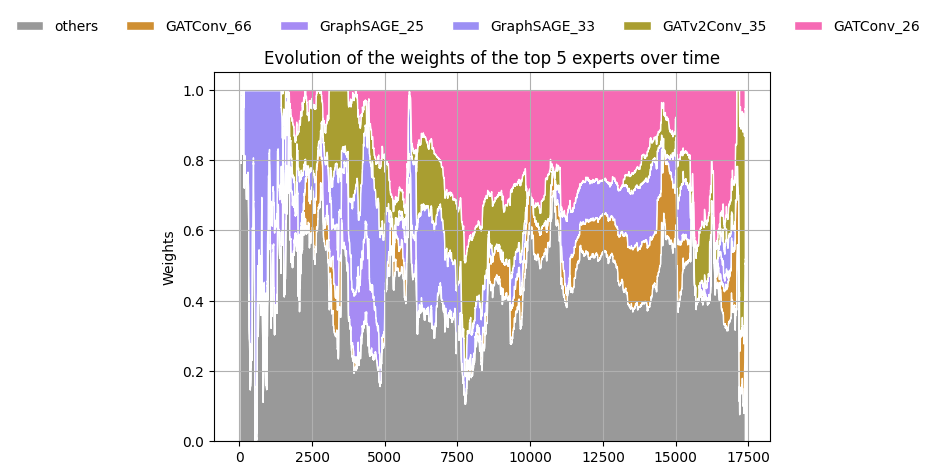

In [62]:
# View most influential experts in the top-level mixture
max_experts = 5
W = mixture.weights 
mean_weights = np.mean(W, axis=0)
top_indices = np.argsort(mean_weights)[::-1][:max_experts]
top_experts = np.array(mixture.experts_names)[top_indices]

print(f"{max_experts} most influential experts and their average weights:")
for i, name in enumerate(top_experts, 1):
    print(f"{i}. {name} (mean weight = {mean_weights[top_indices[i-1]]:.4f})")

colors = sns.color_palette("husl", W.shape[1])
rng = np.random.default_rng(seed=0) 
rng.shuffle(colors)
mixture.plot_mixture(
    plot_type="plot_weight",
    colors=colors,
    max_experts=max_experts,
    title=f"Evolution of the weights of the top {max_experts} experts over time",
    ylabel="Weights",
)

## Bottom-up

In [63]:
# Bottom-up aggregation
experts_bottom = pd.read_csv(f'results_{DATASET}/experts_bottom.csv', index_col=0)
target_bottom = pd.read_csv(f'results_{DATASET}/target_bottom.csv', index_col=0)
nodes_list = list(target_bottom.columns)

T = len(experts_bottom)          
step = OUT_CHANNELS                
predictions_bottom = pd.DataFrame(index=experts_bottom.index, columns=nodes_list, dtype=float)

mixtures_bottom = {}
for node in nodes_list:
    cols_node = [c for c in experts_bottom.columns if c.endswith(f"__{node}")]
    if not cols_node:
        continue

    X_node = experts_bottom[cols_node]                 # T × K_node (DataFrame)
    y_node = target_bottom[node].values.astype(float)  # (T,)
    K_node = X_node.shape[1]
    w0 = np.ones(K_node) / K_node
    pred_node = np.empty(T, dtype=float)
    pred_node[:step] = X_node.iloc[:step].values @ w0

    node_mixture = Mixture(
        y=y_node[:step],
        experts=X_node.iloc[:step],
        model="MLpol",
        loss_type="mse",
    )

    for s in range(step, T, step):
        e = min(s + step, T)
        X_blk = X_node.iloc[s:e]
        y_blk = y_node[s:e]
        pred_blk = node_mixture.predict(new_experts=X_blk)
        pred_node[s:e] = np.ravel(pred_blk)
        node_mixture.update(new_experts=X_blk, new_y=y_blk)

    predictions_bottom[node] = pred_node
    mixtures_bottom[node] = node_mixture

prediction_bottom_up = predictions_bottom.sum(axis=1).values
print(RMSE(preds=prediction_bottom_up, targets=true_top.numpy()))
print(100*MAPE(preds=prediction_bottom_up, targets=true_top.numpy()))

/var/folders/lc/jrt78rc56md09lxvkmwkgh7m0000gp/T/ipykernel_65228/2117916583.py:21: RuntimeWarning: divide by zero encountered in matmul
  pred_node[:step] = X_node.iloc[:step].values @ w0
/var/folders/lc/jrt78rc56md09lxvkmwkgh7m0000gp/T/ipykernel_65228/2117916583.py:21: RuntimeWarning: overflow encountered in matmul
  pred_node[:step] = X_node.iloc[:step].values @ w0
/var/folders/lc/jrt78rc56md09lxvkmwkgh7m0000gp/T/ipykernel_65228/2117916583.py:21: RuntimeWarning: invalid value encountered in matmul
  pred_node[:step] = X_node.iloc[:step].values @ w0
/var/folders/lc/jrt78rc56md09lxvkmwkgh7m0000gp/T/ipykernel_65228/2117916583.py:21: RuntimeWarning: divide by zero encountered in matmul
  pred_node[:step] = X_node.iloc[:step].values @ w0
/var/folders/lc/jrt78rc56md09lxvkmwkgh7m0000gp/T/ipykernel_65228/2117916583.py:21: RuntimeWarning: overflow encountered in matmul
  pred_node[:step] = X_node.iloc[:step].values @ w0
/var/folders/lc/jrt78rc56md09lxvkmwkgh7m0000gp/T/ipykernel_65228/21179165

789.3882214954278
1.0057827529478405


Node: Auvergne_Rhone_Alpes
5 most influential experts and their average weights:
1. TAGConv_78__Auvergne_Rhone_Alpes (mean weight = 0.1911)
2. GATConv_26__Auvergne_Rhone_Alpes (mean weight = 0.0806)
3. APPNP_39__Auvergne_Rhone_Alpes (mean weight = 0.0787)
4. ChebConv_53__Auvergne_Rhone_Alpes (mean weight = 0.0696)
5. GraphSAGE_33__Auvergne_Rhone_Alpes (mean weight = 0.0693)


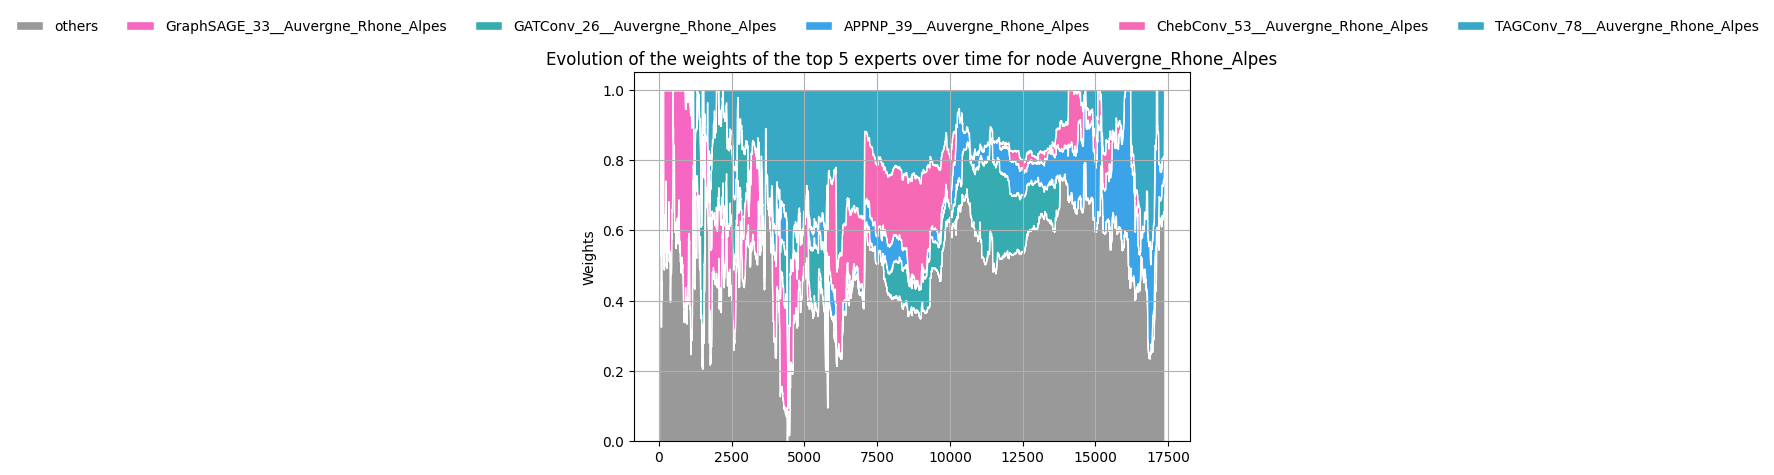

Node: Bourgogne_Franche_Comte
5 most influential experts and their average weights:
1. GATv2Conv_75__Bourgogne_Franche_Comte (mean weight = 0.1045)
2. ChebConv_69__Bourgogne_Franche_Comte (mean weight = 0.0998)
3. TAGConv_46__Bourgogne_Franche_Comte (mean weight = 0.0887)
4. GATv2Conv_67__Bourgogne_Franche_Comte (mean weight = 0.0843)
5. GCNConv_64__Bourgogne_Franche_Comte (mean weight = 0.0712)


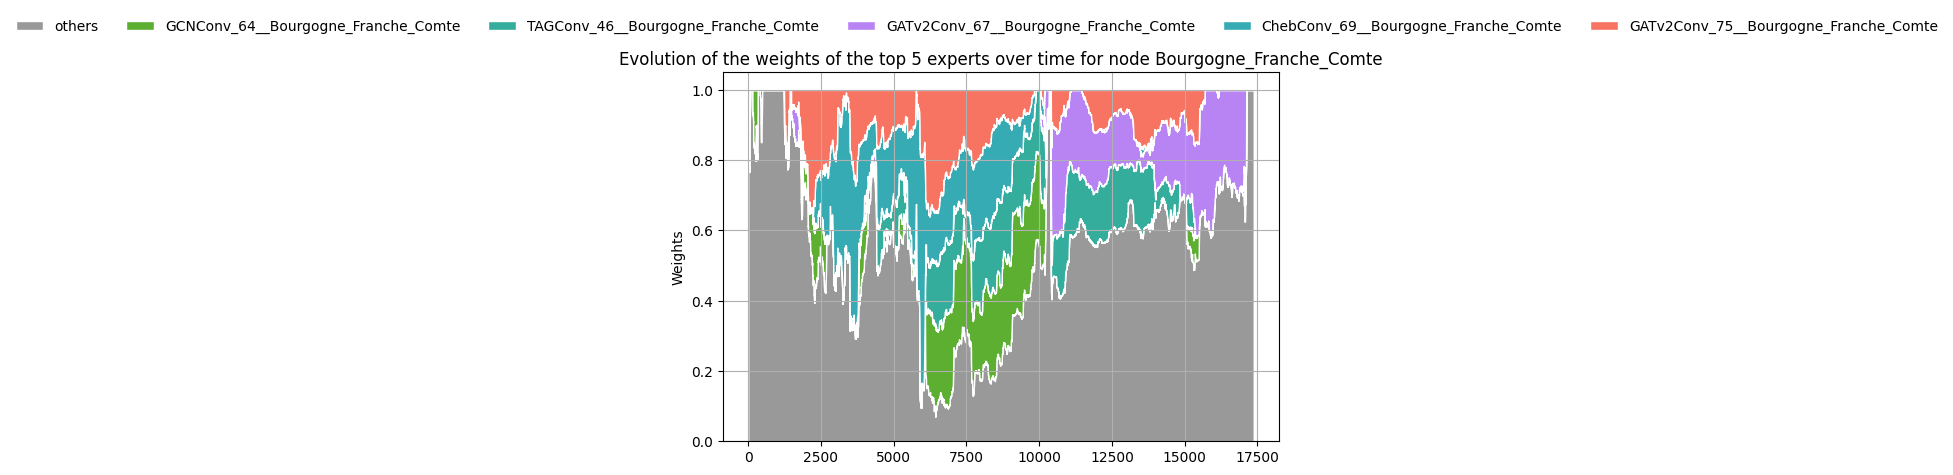

Node: Bretagne
5 most influential experts and their average weights:
1. GATv2Conv_35__Bretagne (mean weight = 0.1828)
2. ChebConv_45__Bretagne (mean weight = 0.0856)
3. GraphSAGE_17__Bretagne (mean weight = 0.0787)
4. GCNConv_64__Bretagne (mean weight = 0.0785)
5. ChebConv_69__Bretagne (mean weight = 0.0620)


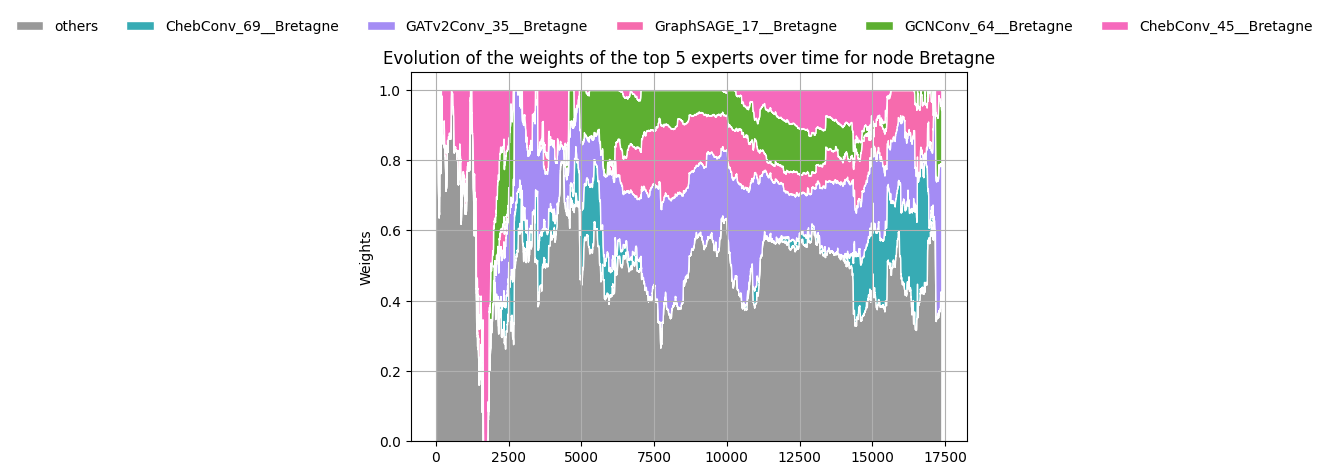

In [66]:
# View most influential experts in the first K bottom-up mixtures
max_experts = 5
num_mixtures = 3
for node in nodes_list[:num_mixtures]:
    mixture = mixtures_bottom.get(node)
    if mixture is None:
        continue

    W = mixture.weights 
    mean_weights = np.mean(W, axis=0)
    top_indices = np.argsort(mean_weights)[::-1][:max_experts]
    top_experts = np.array(mixture.experts_names)[top_indices]

    print(f"Node: {node}")
    print(f"{max_experts} most influential experts and their average weights:")
    for i, name in enumerate(top_experts, 1):
        print(f"{i}. {name} (mean weight = {mean_weights[top_indices[i-1]]:.4f})")

    colors = sns.color_palette("husl", W.shape[1])
    rng = np.random.default_rng(seed=0) 
    rng.shuffle(colors)
    mixture.plot_mixture(
        plot_type="plot_weight",
        colors=colors,
        max_experts=max_experts,
        title=f"Evolution of the weights of the top {max_experts} experts over time for node {node}",
        ylabel="Weights",
    )

# Vizualisations

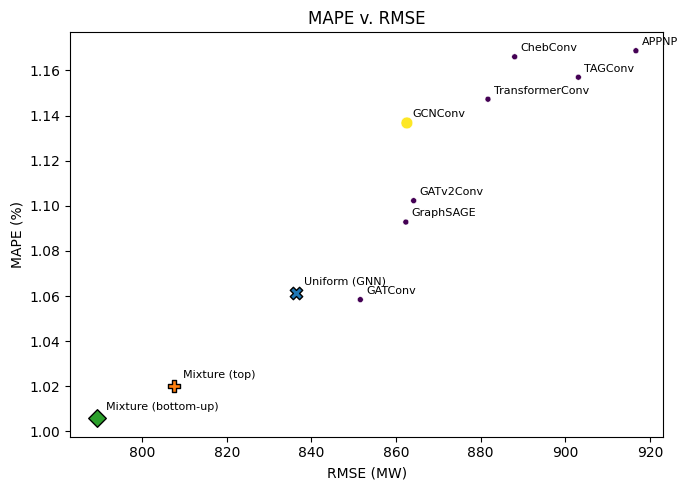

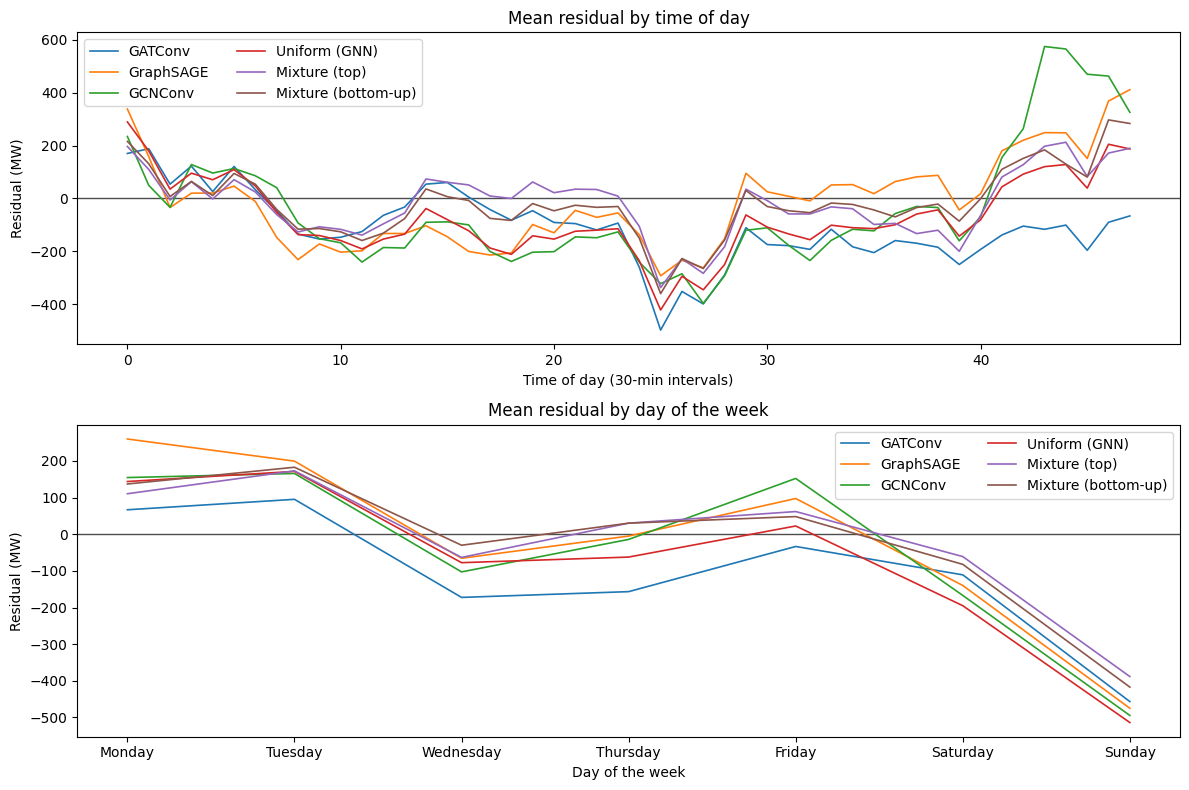

In [67]:
# Vizualisations per-model + aggregations (uniform/mixture) + baselines
df = per_model_df.copy()
df.index.name = 'model'
df = df.reset_index()

true_np = true_top.detach().cpu().numpy()

# Uniform: equal weight per architecture (consistent with Table~per-arch-aggregation)
# avg_pred_top weights seeds equally → biased when architectures have different run counts.
# per_model_avg_preds is already seed-averaged per architecture, so mean here = equal arch weight.
uni_np = np.stack([
    per_model_avg_preds[m].detach().cpu().numpy()
    for m in per_model_avg_preds
]).mean(axis=0)
yt_u, yp_u = true_np[:min(len(true_np), len(uni_np))], uni_np[:min(len(true_np), len(uni_np))]
rmse_uni = RMSE(preds=yp_u, targets=yt_u).item()
mape_uni = 100 * MAPE(preds=yp_u, targets=yt_u).item()

# Mixture top-level
mix_np = np.asarray(predictions_top, dtype=float)
yt_m, yp_m = true_np[:min(len(true_np), len(mix_np))], mix_np[:min(len(true_np), len(mix_np))]
rmse_mix = RMSE(preds=yp_m, targets=yt_m).item()
mape_mix = 100 * MAPE(preds=yp_m, targets=yt_m).item()

# Mixture bottom-up
bu_np = np.asarray(prediction_bottom_up, dtype=float)
yt_bu, yp_bu = true_np[:min(len(true_np), len(bu_np))], bu_np[:min(len(true_np), len(bu_np))]
rmse_bu = RMSE(preds=yp_bu, targets=yt_bu).item()
mape_bu = 100 * MAPE(preds=yp_bu, targets=yt_bu).item()

# 1) 
plt.figure(figsize=(7, 5))
ax = sns.scatterplot(
    data=df, x='rmse_avg_pred', y='mape_avg_pred',
    size='n_runs', hue='n_runs', palette='viridis', legend=False
)
for _, r in df.iterrows():
    ax.annotate(r['model'], (r['rmse_avg_pred'], r['mape_avg_pred']),
                textcoords='offset points', xytext=(4, 4), fontsize=8)

extras = [
    ('Uniform (GNN)', rmse_uni, mape_uni, 'X', 'tab:blue'),
    ('Mixture (top)', rmse_mix, mape_mix, 'P', 'tab:orange'),
    ('Mixture (bottom-up)', rmse_bu, mape_bu, 'D', 'tab:green'),
]
for label, x, y, marker, color in extras:
    ax.scatter(x, y, marker=marker, s=80, color=color, edgecolor='black', zorder=5)
    ax.annotate(label, (x, y), textcoords='offset points', xytext=(6, 6), fontsize=8)

ax.set_xlabel('RMSE (MW)')
ax.set_ylabel('MAPE (%)')
ax.set_title('MAPE v. RMSE')
plt.tight_layout()
plt.show()

# 2) 
best = df.nsmallest(3, 'rmse_avg_pred')['model'].tolist()
Tm = min(
    len(true_np),
    *[len(per_model_avg_preds[m]) for m in best],
    len(uni_np), len(mix_np), len(bu_np),
)
yt = true_np[:Tm]

residuals = {}
for m in best:
    yp = per_model_avg_preds[m][:Tm].detach().cpu().numpy()
    residuals[m] = yp - yt
residuals['Uniform (GNN)'] = uni_np[:Tm] - yt
residuals['Mixture (top)'] = mix_np[:Tm] - yt
residuals['Mixture (bottom-up)'] = bu_np[:Tm] - yt

time_of_day_idx = np.arange(Tm) % step  # 0..47
dow_idx = pd.to_datetime(target_bottom.index[:Tm]).dayofweek.values  # 0..6

def group_means(values, group_idx, n_groups):
    return np.array([
        values[group_idx == g].mean() if np.any(group_idx == g) else np.nan
        for g in range(n_groups)
    ])

daily_means = {k: group_means(v, time_of_day_idx, step) for k, v in residuals.items()}
weekly_means = {k: group_means(v, dow_idx, 7) for k, v in residuals.items()}
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=False)

axes[0].axhline(0.0, color='black', linewidth=1.0, alpha=0.7)
x_day = np.arange(step)
for label, arr in daily_means.items():
    axes[0].plot(x_day, arr, label=label, linewidth=1.2)
axes[0].set_title('Mean residual by time of day')
axes[0].set_xlabel('Time of day (30-min intervals)')
axes[0].set_ylabel('Residual (MW)')
axes[0].legend(ncol=2)

axes[1].axhline(0.0, color='black', linewidth=1.0, alpha=0.7)
x_week = np.arange(7)
for label, arr in weekly_means.items():
    axes[1].plot(x_week, arr, label=label, linewidth=1.2)
day_names = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
axes[1].set_xticks(x_week)
axes[1].set_xticklabels(day_names)
axes[1].set_title('Mean residual by day of the week')
axes[1].set_xlabel('Day of the week')
axes[1].set_ylabel('Residual (MW)')
axes[1].legend(ncol=2)

plt.tight_layout()
plt.show()

# Statistical Significance Tests

Per-day (48-step block) Diebold–Mariano-style Wilcoxon signed-rank tests on the squared errors of the seed-averaged GNN predictions (French dataset, 365 days).
Tests whether two models' error distributions are indistinguishable.
Bonferroni correction is applied for multiple comparisons (n = K(K-1)/2 pairs).
★ marks pairs significant at α = 0.05 after correction.

true_top rebuilt: len=192, mean=141546
Rebuilding per_model_avg_preds from saved .pt files …
  Loaded 8 models: ['APPNP', 'ChebConv', 'GATConv', 'GATv2Conv', 'GCNConv', 'GraphSAGE', 'TAGConv', 'TransformerConv']


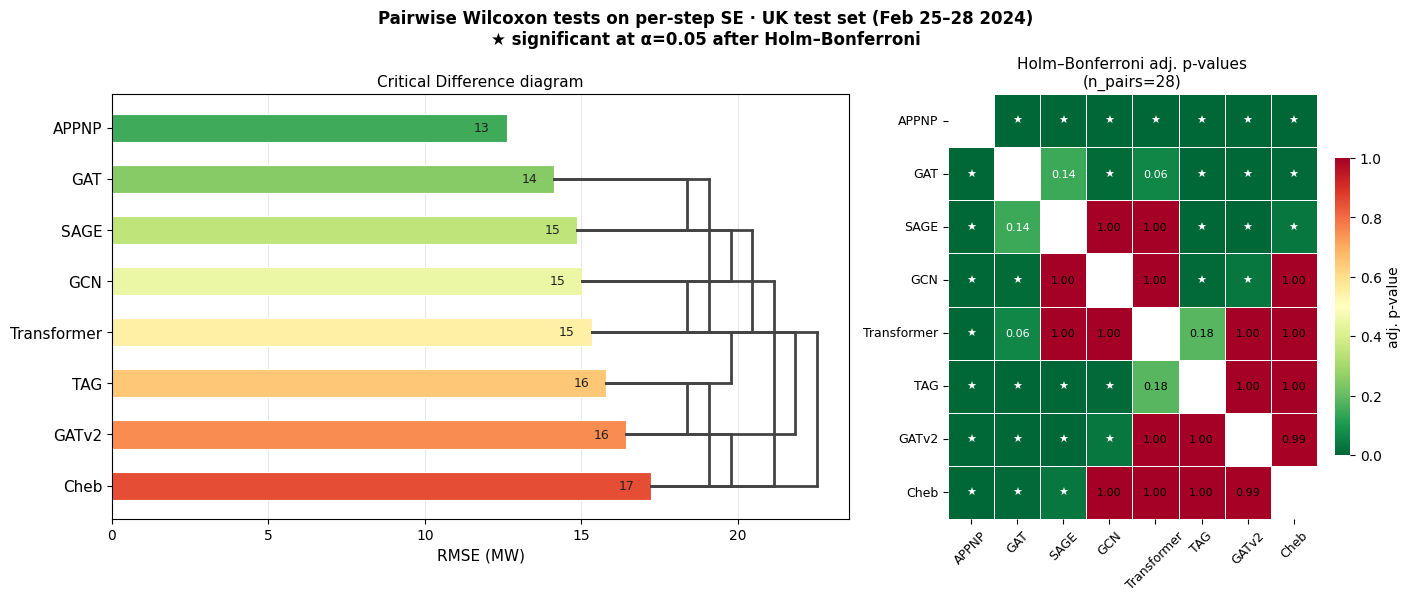


Model ranking by RMSE (MW):
  APPNP            12.6
  GAT              14.1
  SAGE             14.9
  GCN              15.0
  Transformer      15.3
  TAG              15.8
  GATv2            16.4
  Cheb             17.2

Significant pairs after Holm–Bonferroni (α=0.05):
  APPNP           vs Transformer      Δ=2.7 MW  raw p=0.0000  adj p=0.0000
  GAT             vs TAG              Δ=1.7 MW  raw p=0.0000  adj p=0.0000
  APPNP           vs TAG              Δ=3.2 MW  raw p=0.0000  adj p=0.0000
  APPNP           vs GCN              Δ=2.4 MW  raw p=0.0000  adj p=0.0000
  APPNP           vs GATv2            Δ=3.8 MW  raw p=0.0000  adj p=0.0000
  GAT             vs GATv2            Δ=2.3 MW  raw p=0.0000  adj p=0.0000
  APPNP           vs GAT              Δ=1.5 MW  raw p=0.0000  adj p=0.0000
  GraphSAGE       vs GATv2            Δ=1.6 MW  raw p=0.0000  adj p=0.0002
  APPNP           vs Cheb             Δ=4.6 MW  raw p=0.0000  adj p=0.0002
  APPNP           vs GraphSAGE        Δ=2.3 MW  raw p

In [17]:
# ── Significance tests + Critical Difference diagram ─────────────────────────
# Pairwise Wilcoxon signed-rank tests with Holm–Bonferroni correction.
# Visualised as a CD diagram: models ranked by mean RMSE; a bracket connects
# all groups that are NOT significantly different from each other.
# rfrance : per-day MSE blocks (365 days)
# weave   : per-half-hour SE  (192 steps)

from scipy import stats

H_sig = OUT_CHANNELS  # 48

# ── 0. Rebuild true_top / per_model_avg_preds (dataset-tagged to avoid stale state) ──
_sig_tag = f'_sig_cache_{DATASET}'
if globals().get('_sig_active_dataset') != DATASET:
    # Dataset changed — force full rebuild
    _sig_active_dataset = DATASET
    true_top            = None
    per_model_avg_preds = {}

if true_top is None:
    df_t = graph_dataset_test.dataframe.pivot(
        index='date',
        columns=graph_dataset_test.data.node_var,
        values=graph_dataset_test.target,
    )
    true_top = torch.from_numpy(df_t.values.T.astype(float).sum(axis=0))
    print(f"true_top rebuilt: len={len(true_top)}, mean={true_top.float().mean():.0f}")

# Always rebuild here so the exclusion list below is respected
# (Cell 57 may have populated per_model_avg_preds with different models)
print("Rebuilding per_model_avg_preds from saved .pt files …")
if True:
    _base = f'results_{DATASET}/'
    _true = true_top.detach().cpu().float()
    per_model_avg_preds = {}
    for _conv in sorted(d for d in os.listdir(_base)
                        if os.path.isdir(os.path.join(_base, d)) and d not in ['FF', 'ADLGNN']):
        _folder = os.path.join(_base, _conv)
        _runs = []
        for _f in sorted(os.listdir(_folder)):
            if not _f.endswith('.pt'):
                continue
            try:
                _obj = torch.load(os.path.join(_folder, _f), weights_only=False)
            except Exception:
                continue
            if isinstance(_obj, dict):
                _obj = _obj.get('predictions', None)
                if _obj is None:
                    continue
            try:
                _t = torch.as_tensor(_obj).float()
            except Exception:
                continue
            _s = (_t.sum(dim=0) if _t.ndim == 2 else _t.reshape(-1)).float()
            _runs.append(_s[:len(_true)])
        if _runs:
            per_model_avg_preds[_conv] = torch.stack(_runs).mean(dim=0)
    print(f"  Loaded {len(per_model_avg_preds)} models: {list(per_model_avg_preds)}")

# ── 1. Per-model RMSE (seed-averaged) and per-block errors ───────────────────
true_sig = true_top.detach().cpu().numpy()
T_sig    = (len(true_sig) // H_sig) * H_sig

if DATASET == 'rfrance':
    n_blocks      = T_sig // H_sig
    block_label   = f'n_days={n_blocks}'
    block_desc    = 'daily MSE'
    dataset_label = 'French test set 2019'
    unit          = 'MW'
else:
    n_blocks      = T_sig
    block_label   = f'n_steps={n_blocks}'
    block_desc    = 'per-step SE'
    dataset_label = 'UK test set (Feb 25–28 2024)'
    unit          = 'MW'

block_errors = {}
model_rmse   = {}
# weave predictions are stored in kW; paper reports in MW
rmse_scale   = 1/1000 if DATASET == 'weave' else 1.0
for mname, avg_pred in per_model_avg_preds.items():
    pred = avg_pred.detach().cpu().numpy()[:T_sig]
    err2 = (pred - true_sig[:T_sig]) ** 2
    if DATASET == 'rfrance':
        block_errors[mname] = err2.reshape(n_blocks, H_sig).mean(axis=1)
    else:
        block_errors[mname] = err2
    model_rmse[mname] = float(np.sqrt(err2.mean())) * rmse_scale

# ── 2. Pairwise Wilcoxon + Holm–Bonferroni ───────────────────────────────────
models_sig = sorted(block_errors, key=lambda m: model_rmse[m])  # rank by RMSE
K          = len(models_sig)
n_pairs    = K * (K - 1) // 2
alpha      = 0.05

pairs, praw_list = [], []
for i, m1 in enumerate(models_sig):
    for j, m2 in enumerate(models_sig):
        if i >= j:
            continue
        try:
            _, p = stats.wilcoxon(block_errors[m1], block_errors[m2],
                                   alternative='two-sided')
        except Exception:
            p = np.nan
        pairs.append((i, j))
        praw_list.append(p)

# Holm–Bonferroni: sort ascending, multiply by (n_pairs - rank)
order  = np.argsort(praw_list)
padj_list = np.full(len(praw_list), np.nan)
for rank, idx in enumerate(order):
    if np.isnan(praw_list[idx]):
        continue
    padj_list[idx] = float(np.clip(praw_list[idx] * (n_pairs - rank), 0, 1))

praw_mat = np.full((K, K), np.nan)
padj_mat = np.full((K, K), np.nan)
for k, (i, j) in enumerate(pairs):
    praw_mat[i, j] = praw_mat[j, i] = praw_list[k]
    padj_mat[i, j] = padj_mat[j, i] = padj_list[k]

sig_mat = padj_mat < alpha   # True where the pair IS significantly different

# ── 3. CD diagram ─────────────────────────────────────────────────────────────
tick_labels = [m.replace('Conv', '').replace('GraphSAGE', 'SAGE') for m in models_sig]
rmse_vals   = [model_rmse[m] for m in models_sig]

fig, axes = plt.subplots(1, 2, figsize=(14, max(4, K * 0.55 + 1.5)),
                          gridspec_kw={'width_ratios': [2, 1]},
                          constrained_layout=True)

# ── Left panel: CD diagram ────────────────────────────────────────────────────
ax = axes[0]
y_pos = np.arange(K)[::-1]   # best model at top

# Horizontal RMSE bars
colors = plt.cm.RdYlGn_r(np.linspace(0.15, 0.85, K))
bars = ax.barh(y_pos, rmse_vals, height=0.55, color=colors, edgecolor='white',
               linewidth=0.8, zorder=2)

# Spacing is relative to max value (bar_span can be tiny vs absolute values)
vmax      = max(rmse_vals)
lbl_gap   = vmax * 0.012   # gap between bar end and text label
lbl_width = vmax * 0.055   # horizontal space reserved for the text label
brk_step  = vmax * 0.04    # width per bracket column
brk_start = vmax + lbl_gap + lbl_width  # brackets begin here

# Value labels: right of bar end, clearly outside
val_fmt = lambda v: f'{v:.1f}' if v < 10 else f'{v:.0f}'
for bar, val in zip(bars, rmse_vals):
    ax.text(val - 5*lbl_gap, bar.get_y() + bar.get_height() / 2,
            val_fmt(val), va='center', ha='left', fontsize=9,
            color='#222222', zorder=5)

# NS brackets in non-overlapping columns (greedy left-to-right assignment)
bracket_cols = {}
for i in range(K):
    for j in range(i + 1, K):
        if np.isnan(padj_mat[i, j]) or sig_mat[i, j]:
            continue
        yi, yj = y_pos[i], y_pos[j]
        y_lo, y_hi = min(yi, yj), max(yi, yj)
        col = 0
        while True:
            occupied = bracket_cols.get(col, [])
            if all(y_hi < lo - 0.25 or y_lo > hi + 0.25 for lo, hi in occupied):
                break
            col += 1
        bracket_cols.setdefault(col, []).append((y_lo, y_hi))
        xb = brk_start + col * brk_step
        # Vertical bar of bracket
        ax.plot([xb, xb], [yi, yj], color='#444444', lw=2.0, zorder=3,
                solid_capstyle='round')
        # Horizontal ticks from bar end to bracket
        ax.plot([rmse_vals[i], xb], [yi, yi], color='#444444', lw=2.0, zorder=3)
        ax.plot([rmse_vals[j], xb], [yj, yj], color='#444444', lw=2.0, zorder=3)

n_cols = max(bracket_cols.keys()) + 1 if bracket_cols else 0
ax.set_xlim(0, brk_start + n_cols * brk_step + brk_step * 0.5)
ax.set_yticks(y_pos)
ax.set_yticklabels(tick_labels, fontsize=11)
ax.set_xlabel(f'RMSE ({unit})', fontsize=11)
ax.set_title('Critical Difference diagram', fontsize=11, pad=6)
ax.xaxis.grid(True, alpha=0.3, zorder=0)
ax.set_axisbelow(True)

# ── Right panel: adjusted p-value heatmap (compact) ──────────────────────────
ax2 = axes[1]
mask = np.eye(K, dtype=bool)
sns.heatmap(padj_mat, annot=False, mask=mask,
            xticklabels=tick_labels, yticklabels=tick_labels,
            cmap='RdYlGn_r', vmin=0, vmax=1,
            linewidths=0.4, linecolor='white',
            ax=ax2, cbar_kws={'label': 'adj. p-value', 'shrink': 0.7})

for r in range(K):
    for c in range(K):
        if r == c or np.isnan(padj_mat[r, c]):
            continue
        sig = padj_mat[r, c] < alpha
        txt = ('★' if sig else f'{padj_mat[r, c]:.2f}')
        ax2.text(c + 0.5, r + 0.5, txt,
                 ha='center', va='center', fontsize=8,
                 fontweight='bold' if sig else 'normal',
                 color='white' if padj_mat[r, c] < 0.15 else 'black')

ax2.tick_params(axis='x', rotation=45, labelsize=9)
ax2.tick_params(axis='y', rotation=0, labelsize=9)
ax2.set_title(f'Holm–Bonferroni adj. p-values\n(n_pairs={n_pairs})', fontsize=11, pad=6)

fig.suptitle(
    f'Pairwise Wilcoxon tests on {block_desc} · {dataset_label}\n'
    f'★ significant at α={alpha} after Holm–Bonferroni',
    fontsize=12, fontweight='bold',
)
plt.savefig(f'results_{DATASET}/wilcoxon_cd_{DATASET}.pdf', bbox_inches='tight')
plt.show()

# ── 4. Summary ────────────────────────────────────────────────────────────────
print(f"\nModel ranking by RMSE ({unit}):")
for m in models_sig:
    print(f"  {m.replace('Conv','').replace('GraphSAGE','SAGE'):15s}  {model_rmse[m]:.1f}")
sig_pairs_list = [(models_sig[i], models_sig[j], praw_list[k], padj_list[k])
                  for k, (i, j) in enumerate(pairs)
                  if not np.isnan(padj_list[k]) and padj_list[k] < alpha]
print(f"\nSignificant pairs after Holm–Bonferroni (α={alpha}):")
if sig_pairs_list:
    for m1, m2, p, pa in sorted(sig_pairs_list, key=lambda x: x[3]):
        delta = abs(model_rmse[m1] - model_rmse[m2])
        print(f"  {m1.replace('Conv',''):15s} vs {m2.replace('Conv',''):15s}"
              f"  Δ={delta:.1f} {unit}  raw p={p:.4f}  adj p={pa:.4f}")
else:
    print("  None — no pairwise differences survive correction.")


## Additional Graph-Learning Baselines (MTGNN, ADLGNN)

This section adds starter code for two graph-learning methods requested by reviewers:
- MTGNN (Wu et al., KDD 2020)
- ADLGNN (Sriramulu et al., Information Sciences 2023)

The code is written to integrate with the existing tensors already built in this notebook (`X_train_stacked`, `X_val_stacked`, `X_test_stacked`, and matching targets).

Note: repository APIs differ across forks; the wrappers below are intentionally explicit and easy to adapt.

In [69]:
# Optional helper: make local clones importable (adjust paths as needed)
import sys
from pathlib import Path

MTGNN_REPO = Path("external/MTGNN")
ADLGNN_REPO = Path("external/ADLGNN")

for repo in [MTGNN_REPO, ADLGNN_REPO]:
    if repo.exists():
        p = str(repo.resolve())
        if p not in sys.path:
            sys.path.insert(0, p)

print("MTGNN repo found:", MTGNN_REPO.exists(), "at", MTGNN_REPO)
print("ADLGNN repo found:", ADLGNN_REPO.exists(), "at", ADLGNN_REPO)

# If needed, clone manually in a terminal:
# git clone https://github.com/nnzhan/MTGNN external/MTGNN
# (Use the ADLGNN repository URL you prefer and set ADLGNN_REPO accordingly)

MTGNN repo found: True at external/MTGNN
ADLGNN repo found: True at external/ADLGNN


In [70]:
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader


class SeqDataset(Dataset):
    def __init__(self, X, Y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.Y = torch.tensor(Y, dtype=torch.float32)

    def __len__(self):
        return self.X.shape[0]

    def __getitem__(self, idx):
        return self.X[idx], self.Y[idx]


def build_seq_arrays(X, Y):
    """
    Expected shape from this notebook:
      X: [n_samples, n_nodes, n_features, in_len]
      Y: [n_samples, n_nodes, out_len]
    """
    if isinstance(X, torch.Tensor):
        X = X.detach().cpu().numpy()
    if isinstance(Y, torch.Tensor):
        Y = Y.detach().cpu().numpy()
    return X, Y


def rmse_mape_agg(y_true, y_pred, eps=1e-8):
    # Aggregate over nodes first to stay consistent with the paper protocol.
    true_agg = y_true.sum(axis=1)  # [n_samples, out_len]
    pred_agg = y_pred.sum(axis=1)

    rmse = float(np.sqrt(np.mean((true_agg - pred_agg) ** 2)))
    mape = float(np.mean(np.abs((true_agg - pred_agg) / (true_agg + eps))) * 100.0)
    return rmse, mape


def train_eval_generic(model, train_loader, val_loader, test_loader, lr=1e-3, epochs=40, device=None):
    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    model = model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()

    best_state = None
    best_val = np.inf

    for _ in range(epochs):
        model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            yp = model(xb)
            loss = loss_fn(yp, yb)
            loss.backward()
            opt.step()

        model.eval()
        val_losses = []
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                yp = model(xb)
                val_losses.append(float(loss_fn(yp, yb).detach().cpu()))

        val_mean = float(np.mean(val_losses)) if val_losses else np.inf
        if val_mean < best_val:
            best_val = val_mean
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

    if best_state is not None:
        model.load_state_dict(best_state)

    # Test predictions
    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for xb, yb in test_loader:
            xb = xb.to(device)
            yp = model(xb).detach().cpu().numpy()
            y_pred.append(yp)
            y_true.append(yb.detach().cpu().numpy())

    y_true = np.concatenate(y_true, axis=0)
    y_pred = np.concatenate(y_pred, axis=0)
    return y_true, y_pred

In [71]:
# MTGNN baseline wrapper
# Expected external API: adapt imports/constructor to your MTGNN fork.

import importlib.util
from pathlib import Path
import sys


def _load_mtgnn_gtnet(repo: Path):
    net_py = repo / "net.py"
    layer_py = repo / "layer.py"
    if not net_py.exists():
        raise ImportError(
            f"MTGNN net.py not found at {net_py}. Clone MTGNN into external/MTGNN "
            "or update MTGNN_REPO."
        )
    if not layer_py.exists():
        raise ImportError(f"MTGNN layer.py not found at {layer_py}.")

    # Ensure MTGNN imports its own layer.py, not ADLGNN's.
    old_layer_mod = sys.modules.pop("layer", None)
    old_path = list(sys.path)
    try:
        repo_str = str(repo.resolve())
        if repo_str not in sys.path:
            sys.path.insert(0, repo_str)

        layer_spec = importlib.util.spec_from_file_location("layer", layer_py)
        if layer_spec is None or layer_spec.loader is None:
            raise ImportError(f"Could not load module spec from {layer_py}")
        layer_mod = importlib.util.module_from_spec(layer_spec)
        sys.modules["layer"] = layer_mod
        layer_spec.loader.exec_module(layer_mod)

        net_spec = importlib.util.spec_from_file_location("mtgnn_net", net_py)
        if net_spec is None or net_spec.loader is None:
            raise ImportError(f"Could not load module spec from {net_py}")
        net_mod = importlib.util.module_from_spec(net_spec)
        net_spec.loader.exec_module(net_mod)
    finally:
        sys.path[:] = old_path
        if old_layer_mod is not None:
            sys.modules["layer"] = old_layer_mod
        else:
            sys.modules.pop("layer", None)

    if not hasattr(net_mod, "gtnet"):
        raise ImportError(f"No gtnet class found in {net_py}")
    return net_mod.gtnet


class MTGNNWrapper(nn.Module):
    def __init__(self, n_nodes, n_features, in_len, out_len):
        super().__init__()

        # Load MTGNN explicitly from MTGNN_REPO to avoid picking ADLGNN files.
        repo = Path(globals().get("MTGNN_REPO", Path("external/MTGNN")))
        gtnet = _load_mtgnn_gtnet(repo)

        # NOTE: constructor signature differs by fork; tune as needed.
        self.core = gtnet(
            gcn_true=True,
            buildA_true=True,
            gcn_depth=2,
            num_nodes=n_nodes,
            device=torch.device("cpu"),
            dropout=0.3,
            subgraph_size=min(20, n_nodes),
            node_dim=40,
            dilation_exponential=2,
            conv_channels=32,
            residual_channels=32,
            skip_channels=64,
            end_channels=128,
            seq_length=in_len,
            in_dim=n_features,
            out_dim=out_len,
            layers=3,
            propalpha=0.05,
            tanhalpha=3,
            layer_norm_affline=True,
        )

    def forward(self, x):
        # x: [B, N, F, T]
        # MTGNN expects [B, F, N, T].
        x = x.permute(0, 2, 1, 3)
        y = self.core(x)

        # Harmonize output to [B, N, out_len]
        if y.ndim == 4 and y.shape[-1] == 1:
            y = y[..., 0]  # [B, C, N]
        if y.ndim == 4 and y.shape[1] == 1:
            y = y[:, 0, :, :]  # [B, N, T]
        if y.ndim == 3 and y.shape[2] == x.shape[2] and y.shape[1] != x.shape[2]:
            y = y.transpose(1, 2)
        return y


def _build_true_graph_arrays_from_dataset(ds):
    """
    Build MTGNN arrays from GraphDataset items.
    Each item has x:[N,F] and y:[N,H]. We map x as one feature-channel temporal sequence:
      X -> [B, N, 1, F]
      Y -> [B, N, H]
    """
    X = np.stack([d.x.detach().cpu().numpy() for d in ds], axis=0)  # [B,N,F]
    Y = np.stack([d.y.detach().cpu().numpy() for d in ds], axis=0)  # [B,N,H]
    X = X[:, :, None, :]  # [B,N,1,F]
    return X, Y


def _normalize_seq_shapes(X, Y):
    """
    Fallback normalizer when GraphDataset objects are unavailable.
    """
    X = np.asarray(X)
    Y = np.asarray(Y)

    if X.ndim == 4:
        pass
    elif X.ndim == 3:
        X = X[:, :, None, :]
    elif X.ndim == 2 and Y.ndim == 2:
        X = X[:, None, None, :]  # [B,1,1,D]
        Y = Y[:, None, :]        # [B,1,H]
        print(
            "[MTGNN fallback] Flattened arrays detected; using single pseudo-node temporal view "
            "X[B,1,1,D], Y[B,1,H]."
        )
    else:
        raise ValueError(
            "Unexpected input ranks for MTGNN prep: "
            f"X shape {X.shape}, Y shape {Y.shape}."
        )

    if Y.ndim == 2:
        Y = Y[:, None, :]
    if Y.ndim != 3:
        raise ValueError(f"Unexpected Y rank: {Y.shape}")

    if X.shape[0] != Y.shape[0]:
        raise ValueError(f"Sample mismatch: X has {X.shape[0]} rows, Y has {Y.shape[0]} rows.")
    if X.shape[1] != Y.shape[1]:
        raise ValueError(f"Node mismatch: X has N={X.shape[1]}, Y has N={Y.shape[1]}.")

    return X, Y


# Prefer true graph tensors from GraphDataset when available.
if "graph_dataset_train" in globals() and len(graph_dataset_train) > 0:
    Xtr_np, Ytr_np = _build_true_graph_arrays_from_dataset(graph_dataset_train)
    Xva_np, Yva_np = _build_true_graph_arrays_from_dataset(graph_dataset_val)
    Xte_np, Yte_np = _build_true_graph_arrays_from_dataset(graph_dataset_test)
    print("Using true graph tensors from GraphDataset.")
else:
    Xtr_np, Ytr_np = build_seq_arrays(X_train_stacked, y_train_stacked)
    Xva_np, Yva_np = build_seq_arrays(X_val_stacked, y_val_stacked)
    Xte_np, Yte_np = build_seq_arrays(X_test_stacked, y_test_stacked)
    Xtr_np, Ytr_np = _normalize_seq_shapes(Xtr_np, Ytr_np)
    Xva_np, Yva_np = _normalize_seq_shapes(Xva_np, Yva_np)
    Xte_np, Yte_np = _normalize_seq_shapes(Xte_np, Yte_np)

# Scale X and Y with train statistics for stable MTGNN optimization.
# Metrics are reported after inverse transform.
x_mu = float(Xtr_np.mean())
x_std = float(Xtr_np.std()) + 1e-6
y_mu = float(Ytr_np.mean())
y_std = float(Ytr_np.std()) + 1e-6

Xtr_s = (Xtr_np - x_mu) / x_std
Xva_s = (Xva_np - x_mu) / x_std
Xte_s = (Xte_np - x_mu) / x_std

Ytr_s = (Ytr_np - y_mu) / y_std
Yva_s = (Yva_np - y_mu) / y_std
Yte_s = (Yte_np - y_mu) / y_std

train_loader = DataLoader(SeqDataset(Xtr_s, Ytr_s), batch_size=32, shuffle=True)
val_loader = DataLoader(SeqDataset(Xva_s, Yva_s), batch_size=64, shuffle=False)
test_loader = DataLoader(SeqDataset(Xte_s, Yte_s), batch_size=64, shuffle=False)

n_nodes = Xtr_s.shape[1]
n_features = Xtr_s.shape[2]
in_len = Xtr_s.shape[3]
out_len = Ytr_s.shape[2]

print(
    "MTGNN input ready:",
    {
        "X": Xtr_s.shape,
        "Y": Ytr_s.shape,
        "n_nodes": n_nodes,
        "n_features": n_features,
        "in_len": in_len,
        "out_len": out_len,
        "train_windows": int(Xtr_s.shape[0]),
        "val_windows": int(Xva_s.shape[0]),
        "test_windows": int(Xte_s.shape[0]),
    },
)

# Forward smoke test to catch shape mismatches before full training.
mtgnn = MTGNNWrapper(n_nodes=n_nodes, n_features=n_features, in_len=in_len, out_len=out_len)
xb0, yb0 = next(iter(train_loader))
with torch.no_grad():
    yp0 = mtgnn(xb0)
print("MTGNN smoke test:", {"xb": tuple(xb0.shape), "yp": tuple(yp0.shape), "yb": tuple(yb0.shape)})

# Full run (scaled training, de-scaled evaluation)
y_true_mtgnn_s, y_pred_mtgnn_s = train_eval_generic(
    mtgnn,
    train_loader,
    val_loader,
    test_loader,
    lr=3e-4,
    epochs=120,
)
y_true_mtgnn = y_true_mtgnn_s * y_std + y_mu
y_pred_mtgnn = y_pred_mtgnn_s * y_std + y_mu

mtgnn_rmse, mtgnn_mape = rmse_mape_agg(y_true_mtgnn, y_pred_mtgnn)
print({"MTGNN RMSE": mtgnn_rmse, "MTGNN MAPE": mtgnn_mape})

Using true graph tensors from GraphDataset.
MTGNN input ready: {'X': (1090, 12, 1, 125), 'Y': (1090, 12, 48), 'n_nodes': 12, 'n_features': 1, 'in_len': 125, 'out_len': 48, 'train_windows': 1090, 'val_windows': 362, 'test_windows': 362}
MTGNN smoke test: {'xb': (32, 12, 1, 125), 'yp': (32, 12, 48), 'yb': (32, 12, 48)}


KeyboardInterrupt: 

In [ ]:
# Light HPO for MTGNN (quick search)
import optuna
import copy
from torch.utils.data import Subset

# Reuse already prepared scaled arrays from cell 83.
if "Xtr_s" not in globals() or "Ytr_s" not in globals():
    raise RuntimeError("Run cell 83 first to build scaled MTGNN tensors.")


def _hpo_batch_candidates(dataset_name):
    ds = str(dataset_name).lower()
    if any(k in ds for k in ["france", "french", "rfrance"]):
        return [256, 512]
    return [16, 32, 64]


def _hpo_speed_profile(dataset_name):
    ds = str(dataset_name).lower()
    is_french = any(k in ds for k in ["france", "french", "rfrance"])
    if is_french:
        return {
            "is_french": True,
            "n_trials": 4,
            "hpo_epochs": 12,
            "bestfit_epochs": 20,
            "train_fraction": 0.35,
            "val_fraction": 0.50,
            "patience": 3,
            "max_train_batches": 20,
        }
    return {
        "is_french": False,
        "n_trials": 8,
        "hpo_epochs": 35,
        "bestfit_epochs": 50,
        "train_fraction": 1.0,
        "val_fraction": 1.0,
        "patience": 8,
        "max_train_batches": None,
    }


def _subset_dataset(ds, fraction, seed=42):
    if fraction >= 1.0:
        return ds
    n = len(ds)
    k = max(1, int(round(n * fraction)))
    rng = np.random.default_rng(seed)
    idx = rng.choice(n, size=k, replace=False)
    return Subset(ds, np.sort(idx))


def _make_hpo_loaders(batch_size, train_fraction=1.0, val_fraction=1.0, seed=42):
    eval_bs = min(1024, int(batch_size) * 2)
    pin = bool(torch.cuda.is_available())

    tr_ds = _subset_dataset(SeqDataset(Xtr_s, Ytr_s), train_fraction, seed=seed)
    va_ds = _subset_dataset(SeqDataset(Xva_s, Yva_s), val_fraction, seed=seed + 1)
    te_ds = SeqDataset(Xte_s, Yte_s)

    tr = DataLoader(tr_ds, batch_size=int(batch_size), shuffle=True, pin_memory=pin)
    va = DataLoader(va_ds, batch_size=int(eval_bs), shuffle=False, pin_memory=pin)
    te = DataLoader(te_ds, batch_size=int(eval_bs), shuffle=False, pin_memory=pin)
    return tr, va, te


def _build_mtgnn_from_params(n_nodes, n_features, in_len, out_len, params):
    gtnet = _load_mtgnn_gtnet(Path(globals().get("MTGNN_REPO", Path("external/MTGNN"))))
    model = gtnet(
        gcn_true=True,
        buildA_true=True,
        gcn_depth=params["gcn_depth"],
        num_nodes=n_nodes,
        device=torch.device("cpu"),
        dropout=params["dropout"],
        subgraph_size=min(params["subgraph_size"], n_nodes),
        node_dim=params["node_dim"],
        dilation_exponential=2,
        conv_channels=params["conv_channels"],
        residual_channels=params["conv_channels"],
        skip_channels=params["skip_channels"],
        end_channels=params["end_channels"],
        seq_length=in_len,
        in_dim=n_features,
        out_dim=out_len,
        layers=params["layers"],
        propalpha=params["propalpha"],
        tanhalpha=3,
        layer_norm_affline=True,
    )

    class _Wrapper(nn.Module):
        def __init__(self, core):
            super().__init__()
            self.core = core

        def forward(self, x):
            x = x.permute(0, 2, 1, 3)
            y = self.core(x)
            if y.ndim == 4 and y.shape[-1] == 1:
                y = y[..., 0]
            if y.ndim == 4 and y.shape[1] == 1:
                y = y[:, 0, :, :]
            if y.ndim == 3 and y.shape[2] == x.shape[2] and y.shape[1] != x.shape[2]:
                y = y.transpose(1, 2)
            return y

    return _Wrapper(model)


def _eval_rmse_scaled(model, loader, device):
    model.eval()
    sq = []
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            yp = model(xb)
            sq.append(torch.mean((yp - yb) ** 2).detach().cpu())
    if not sq:
        return float("inf")
    return float(torch.sqrt(torch.mean(torch.stack(sq))).item())


HPO_BATCH_CANDIDATES = _hpo_batch_candidates(DATASET)
HPO_SPEED = _hpo_speed_profile(DATASET)
HPO_N_TRIALS = int(HPO_SPEED["n_trials"])
HPO_EPOCHS = int(HPO_SPEED["hpo_epochs"])
HPO_BESTFIT_EPOCHS = int(HPO_SPEED["bestfit_epochs"])
HPO_TRAIN_FRACTION = float(HPO_SPEED["train_fraction"])
HPO_VAL_FRACTION = float(HPO_SPEED["val_fraction"])
HPO_PATIENCE = int(HPO_SPEED["patience"])
HPO_MAX_TRAIN_BATCHES = HPO_SPEED["max_train_batches"]

print(
    "MTGNN HPO config:",
    {
        "batch_candidates": HPO_BATCH_CANDIDATES,
        "n_trials": HPO_N_TRIALS,
        "epochs": HPO_EPOCHS,
        "bestfit_epochs": HPO_BESTFIT_EPOCHS,
        "train_fraction": HPO_TRAIN_FRACTION,
        "val_fraction": HPO_VAL_FRACTION,
        "patience": HPO_PATIENCE,
        "max_train_batches": HPO_MAX_TRAIN_BATCHES,
    },
)


def objective(trial):
    params = {
        "gcn_depth": trial.suggest_int("gcn_depth", 1, 2),
        "dropout": trial.suggest_float("dropout", 0.1, 0.4),
        "subgraph_size": trial.suggest_categorical("subgraph_size", [10, 20, 28]),
        "node_dim": trial.suggest_categorical("node_dim", [16, 24, 32, 40]),
        "conv_channels": trial.suggest_categorical("conv_channels", [16, 24, 32]),
        "skip_channels": trial.suggest_categorical("skip_channels", [32, 48, 64]),
        "end_channels": trial.suggest_categorical("end_channels", [64, 96, 128]),
        "layers": trial.suggest_int("layers", 2, 3),
        "propalpha": trial.suggest_float("propalpha", 0.03, 0.15),
        "lr": trial.suggest_float("lr", 1e-4, 8e-4, log=True),
        "weight_decay": trial.suggest_float("weight_decay", 1e-7, 1e-4, log=True),
        "batch_size": trial.suggest_categorical("batch_size", HPO_BATCH_CANDIDATES),
    }

    train_loader_hpo, val_loader_hpo, _ = _make_hpo_loaders(
        params["batch_size"],
        train_fraction=HPO_TRAIN_FRACTION,
        val_fraction=HPO_VAL_FRACTION,
        seed=trial.number + 123,
    )

    device = torch.device("cpu")
    model = _build_mtgnn_from_params(n_nodes, n_features, in_len, out_len, params).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=params["lr"], weight_decay=params["weight_decay"])
    loss_fn = nn.MSELoss()

    best_state = None
    best_val = float("inf")
    bad_epochs = 0

    for epoch in range(HPO_EPOCHS):
        model.train()
        for bi, (xb, yb) in enumerate(train_loader_hpo):
            if HPO_MAX_TRAIN_BATCHES is not None and bi >= int(HPO_MAX_TRAIN_BATCHES):
                break
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            yp = model(xb)
            loss = loss_fn(yp, yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            opt.step()

        val_rmse_s = _eval_rmse_scaled(model, val_loader_hpo, device)
        trial.report(val_rmse_s * y_std, step=epoch)
        if trial.should_prune():
            raise optuna.TrialPruned()

        if val_rmse_s + 1e-9 < best_val:
            best_val = val_rmse_s
            best_state = copy.deepcopy(model.state_dict())
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= HPO_PATIENCE:
                break

    if best_state is not None:
        model.load_state_dict(best_state)

    val_rmse_unscaled = best_val * y_std
    trial.set_user_attr("val_rmse_scaled", best_val)
    trial.set_user_attr("val_rmse_unscaled", val_rmse_unscaled)
    trial.set_user_attr("batch_size", int(params["batch_size"]))
    return val_rmse_unscaled


study = optuna.create_study(
    direction="minimize",
    pruner=optuna.pruners.MedianPruner(n_startup_trials=2, n_warmup_steps=3),
)
study.optimize(objective, n_trials=HPO_N_TRIALS, show_progress_bar=False)

print("Best trial:", study.best_trial.number)
print("Best params:", study.best_trial.params)
print("Best val RMSE (unscaled):", float(study.best_value))

# Optional quick retrain on best params and test evaluation
best_params = dict(study.best_trial.params)
best_batch = int(best_params.get("batch_size", HPO_BATCH_CANDIDATES[0]))
train_loader_best, val_loader_best, test_loader_best = _make_hpo_loaders(
    best_batch,
    train_fraction=min(1.0, max(HPO_TRAIN_FRACTION, 0.7)),
    val_fraction=1.0,
    seed=777,
)

# Keep best-fit on CPU: MTGNN forks can trigger MPS placeholder-storage runtime errors.
device = torch.device("cpu")
best_model = _build_mtgnn_from_params(n_nodes, n_features, in_len, out_len, best_params).to(device)
opt = torch.optim.Adam(best_model.parameters(), lr=best_params["lr"], weight_decay=best_params["weight_decay"])
loss_fn = nn.MSELoss()

best_state = None
best_val = float("inf")
bad_epochs = 0
for _ in range(HPO_BESTFIT_EPOCHS):
    best_model.train()
    for bi, (xb, yb) in enumerate(train_loader_best):
        if HPO_MAX_TRAIN_BATCHES is not None and bi >= int(HPO_MAX_TRAIN_BATCHES):
            break
        xb, yb = xb.to(device), yb.to(device)
        opt.zero_grad()
        yp = best_model(xb)
        loss = loss_fn(yp, yb)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(best_model.parameters(), max_norm=1.0)
        opt.step()

    val_rmse_s = _eval_rmse_scaled(best_model, val_loader_best, device)
    if val_rmse_s + 1e-9 < best_val:
        best_val = val_rmse_s
        best_state = copy.deepcopy(best_model.state_dict())
        bad_epochs = 0
    else:
        bad_epochs += 1
        if bad_epochs >= HPO_PATIENCE:
            break

if best_state is not None:
    best_model.load_state_dict(best_state)

# test predictions in scaled space
best_model.eval()
y_true_s, y_pred_s = [], []
with torch.no_grad():
    for xb, yb in test_loader_best:
        xb = xb.to(device)
        yp = best_model(xb).detach().cpu().numpy()
        y_pred_s.append(yp)
        y_true_s.append(yb.detach().cpu().numpy())

y_true_s = np.concatenate(y_true_s, axis=0)
y_pred_s = np.concatenate(y_pred_s, axis=0)
y_true_hpo = y_true_s * y_std + y_mu
y_pred_hpo = y_pred_s * y_std + y_mu

hpo_rmse, hpo_mape = rmse_mape_agg(y_true_hpo, y_pred_hpo)
print({"MTGNN Light-HPO Test RMSE": float(hpo_rmse), "MTGNN Light-HPO Test MAPE": float(hpo_mape), "batch_size": best_batch})

[I 2026-04-19 18:30:41,241] A new study created in memory with name: no-name-c114bb04-4f21-40fc-a624-bb2df5ba5146


MTGNN HPO config: {'batch_candidates': [256, 512], 'n_trials': 4, 'epochs': 12, 'bestfit_epochs': 20, 'train_fraction': 0.35, 'val_fraction': 0.5, 'patience': 3, 'max_train_batches': 20}


[I 2026-04-19 18:31:39,465] Trial 0 finished with value: 2120.5778930785364 and parameters: {'gcn_depth': 1, 'dropout': 0.14500907401895058, 'subgraph_size': 20, 'node_dim': 24, 'conv_channels': 32, 'skip_channels': 64, 'end_channels': 64, 'layers': 3, 'propalpha': 0.1324030778583606, 'lr': 0.0002882290619814632, 'weight_decay': 5.9280580817331095e-06, 'batch_size': 512}. Best is trial 0 with value: 2120.5778930785364.
[I 2026-04-19 18:32:13,600] Trial 1 finished with value: 2100.6953733261075 and parameters: {'gcn_depth': 1, 'dropout': 0.18735099109043693, 'subgraph_size': 10, 'node_dim': 24, 'conv_channels': 16, 'skip_channels': 64, 'end_channels': 96, 'layers': 3, 'propalpha': 0.03921597178827967, 'lr': 0.00014169342207121112, 'weight_decay': 5.761938438041811e-05, 'batch_size': 256}. Best is trial 1 with value: 2100.6953733261075.
[I 2026-04-19 18:32:26,125] Trial 2 pruned. 
[I 2026-04-19 18:32:49,953] Trial 3 finished with value: 1846.147654523204 and parameters: {'gcn_depth': 1, 

Best trial: 3
Best params: {'gcn_depth': 1, 'dropout': 0.3666231819943402, 'subgraph_size': 10, 'node_dim': 16, 'conv_channels': 16, 'skip_channels': 32, 'end_channels': 128, 'layers': 2, 'propalpha': 0.12250921622520086, 'lr': 0.0004588695311510721, 'weight_decay': 4.6651864363295787e-05, 'batch_size': 256}
Best val RMSE (unscaled): 1846.147654523204
{'MTGNN Light-HPO Test RMSE': 3588.0234375, 'MTGNN Light-HPO Test MAPE': 5.189275741577148, 'batch_size': 256}


In [ ]:
y_true_hpo.shape

(362, 12, 48)

In [ ]:
# PHASE 2B — Deprecated sanity cell (kept for numbering stability)
# Requested workflow is now exactly:
# 1) HPO MTGNN (Cell 84)
# 2) HPO ADLGNN (Cell 87)
# 3) Multi-run MTGNN (Cell 88)
# 4) Multi-run ADLGNN (Cell 88)
print("Skipped Cell 86 by design. Run Cells 84 -> 87 -> 88.")

Skipped Cell 86 by design. Run Cells 84 -> 87 -> 88.


In [ ]:
# PHASE 2 — ADLGNN light HPO (self-contained)
# This cell is standalone and does NOT depend on Cell 86.

import copy
import random
import optuna
import importlib.util
from pathlib import Path
import sys
from tqdm.auto import tqdm


def _load_adlgnn_gtnet(repo: Path):
    net_py = repo / "net.py"
    layer_py = repo / "layer.py"
    if not net_py.exists():
        raise ImportError(
            f"ADLGNN net.py not found at {net_py}. Clone ADLGNN into external/ADLGNN "
            "or update ADLGNN_REPO."
        )
    if not layer_py.exists():
        raise ImportError(f"ADLGNN layer.py not found at {layer_py}.")

    old_layer_mod = sys.modules.pop("layer", None)
    old_path = list(sys.path)
    try:
        repo_str = str(repo.resolve())
        if repo_str not in sys.path:
            sys.path.insert(0, repo_str)

        layer_spec = importlib.util.spec_from_file_location("layer", layer_py)
        if layer_spec is None or layer_spec.loader is None:
            raise ImportError(f"Could not load module spec from {layer_py}")
        layer_mod = importlib.util.module_from_spec(layer_spec)
        sys.modules["layer"] = layer_mod
        layer_spec.loader.exec_module(layer_mod)

        net_spec = importlib.util.spec_from_file_location("adlgnn_net", net_py)
        if net_spec is None or net_spec.loader is None:
            raise ImportError(f"Could not load module spec from {net_py}")
        net_mod = importlib.util.module_from_spec(net_spec)
        net_spec.loader.exec_module(net_mod)
    finally:
        sys.path[:] = old_path
        if old_layer_mod is not None:
            sys.modules["layer"] = old_layer_mod
        else:
            sys.modules.pop("layer", None)

    if not hasattr(net_mod, "gtnet"):
        raise ImportError(f"No gtnet class found in {net_py}")
    return net_mod.gtnet


def _to_nodeT(y_true_bnt, y_pred_bnt, mode="last"):
    if mode == "last":
        return y_true_bnt[-1], y_pred_bnt[-1]
    if mode == "first":
        return y_true_bnt[0], y_pred_bnt[0]
    if mode == "mean":
        return y_true_bnt.mean(axis=0), y_pred_bnt.mean(axis=0)
    raise ValueError("mode must be one of: 'last', 'first', 'mean'")


def _build_adlgnn_from_params(n_nodes, n_features, in_len, out_len, params):
    gtnet = _load_adlgnn_gtnet(Path(globals().get("ADLGNN_REPO", Path("external/ADLGNN"))))
    core = gtnet(
        gcn_true=True,
        buildA_true=True,
        gcn_depth=params["gcn_depth"],
        num_nodes=n_nodes,
        device=torch.device("cpu"),
        dropout=params["dropout"],
        subgraph_size=min(params["subgraph_size"], n_nodes),
        node_dim=params["node_dim"],
        dilation_exponential=1,
        conv_channels=params["conv_channels"],
        residual_channels=params["conv_channels"],
        skip_channels=params["skip_channels"],
        end_channels=params["end_channels"],
        seq_length=in_len,
        in_dim=n_features,
        out_dim=out_len,
        layers=params["layers"],
        propalpha=params["propalpha"],
        tanhalpha=3,
        layer_norm_affline=True,
    )

    class _Wrapper(nn.Module):
        def __init__(self, model):
            super().__init__()
            self.model = model

        def forward(self, x):
            x = x.permute(0, 2, 1, 3)
            y = self.model(x)
            if y.ndim == 4 and y.shape[-1] == 1:
                y = y[..., 0]
            if y.ndim == 4 and y.shape[1] == 1:
                y = y[:, 0, :, :]
            if y.ndim == 3 and y.shape[2] == x.shape[2] and y.shape[1] != x.shape[2]:
                y = y.transpose(1, 2)
            return y

    return _Wrapper(core)


def _set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def _train_and_predict_scaled(
    model,
    train_loader,
    val_loader,
    test_loader,
    lr,
    weight_decay,
    epochs,
    seed=0,
    show_pbar=True,
    pbar_desc="Train",
    patience=None,
    max_train_batches=None,
):
    _set_seed(seed)
    device = torch.device("cpu")
    model = model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.MSELoss()

    best_state = None
    best_val = float("inf")
    bad_epochs = 0

    epoch_iter = range(epochs)
    if show_pbar:
        epoch_iter = tqdm(epoch_iter, desc=pbar_desc, leave=False)

    for _ in epoch_iter:
        model.train()
        for bi, (xb, yb) in enumerate(train_loader):
            if max_train_batches is not None and bi >= int(max_train_batches):
                break
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            yp = model(xb)
            loss = loss_fn(yp, yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            opt.step()

        val_rmse_s = _eval_rmse_scaled(model, val_loader, device)
        if val_rmse_s + 1e-9 < best_val:
            best_val = val_rmse_s
            best_state = copy.deepcopy(model.state_dict())
            bad_epochs = 0
        else:
            bad_epochs += 1
            if patience is not None and bad_epochs >= int(patience):
                break

    if best_state is not None:
        model.load_state_dict(best_state)

    model.eval()
    y_true_s, y_pred_s = [], []
    with torch.no_grad():
        for xb, yb in test_loader:
            xb = xb.to(device)
            yp = model(xb).detach().cpu().numpy()
            y_pred_s.append(yp)
            y_true_s.append(yb.detach().cpu().numpy())

    y_true_s = np.concatenate(y_true_s, axis=0)
    y_pred_s = np.concatenate(y_pred_s, axis=0)
    y_true = y_true_s * y_std + y_mu
    y_pred = y_pred_s * y_std + y_mu

    return y_true, y_pred, best_val * y_std


if "HPO_BATCH_CANDIDATES" in globals():
    ADLGNN_HPO_BATCH_CANDIDATES = list(HPO_BATCH_CANDIDATES)
else:
    ds_tag = str(DATASET).lower()
    if any(k in ds_tag for k in ["france", "french", "rfrance"]):
        ADLGNN_HPO_BATCH_CANDIDATES = [256, 512]
    else:
        ADLGNN_HPO_BATCH_CANDIDATES = [16, 32, 64]

if "HPO_SPEED" in globals():
    ADL_HPO_SPEED = dict(HPO_SPEED)
else:
    ds_tag = str(DATASET).lower()
    is_french = any(k in ds_tag for k in ["france", "french", "rfrance"])
    ADL_HPO_SPEED = {
        "is_french": is_french,
        "n_trials": 4 if is_french else 8,
        "hpo_epochs": 12 if is_french else 35,
        "bestfit_epochs": 20 if is_french else 50,
        "train_fraction": 0.35 if is_french else 1.0,
        "val_fraction": 0.50 if is_french else 1.0,
        "patience": 3 if is_french else 8,
        "max_train_batches": 20 if is_french else None,
    }


def _make_hpo_loaders_adlgnn(batch_size):
    if "_make_hpo_loaders" in globals():
        return _make_hpo_loaders(
            batch_size,
            train_fraction=float(ADL_HPO_SPEED["train_fraction"]),
            val_fraction=float(ADL_HPO_SPEED["val_fraction"]),
            seed=42,
        )

    eval_bs = min(1024, int(batch_size) * 2)
    pin = bool(torch.cuda.is_available())
    tr = DataLoader(SeqDataset(Xtr_s, Ytr_s), batch_size=int(batch_size), shuffle=True, pin_memory=pin)
    va = DataLoader(SeqDataset(Xva_s, Yva_s), batch_size=int(eval_bs), shuffle=False, pin_memory=pin)
    te = DataLoader(SeqDataset(Xte_s, Yte_s), batch_size=int(eval_bs), shuffle=False, pin_memory=pin)
    return tr, va, te


print("ADLGNN HPO config:", {"batch_candidates": ADLGNN_HPO_BATCH_CANDIDATES, **ADL_HPO_SPEED})


def objective_adlgnn(trial):
    params = {
        "gcn_depth": trial.suggest_int("gcn_depth", 1, 2),
        "dropout": trial.suggest_float("dropout", 0.1, 0.4),
        "subgraph_size": trial.suggest_categorical("subgraph_size", [10, 20, 28]),
        "node_dim": trial.suggest_categorical("node_dim", [16, 24, 32, 40]),
        "conv_channels": trial.suggest_categorical("conv_channels", [16, 24, 32]),
        "skip_channels": trial.suggest_categorical("skip_channels", [32, 48, 64]),
        "end_channels": trial.suggest_categorical("end_channels", [64, 96, 128]),
        "layers": trial.suggest_int("layers", 2, 3),
        "propalpha": trial.suggest_float("propalpha", 0.03, 0.15),
        "lr": trial.suggest_float("lr", 1e-4, 8e-4, log=True),
        "weight_decay": trial.suggest_float("weight_decay", 1e-7, 1e-4, log=True),
        "batch_size": trial.suggest_categorical("batch_size", ADLGNN_HPO_BATCH_CANDIDATES),
    }

    train_loader_hpo, val_loader_hpo, test_loader_hpo = _make_hpo_loaders_adlgnn(params["batch_size"])

    model = _build_adlgnn_from_params(n_nodes, n_features, in_len, out_len, params)
    _, _, val_rmse_unscaled = _train_and_predict_scaled(
        model,
        train_loader_hpo,
        val_loader_hpo,
        test_loader_hpo,
        lr=params["lr"],
        weight_decay=params["weight_decay"],
        epochs=int(ADL_HPO_SPEED["hpo_epochs"]),
        seed=42,
        show_pbar=False,
        patience=int(ADL_HPO_SPEED["patience"]),
        max_train_batches=ADL_HPO_SPEED["max_train_batches"],
    )
    trial.set_user_attr("batch_size", int(params["batch_size"]))
    return val_rmse_unscaled


study_adlgnn = optuna.create_study(
    direction="minimize",
    pruner=optuna.pruners.MedianPruner(n_startup_trials=2, n_warmup_steps=3),
)
study_adlgnn.optimize(objective_adlgnn, n_trials=int(ADL_HPO_SPEED["n_trials"]), show_progress_bar=True)
print("ADLGNN Light-HPO best trial:", study_adlgnn.best_trial.number)
print("ADLGNN Light-HPO best params:", study_adlgnn.best_trial.params)
print("ADLGNN Light-HPO best val RMSE:", float(study_adlgnn.best_value))

# Keep aliases for downstream cells that expect these names.
best_adlgnn_params = dict(study_adlgnn.best_trial.params)
best_adlgnn_batch = int(best_adlgnn_params.get("batch_size", ADLGNN_HPO_BATCH_CANDIDATES[0]))
train_loader_best_adl, val_loader_best_adl, test_loader_best_adl = _make_hpo_loaders_adlgnn(best_adlgnn_batch)

model_adlgnn_best = _build_adlgnn_from_params(n_nodes, n_features, in_len, out_len, best_adlgnn_params)
y_true_adlgnn_hpo, y_pred_adlgnn_hpo, _ = _train_and_predict_scaled(
    model_adlgnn_best,
    train_loader_best_adl,
    val_loader_best_adl,
    test_loader_best_adl,
    lr=best_adlgnn_params["lr"],
    weight_decay=best_adlgnn_params["weight_decay"],
    epochs=int(ADL_HPO_SPEED["bestfit_epochs"]),
    seed=42,
    show_pbar=True,
    pbar_desc="ADLGNN best-fit",
    patience=int(ADL_HPO_SPEED["patience"]),
    max_train_batches=ADL_HPO_SPEED["max_train_batches"],
)

# Backward-compatible aliases for later reporting cells.
y_true_adlgnn = y_true_adlgnn_hpo
y_pred_adlgnn = y_pred_adlgnn_hpo
NODET_MODE = "last"
y_true_adlgnn_nodeT, y_pred_adlgnn_nodeT = _to_nodeT(y_true_adlgnn_hpo, y_pred_adlgnn_hpo, mode=NODET_MODE)

print("ADLGNN HPO nodeT shapes:", y_true_adlgnn_nodeT.shape, y_pred_adlgnn_nodeT.shape)
print("Next step: run Cell 88 for MTGNN + ADLGNN multi-run generation.")

[I 2026-04-19 18:52:56,692] A new study created in memory with name: no-name-3b5f7a34-74fa-4da6-a1c6-09522b2336bf


ADLGNN HPO config: {'batch_candidates': [256, 512], 'is_french': True, 'n_trials': 4, 'hpo_epochs': 12, 'bestfit_epochs': 20, 'train_fraction': 0.35, 'val_fraction': 0.5, 'patience': 3, 'max_train_batches': 20}


  0%|          | 0/4 [00:00<?, ?it/s]

[I 2026-04-19 18:54:03,247] Trial 0 finished with value: 2160.718452347038 and parameters: {'gcn_depth': 2, 'dropout': 0.3709565593937744, 'subgraph_size': 10, 'node_dim': 16, 'conv_channels': 32, 'skip_channels': 64, 'end_channels': 64, 'layers': 3, 'propalpha': 0.05725803001749254, 'lr': 0.0002088787451919045, 'weight_decay': 3.2727991551472867e-05, 'batch_size': 256}. Best is trial 0 with value: 2160.718452347038.
[I 2026-04-19 18:54:46,537] Trial 1 finished with value: 2154.0248455004057 and parameters: {'gcn_depth': 2, 'dropout': 0.21256840322988918, 'subgraph_size': 20, 'node_dim': 40, 'conv_channels': 32, 'skip_channels': 64, 'end_channels': 128, 'layers': 2, 'propalpha': 0.0953070893084373, 'lr': 0.000504139178586025, 'weight_decay': 9.763507163070877e-05, 'batch_size': 512}. Best is trial 1 with value: 2154.0248455004057.
[I 2026-04-19 18:55:08,442] Trial 2 finished with value: 2189.0098478173704 and parameters: {'gcn_depth': 2, 'dropout': 0.15836207590580723, 'subgraph_size':

ADLGNN best-fit:   0%|          | 0/20 [00:00<?, ?it/s]

ADLGNN HPO nodeT shapes: (12, 48) (12, 48)
Next step: run Cell 88 for MTGNN + ADLGNN multi-run generation.


In [ ]:
# PHASE 3 — Resumable multi-run generation (MTGNN + ADLGNN)
# Requested workflow:
# 3) Multi-run MTGNN
# 4) Multi-run ADLGNN

from pathlib import Path
import json
import numpy as np
import torch
from tqdm.auto import tqdm

results_root = Path(f"results_{DATASET}")
results_root.mkdir(parents=True, exist_ok=True)

DATASET_TAG = str(DATASET).lower()
IS_FRENCH = any(k in DATASET_TAG for k in ["france", "french", "rfrance"])

# Multi-run controls
RUN_MULTI_MTGNN = True
RUN_MULTI_ADLGNN = True

# Slightly smaller total for French datasets to keep runtime practical.
TOTAL_RUNS = 6 if IS_FRENCH else 10
CHUNK_RUNS = 2
EPOCHS_PER_RUN = 120 if IS_FRENCH else 200
RUN_PATIENCE = 10 if IS_FRENCH else None
RUN_MAX_TRAIN_BATCHES = 30 if IS_FRENCH else None
FORCE_RETRAIN = False  # False by default to resume from cache after interruptions.

# Auto batch-size profile: bigger batches for French dataset to speed up training.
if IS_FRENCH:
    TRAIN_BATCH_SIZE = 128
    EVAL_BATCH_SIZE = 256
else:
    TRAIN_BATCH_SIZE = 32
    EVAL_BATCH_SIZE = 64


def _maybe_rebuild_loaders_for_speed():
    """Rebuild loaders from cached scaled arrays with dataset-adaptive batch sizes."""
    required = ["Xtr_s", "Ytr_s", "Xva_s", "Yva_s", "Xte_s", "Yte_s", "SeqDataset", "DataLoader"]
    if not all(name in globals() for name in required):
        print("[batch-opt] Skipped loader rebuild: scaled arrays or dataset classes missing.")
        return

    pin = bool(torch.cuda.is_available())
    global train_loader, val_loader, test_loader
    train_loader = DataLoader(
        SeqDataset(Xtr_s, Ytr_s),
        batch_size=int(TRAIN_BATCH_SIZE),
        shuffle=True,
        pin_memory=pin,
    )
    val_loader = DataLoader(
        SeqDataset(Xva_s, Yva_s),
        batch_size=int(EVAL_BATCH_SIZE),
        shuffle=False,
        pin_memory=pin,
    )
    test_loader = DataLoader(
        SeqDataset(Xte_s, Yte_s),
        batch_size=int(EVAL_BATCH_SIZE),
        shuffle=False,
        pin_memory=pin,
    )
    print(
        "[batch-opt] Rebuilt loaders:",
        {
            "dataset": DATASET,
            "train_batch": int(TRAIN_BATCH_SIZE),
            "eval_batch": int(EVAL_BATCH_SIZE),
            "pin_memory": pin,
            "n_train_batches": len(train_loader),
            "n_val_batches": len(val_loader),
            "n_test_batches": len(test_loader),
        },
    )


def _ensure_best_params():
    mtgnn_params_path = results_root / "MTGNN" / "hpo_best_params.json"
    adlgnn_params_path = results_root / "ADLGNN" / "hpo_best_params.json"
    mtgnn_params_path.parent.mkdir(parents=True, exist_ok=True)
    adlgnn_params_path.parent.mkdir(parents=True, exist_ok=True)

    global best_mtgnn_params, best_adlgnn_params

    if "best_mtgnn_params" in globals() and isinstance(best_mtgnn_params, dict):
        pass
    elif mtgnn_params_path.exists():
        best_mtgnn_params = json.loads(mtgnn_params_path.read_text())
    elif "study" in globals() and hasattr(study, "best_trial"):
        best_mtgnn_params = dict(study.best_trial.params)
    else:
        raise ValueError("MTGNN best params missing: run MTGNN HPO first.")

    if "best_adlgnn_params" in globals() and isinstance(best_adlgnn_params, dict):
        pass
    elif adlgnn_params_path.exists():
        best_adlgnn_params = json.loads(adlgnn_params_path.read_text())
    elif "study_adlgnn" in globals() and hasattr(study_adlgnn, "best_trial"):
        best_adlgnn_params = dict(study_adlgnn.best_trial.params)
    else:
        raise ValueError("ADLGNN best params missing: run ADLGNN HPO first.")

    mtgnn_params_path.write_text(json.dumps(best_mtgnn_params, indent=2, sort_keys=True))
    adlgnn_params_path.write_text(json.dumps(best_adlgnn_params, indent=2, sort_keys=True))


def _load_or_init_multi(path, model_name):
    if path.exists() and not FORCE_RETRAIN:
        obj = torch.load(path, weights_only=False)
        if isinstance(obj, dict):
            obj.setdefault("model", model_name)
            obj.setdefault("runs", TOTAL_RUNS)
            obj.setdefault("rmse_all", [])
            obj.setdefault("mape_all", [])
            obj.setdefault("preds", {})
            obj.setdefault("epochs_per_run", None)

            cached_epochs = obj.get("epochs_per_run")
            if cached_epochs is not None and int(cached_epochs) != int(EPOCHS_PER_RUN):
                print(
                    f"{model_name}: cache epochs={cached_epochs} != current epochs={EPOCHS_PER_RUN}. "
                    "Set FORCE_RETRAIN=True to rebuild the cache."
                )
            return obj
    return {
        "model": model_name,
        "runs": TOTAL_RUNS,
        "rmse_all": [],
        "mape_all": [],
        "preds": {},
        "epochs_per_run": int(EPOCHS_PER_RUN),
    }


def _resume_multi_seed_with_preds(path, model_builder, params, model_name, base_seed):
    payload = _load_or_init_multi(path, model_name)
    done = len(payload["preds"])
    if done >= TOTAL_RUNS:
        print(f"{model_name}: already complete ({done}/{TOTAL_RUNS}).")
        return payload

    if FORCE_RETRAIN:
        stop = TOTAL_RUNS
    else:
        stop = min(done + CHUNK_RUNS, TOTAL_RUNS)

    for i in tqdm(range(done, stop), desc=f"{model_name} runs {done}->{stop}", leave=False):
        seed_i = base_seed + i
        model = model_builder(n_nodes, n_features, in_len, out_len, params)
        try:
            y_true_i, y_pred_i, _ = _train_and_predict_scaled(
                model,
                train_loader,
                val_loader,
                test_loader,
                lr=params["lr"],
                weight_decay=params["weight_decay"],
                epochs=EPOCHS_PER_RUN,
                seed=seed_i,
                show_pbar=False,
                patience=RUN_PATIENCE,
                max_train_batches=RUN_MAX_TRAIN_BATCHES,
            )
        except TypeError:
            y_true_i, y_pred_i, _ = _train_and_predict_scaled(
                model,
                train_loader,
                val_loader,
                test_loader,
                lr=params["lr"],
                weight_decay=params["weight_decay"],
                epochs=EPOCHS_PER_RUN,
                seed=seed_i,
                show_pbar=False,
            )

        rmse_i, mape_i = rmse_mape_agg(y_true_i, y_pred_i)
        payload["preds"][f"run{i}"] = {
            "y_true": y_true_i,
            "y_pred": y_pred_i,
        }
        payload["rmse_all"].append(float(rmse_i))
        payload["mape_all"].append(float(mape_i))

        payload["epochs_per_run"] = int(EPOCHS_PER_RUN)
        payload["rmse_mean"] = float(np.mean(payload["rmse_all"]))
        payload["rmse_std"] = float(np.std(payload["rmse_all"], ddof=0))
        payload["mape_mean"] = float(np.mean(payload["mape_all"]))
        payload["mape_std"] = float(np.std(payload["mape_all"], ddof=0))
        torch.save(payload, path)

    print(f"{model_name}: saved {len(payload['preds'])}/{TOTAL_RUNS} runs to {path}")
    return payload


_maybe_rebuild_loaders_for_speed()
_ensure_best_params()

mtgnn_path = results_root / "MTGNN" / "mtgnn_multi.pt"
adlgnn_path = results_root / "ADLGNN" / "adlgnn_multi.pt"
mtgnn_path.parent.mkdir(parents=True, exist_ok=True)
adlgnn_path.parent.mkdir(parents=True, exist_ok=True)

if FORCE_RETRAIN:
    for p in [mtgnn_path, adlgnn_path]:
        if p.exists():
            p.unlink()
            print(f"Deleted cache: {p}")

mtgnn_multi = None
adlgnn_multi = None

if RUN_MULTI_MTGNN:
    print("Running multi-run MTGNN...")
    mtgnn_multi = _resume_multi_seed_with_preds(
        mtgnn_path,
        _build_mtgnn_from_params,
        best_mtgnn_params,
        model_name="MTGNN",
        base_seed=100,
    )
else:
    print("Skipping multi-run MTGNN.")

if RUN_MULTI_ADLGNN:
    print("Running multi-run ADLGNN...")
    adlgnn_multi = _resume_multi_seed_with_preds(
        adlgnn_path,
        _build_adlgnn_from_params,
        best_adlgnn_params,
        model_name="ADLGNN",
        base_seed=200,
    )
else:
    print("Skipping multi-run ADLGNN.")

print({
    "dataset": DATASET,
    "train_batch": int(TRAIN_BATCH_SIZE),
    "eval_batch": int(EVAL_BATCH_SIZE),
    "epochs_per_run": int(EPOCHS_PER_RUN),
    "run_patience": RUN_PATIENCE,
    "run_max_train_batches": RUN_MAX_TRAIN_BATCHES,
    "MTGNN_done": (len(mtgnn_multi["preds"]) if isinstance(mtgnn_multi, dict) else None),
    "ADLGNN_done": (len(adlgnn_multi["preds"]) if isinstance(adlgnn_multi, dict) else None),
    "target_total": TOTAL_RUNS,
    "force_retrain": FORCE_RETRAIN,
    "run_multi_mtgnn": RUN_MULTI_MTGNN,
    "run_multi_adlgnn": RUN_MULTI_ADLGNN,
})

[batch-opt] Rebuilt loaders: {'dataset': 'rfrance', 'train_batch': 128, 'eval_batch': 256, 'pin_memory': False, 'n_train_batches': 9, 'n_val_batches': 2, 'n_test_batches': 2}
Running multi-run MTGNN...


MTGNN runs 0->2:   0%|          | 0/2 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:
import numpy as np
import pandas as pd
import torch
from pathlib import Path
from opera import Mixture


results_root = Path(f"results_{DATASET}")
mtgnn_file = results_root / "MTGNN" / "mtgnn_nodeT_preds.pt"
adlgnn_file = results_root / "ADLGNN" / "adlgnn_nodeT_preds.pt"
mtgnn_multi_file = results_root / "MTGNN" / "mtgnn_multi.pt"
adlgnn_multi_file = results_root / "ADLGNN" / "adlgnn_multi.pt"

# Mimic the OPERA pattern used above: block-wise predict+update with step=out_len.
OPERA_BLOCK_STEP = int(out_len)


def _load_saved_prediction(path):
    obj = torch.load(path, weights_only=False)
    if isinstance(obj, dict):
        y_true = np.asarray(obj["y_true"], dtype=float)
        y_pred = np.asarray(obj["y_pred"], dtype=float)
        return y_true, y_pred
    raise ValueError(f"Unexpected payload in {path}: expected a dict with y_true/y_pred, got {type(obj)}")


def _summary_from_multi(name, multi_obj):
    rmse_all = np.asarray(multi_obj["rmse_all"], dtype=float)
    mape_all = np.asarray(multi_obj["mape_all"], dtype=float)
    return {
        "model": name,
        "aggregation": "multi-run",
        "rmse_mean": float(rmse_all.mean()),
        "rmse_std": float(rmse_all.std(ddof=0)),
        "rmse_min": float(rmse_all.min()),
        "mape_mean": float(mape_all.mean()),
        "mape_std": float(mape_all.std(ddof=0)),
        "mape_min": float(mape_all.min()),
        "n_runs": int(multi_obj["runs"]),
    }


def _summary_from_series(name, y_true, y_pred, aggregation):
    y_true = np.asarray(y_true, dtype=float).reshape(-1)
    y_pred = np.asarray(y_pred, dtype=float).reshape(-1)
    rmse = float(np.sqrt(np.mean((y_true - y_pred) ** 2)))
    mape = float(np.mean(np.abs((y_true - y_pred) / (y_true + 1e-8))) * 100.0)
    return {
        "model": name,
        "aggregation": aggregation,
        "rmse_mean": rmse,
        "rmse_std": np.nan,
        "rmse_min": np.nan,
        "mape_mean": mape,
        "mape_std": np.nan,
        "mape_min": np.nan,
        "n_runs": 10,
    }


def _to_top_series(arr):
    arr = np.asarray(arr, dtype=float)
    # Preserve all horizons: [B,N,T] -> sum over nodes -> [B,T] -> flatten to [B*T].
    # This gives T=192 when B=4 and per-window T=48.
    if arr.ndim == 3:
        return arr.sum(axis=1).reshape(-1)
    if arr.ndim == 2:
        return arr.sum(axis=0).reshape(-1)
    if arr.ndim == 1:
        return arr.reshape(-1)
    raise ValueError(f"Unsupported prediction shape for expert conversion: {arr.shape}")


def _per_run_experts_to_dataframe(run_dict, prefix):
    series = []
    names = []
    for run_name, payload in sorted(run_dict.items()):
        y_pred_series = _to_top_series(payload["y_pred"])
        series.append(y_pred_series)
        names.append(run_name)
    experts_df = pd.DataFrame({name: values for name, values in zip(names, series)})
    experts_df.columns = [f"{prefix}_{name}" for name in experts_df.columns]
    return experts_df


def _target_series_from_multi_or_saved(multi_obj, y_true_saved):
    run0 = None
    if isinstance(multi_obj, dict):
        run0 = multi_obj.get("preds", {}).get("run0")
    if isinstance(run0, dict) and "y_true" in run0:
        return _to_top_series(run0["y_true"])
    return _to_top_series(y_true_saved)


def _make_model_expert_ensemble(name, run_metrics_obj, run_pred_df, target_series, step):
    run_rmse = np.asarray(run_metrics_obj["rmse_all"], dtype=float)
    run_mape = np.asarray(run_metrics_obj["mape_all"], dtype=float)

    summary_rows = [{
        "model": name,
        "aggregation": "multi-run",
        "rmse_mean": float(run_rmse.mean()),
        "rmse_std": float(run_rmse.std(ddof=0)),
        "rmse_min": float(run_rmse.min()),
        "mape_mean": float(run_mape.mean()),
        "mape_std": float(run_mape.std(ddof=0)),
        "mape_min": float(run_mape.min()),
        "n_runs": int(run_metrics_obj["runs"]),
    }]

    uniform_series = run_pred_df.mean(axis=1).to_numpy(dtype=float)
    summary_rows.append(_summary_from_series(name, target_series, uniform_series, "uniform_runs"))

    # Same blocking style as the earlier OPERA cell.
    step = int(step)
    if step <= 0:
        step = 1
    if step >= len(target_series):
        step = 1
        print(
            f"[info] {name}: OPERA step reduced to 1 because out_len >= target length; "
            "this keeps online updates active."
        )

    experts_df = run_pred_df.copy()
    predictions = np.empty(len(target_series), dtype=float)
    predictions[:step] = experts_df.iloc[:step].mean(axis=1).to_numpy(dtype=float)

    mixture = Mixture(
        y=target_series[:step],
        experts=experts_df.iloc[:step],
        model="MLpol",
        loss_type="mse",
    )

    for start in range(step, len(target_series), step):
        stop = min(start + step, len(target_series))
        x_block = experts_df.iloc[start:stop]
        y_block = target_series[start:stop]
        pred_block = np.asarray(mixture.predict(new_experts=x_block)).reshape(-1)
        predictions[start:stop] = pred_block[: stop - start]
        mixture.update(new_experts=x_block, new_y=y_block)

    summary_rows.append(_summary_from_series(name, target_series, predictions, "opera_mlpol_runs"))

    return summary_rows, uniform_series, predictions, mixture


def _print_aggregation_diagnostics(name, uniform_series, mlpol_series, mixture):
    max_abs_diff = float(np.max(np.abs(np.asarray(uniform_series) - np.asarray(mlpol_series))))
    w = np.asarray(mixture.weights)
    if w.ndim == 1:
        w_std = float(np.std(w))
    else:
        w_std = float(np.mean(np.std(w, axis=0)))
    print(f"{name} diagnostics: max|uniform-mlpol|={max_abs_diff:.8f}, mean weight std={w_std:.8f}")


# Load saved per-model outputs; no retraining.
y_true_mtgnn_saved, _ = _load_saved_prediction(mtgnn_file)
y_true_adlgnn_saved, _ = _load_saved_prediction(adlgnn_file)
mtgnn_multi = torch.load(mtgnn_multi_file, weights_only=False)
adlgnn_multi = torch.load(adlgnn_multi_file, weights_only=False)

mtgnn_experts_df = _per_run_experts_to_dataframe(mtgnn_multi.get("preds", {}), "MTGNN") if isinstance(mtgnn_multi, dict) and "preds" in mtgnn_multi else None
adlgnn_experts_df = _per_run_experts_to_dataframe(adlgnn_multi.get("preds", {}), "ADLGNN") if isinstance(adlgnn_multi, dict) and "preds" in adlgnn_multi else None

if mtgnn_experts_df is None or adlgnn_experts_df is None:
    raise ValueError(
        "The saved mtgnn_multi.pt / adlgnn_multi.pt files do not contain per-run predictions. "
        "Run the run-cache cell to save 'preds' first."
    )

mtgnn_target_series = _target_series_from_multi_or_saved(mtgnn_multi, y_true_mtgnn_saved)
adlgnn_target_series = _target_series_from_multi_or_saved(adlgnn_multi, y_true_adlgnn_saved)

summary_rows = []

mtgnn_summary_rows, mtgnn_uniform, mtgnn_mlpol, mtgnn_mixture = _make_model_expert_ensemble(
    "MTGNN",
    mtgnn_multi,
    mtgnn_experts_df,
    mtgnn_target_series,
    step=OPERA_BLOCK_STEP,
)
adlgnn_summary_rows, adlgnn_uniform, adlgnn_mlpol, adlgnn_mixture = _make_model_expert_ensemble(
    "ADLGNN",
    adlgnn_multi,
    adlgnn_experts_df,
    adlgnn_target_series,
    step=OPERA_BLOCK_STEP,
)

summary_rows.extend(mtgnn_summary_rows)
summary_rows.extend(adlgnn_summary_rows)

summary_df = pd.DataFrame(summary_rows)
summary_df["rmse_text"] = summary_df.apply(
    lambda row: f"{row['rmse_mean']:.4f} ± {row['rmse_std']:.4f}" if pd.notna(row["rmse_std"]) else f"{row['rmse_mean']:.4f}",
    axis=1,
)
summary_df["mape_text"] = summary_df.apply(
    lambda row: f"{row['mape_mean']:.4f} ± {row['mape_std']:.4f}" if pd.notna(row["mape_std"]) else f"{row['mape_mean']:.4f}",
    axis=1,
)
summary_df["rmse_min_text"] = summary_df.apply(
    lambda row: f"{row['rmse_min']:.4f}" if pd.notna(row["rmse_min"]) else "",
    axis=1,
)
summary_df["mape_min_text"] = summary_df.apply(
    lambda row: f"{row['mape_min']:.4f}" if pd.notna(row["mape_min"]) else "",
    axis=1,
)

print(summary_df[["model", "aggregation", "rmse_text", "rmse_min_text", "mape_text", "mape_min_text"]].to_string(index=False))
print(f"MTGNN target length: {len(mtgnn_target_series)}")
print(f"ADLGNN target length: {len(adlgnn_target_series)}")
_print_aggregation_diagnostics("MTGNN", mtgnn_uniform, mtgnn_mlpol, mtgnn_mixture)
_print_aggregation_diagnostics("ADLGNN", adlgnn_uniform, adlgnn_mlpol, adlgnn_mixture)

summary_df.to_csv(results_root / "mean_std_ensemble_summary.csv", index=False)
print(f"Saved summary to {results_root / 'mean_std_ensemble_summary.csv'}")

for model_name, uniform_series, mlpol_series, mixture, target_series in [
    ("MTGNN", mtgnn_uniform, mtgnn_mlpol, mtgnn_mixture, mtgnn_target_series),
    ("ADLGNN", adlgnn_uniform, adlgnn_mlpol, adlgnn_mixture, adlgnn_target_series),
]:
    model_dir = results_root / model_name
    model_dir.mkdir(parents=True, exist_ok=True)
    torch.save(
        {
            "predictions": uniform_series,
            "target": target_series,
            "aggregation": "uniform_runs",
            "metrics": _summary_from_series(model_name, target_series, uniform_series, "uniform_runs"),
        },
        model_dir / f"{model_name.lower()}_uniform_runs.pt",
    )
    torch.save(
        {
            "predictions": mlpol_series,
            "target": target_series,
            "aggregation": "opera_mlpol_runs",
            "metrics": _summary_from_series(model_name, target_series, mlpol_series, "opera_mlpol_runs"),
            "weights": list(np.asarray(mixture.weights).mean(axis=0)),
            "expert_names": list(mixture.experts_names),
            "block_step": int(OPERA_BLOCK_STEP),
        },
        model_dir / f"{model_name.lower()}_opera_mlpol_runs.pt",
    )
    print(f"Saved {model_name} run-expert ensembles to {model_dir}")

 model      aggregation              rmse_text rmse_min_text       mape_text mape_min_text
 MTGNN        multi-run  16304.7677 ± 442.2607    15433.0742 8.2317 ± 0.3562        7.6009
 MTGNN     uniform_runs             16090.2275                        8.0206              
 MTGNN opera_mlpol_runs             15807.9791                        7.8990              
ADLGNN        multi-run 18129.6451 ± 1124.9992    15787.2852 9.6046 ± 0.7122        8.3959
ADLGNN     uniform_runs             17882.6402                        9.3715              
ADLGNN opera_mlpol_runs             17783.5161                        9.2129              
MTGNN target length: 192
ADLGNN target length: 192
MTGNN diagnostics: max|uniform-mlpol|=7479.96762695, mean weight std=0.10021805
ADLGNN diagnostics: max|uniform-mlpol|=7886.23520508, mean weight std=0.02015414
Saved summary to results_weave/mean_std_ensemble_summary.csv
Saved MTGNN run-expert ensembles to results_weave/MTGNN
Saved ADLGNN run-expert ensembles 

In [ ]:
import re
import numpy as np
import pandas as pd
import torch
from pathlib import Path
from opera import Mixture

# Final aggregation over model experts (paper-consistent by default):
# - Uniform (top == bottom for linear average)
# - Bottom-up MLpol (aggregate experts per node, then sum nodes)
# - Top-down MLpol (sum each expert to total, then aggregate experts)
#
# EXPERT_MODE:
#   "runs" (default): experts are all runs of all models
#   "avg": experts are one average prediction per model

results_root = Path(f"results_{DATASET}")
OPERA_BLOCK_STEP = int(out_len)
EXPERT_MODE = "runs"  # <- default requested


def _to_numpy(x):
    if x is None:
        return None
    if isinstance(x, torch.Tensor):
        return x.detach().cpu().numpy()
    return np.asarray(x)


def _to_node_time(arr, n_nodes_expected=None):
    """Return array in shape [N_nodes, T]."""
    x = _to_numpy(arr)
    if x is None:
        return None
    x = np.asarray(x)

    if x.ndim == 1:
        return None

    if x.ndim > 2:
        x = x.reshape(-1, x.shape[-1])

    if n_nodes_expected is not None and x.shape[0] != n_nodes_expected and x.shape[1] == n_nodes_expected:
        x = x.T

    return x.astype(float)


def _extract_pred_target(obj):
    pred = None
    target = None

    if isinstance(obj, torch.Tensor) or isinstance(obj, np.ndarray):
        pred = obj
    elif isinstance(obj, dict):
        for k in ["predictions", "y_pred", "pred", "prediction"]:
            if k in obj:
                pred = obj[k]
                break
        for k in ["target", "y_true", "true", "labels"]:
            if k in obj:
                target = obj[k]
                break

    return pred, target


def _load_graph_model_avg_pred(model_dir_path, n_nodes_expected=None):
    """Load one [N,T] prediction per standard graph model (avg mode)."""
    model_dir = Path(model_dir_path)
    if not model_dir.exists():
        return None, None

    patterns = ["*_avg.pt", "*.pt"]
    skip_tokens = ["uniform", "opera", "summary", "ensemble", "multi", "nodet", "hpo", "best"]

    for pattern in patterns:
        files = sorted(model_dir.glob(pattern))
        for fp in files:
            if any(tok in fp.stem.lower() for tok in skip_tokens):
                continue
            try:
                obj = torch.load(fp, weights_only=False)
            except Exception:
                continue

            pred, target = _extract_pred_target(obj)
            pred_nt = _to_node_time(pred, n_nodes_expected=n_nodes_expected)
            if pred_nt is None:
                continue

            target_nt = _to_node_time(target, n_nodes_expected=n_nodes_expected)
            return pred_nt, target_nt

    return None, None


def _load_graph_model_run_preds(model_name, model_dir_path, n_nodes_expected=None):
    """Load all run experts for standard graph model as {expert_name: [N,T]}.
    Accept names like ...run0.pt or ..._0.pt.
    """
    model_dir = Path(model_dir_path)
    out = {}
    target_node = None
    if not model_dir.exists():
        return out, target_node

    skip_tokens = ["avg", "uniform", "opera", "summary", "ensemble", "multi", "nodet", "hpo", "best"]

    for fp in sorted(model_dir.glob("*.pt")):
        stem = fp.stem
        nm = stem.lower()
        if any(tok in nm for tok in skip_tokens):
            continue

        if re.search(r"(run\d+|[_-]\d+)$", stem, flags=re.IGNORECASE) is None:
            continue

        try:
            obj = torch.load(fp, weights_only=False)
        except Exception:
            continue

        pred, target = _extract_pred_target(obj)
        pred_nt = _to_node_time(pred, n_nodes_expected=n_nodes_expected)
        if pred_nt is None:
            continue

        target_nt = _to_node_time(target, n_nodes_expected=n_nodes_expected)
        out[f"{model_name}:{stem}"] = pred_nt
        if target_node is None and target_nt is not None:
            target_node = target_nt

    return out, target_node


def _load_multi_to_node_time(model_name, n_nodes_expected=None):
    """
    Build [N_nodes, T_total] from *_multi.pt by averaging runs.
    """
    lower = model_name.lower()
    multi_file = results_root / model_name / f"{lower}_multi.pt"

    raw = None
    if lower == "mtgnn" and "mtgnn_multi" in globals():
        raw = globals()["mtgnn_multi"]
    if lower == "adlgnn" and "adlgnn_multi" in globals():
        raw = globals()["adlgnn_multi"]

    if raw is None:
        if not multi_file.exists():
            return None, None
        try:
            raw = torch.load(multi_file, weights_only=False)
        except Exception:
            return None, None

    preds_dict = raw.get("preds", None) if isinstance(raw, dict) else None
    if not isinstance(preds_dict, dict) or len(preds_dict) == 0:
        return None, None

    run_preds = []
    run_targets = []
    for rk in sorted(preds_dict.keys()):
        item = preds_dict.get(rk, {})
        p = _to_numpy(item.get("y_pred", None))
        t = _to_numpy(item.get("y_true", None))
        if p is None:
            continue
        p = np.asarray(p)
        if p.ndim != 3:
            continue
        run_preds.append(p.astype(float))
        if t is not None and np.asarray(t).ndim == 3:
            run_targets.append(np.asarray(t).astype(float))

    if len(run_preds) == 0:
        return None, None

    pred_w_n_h = np.mean(np.stack(run_preds, axis=0), axis=0)  # [W,N,H]
    target_w_n_h = np.mean(np.stack(run_targets, axis=0), axis=0) if run_targets else None

    pred_nt = np.transpose(pred_w_n_h, (1, 0, 2)).reshape(pred_w_n_h.shape[1], -1)
    target_nt = np.transpose(target_w_n_h, (1, 0, 2)).reshape(target_w_n_h.shape[1], -1) if target_w_n_h is not None else None

    if n_nodes_expected is not None and pred_nt.shape[0] != n_nodes_expected:
        return None, None

    return pred_nt, target_nt


def _load_multi_run_experts(model_name, n_nodes_expected=None):
    """
    Load MTGNN/ADLGNN run experts from *_multi.pt as {expert_name: [N,T]}.
    Each run stores [W,N,H] and is mapped to [N,W*H].
    """
    lower = model_name.lower()
    multi_file = results_root / model_name / f"{lower}_multi.pt"

    raw = None
    if lower == "mtgnn" and "mtgnn_multi" in globals():
        raw = globals()["mtgnn_multi"]
    if lower == "adlgnn" and "adlgnn_multi" in globals():
        raw = globals()["adlgnn_multi"]

    if raw is None:
        if not multi_file.exists():
            return {}, None
        try:
            raw = torch.load(multi_file, weights_only=False)
        except Exception:
            return {}, None

    preds_dict = raw.get("preds", None) if isinstance(raw, dict) else None
    if not isinstance(preds_dict, dict) or len(preds_dict) == 0:
        return {}, None

    out = {}
    target_node = None
    for rk in sorted(preds_dict.keys()):
        item = preds_dict.get(rk, {})
        p = _to_numpy(item.get("y_pred", None))
        t = _to_numpy(item.get("y_true", None))
        if p is None:
            continue
        p = np.asarray(p)
        if p.ndim != 3:
            continue

        pred_nt = np.transpose(p.astype(float), (1, 0, 2)).reshape(p.shape[1], -1)
        if n_nodes_expected is not None and pred_nt.shape[0] != n_nodes_expected:
            continue

        out[f"{model_name}:{rk}"] = pred_nt

        if target_node is None and t is not None and np.asarray(t).ndim == 3:
            tt = np.asarray(t).astype(float)
            target_node = np.transpose(tt, (1, 0, 2)).reshape(tt.shape[1], -1)

    return out, target_node


def _run_mlpol_blockwise(experts_df, target_series, step):
    target_series = np.asarray(target_series, dtype=float).reshape(-1)
    n_t = len(target_series)

    step = int(step)
    if step <= 0 or step >= n_t:
        step = 1

    preds = np.empty(n_t, dtype=float)
    preds[:step] = experts_df.iloc[:step].mean(axis=1).to_numpy(dtype=float)

    mix = Mixture(
        y=target_series[:step],
        experts=experts_df.iloc[:step],
        model="MLpol",
        loss_type="mse",
    )

    for start in range(step, n_t, step):
        stop = min(start + step, n_t)
        x_block = experts_df.iloc[start:stop]
        y_block = target_series[start:stop]
        pred_block = np.asarray(mix.predict(new_experts=x_block)).reshape(-1)
        preds[start:stop] = pred_block[: stop - start]
        mix.update(new_experts=x_block, new_y=y_block)

    return preds, mix


def _metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float).reshape(-1)
    y_pred = np.asarray(y_pred, dtype=float).reshape(-1)
    rmse = float(np.sqrt(np.mean((y_true - y_pred) ** 2)))
    mape = float(np.mean(np.abs((y_true - y_pred) / (y_true + 1e-8))) * 100.0)
    return rmse, mape


print("=" * 80)
print(f"Final model-expert aggregation (mode={EXPERT_MODE})")
print("=" * 80)

n_nodes_expected = int(globals().get("n_nodes", 28))
standard_models = ["GCNConv", "GraphSAGE", "GATConv", "GATv2Conv", "TransformerConv", "TAGConv", "ChebConv", "APPNP"]
extra_models = ["MTGNN", "ADLGNN"]

expert_node_preds = {}
expert_target_node = None

if EXPERT_MODE.lower() == "runs":
    # Standard graph models: all run files
    for model_name in standard_models:
        run_experts, target_nt = _load_graph_model_run_preds(
            model_name,
            results_root / model_name,
            n_nodes_expected=n_nodes_expected,
        )
        for k, v in run_experts.items():
            expert_node_preds[k] = v
        if expert_target_node is None and target_nt is not None:
            expert_target_node = target_nt
        print(f"Loaded {model_name:16s} run experts: {len(run_experts)}")

    # MTGNN/ADLGNN: all runs from multi files
    for model_name in extra_models:
        run_experts, target_nt = _load_multi_run_experts(
            model_name,
            n_nodes_expected=n_nodes_expected,
        )
        for k, v in run_experts.items():
            expert_node_preds[k] = v
        if expert_target_node is None and target_nt is not None:
            expert_target_node = target_nt
        print(f"Loaded {model_name:16s} run experts: {len(run_experts)}")

else:
    # Avg mode (one expert per model)
    for model_name in standard_models:
        pred_nt, target_nt = _load_graph_model_avg_pred(
            results_root / model_name,
            n_nodes_expected=n_nodes_expected,
        )
        if pred_nt is not None:
            expert_node_preds[model_name] = pred_nt
            if expert_target_node is None and target_nt is not None:
                expert_target_node = target_nt
            print(f"Loaded {model_name:16s} avg expert shape={pred_nt.shape}")
        else:
            print(f"Missing expert: {model_name}")

    for model_name in extra_models:
        pred_nt, target_nt = _load_multi_to_node_time(model_name, n_nodes_expected=n_nodes_expected)
        if pred_nt is not None:
            expert_node_preds[model_name] = pred_nt
            if expert_target_node is None and target_nt is not None:
                expert_target_node = target_nt
            print(f"Loaded {model_name:16s} avg expert shape={pred_nt.shape}")
        else:
            print(f"Missing expert: {model_name}")

if len(expert_node_preds) == 0:
    raise RuntimeError("No model expert predictions were loaded.")

if expert_target_node is None:
    # Fallback target from existing variable
    if "expert_target_node" in globals() and isinstance(globals()["expert_target_node"], np.ndarray):
        expert_target_node = globals()["expert_target_node"]
    else:
        _, expert_target_node = _load_multi_to_node_time("MTGNN", n_nodes_expected=n_nodes_expected)

if expert_target_node is None:
    raise RuntimeError("Could not recover node-level target series.")

# Align shape
common_N = min([expert_target_node.shape[0]] + [v.shape[0] for v in expert_node_preds.values()])
common_T = min([expert_target_node.shape[1]] + [v.shape[1] for v in expert_node_preds.values()])

expert_target_node = expert_target_node[:common_N, :common_T]
for k in list(expert_node_preds.keys()):
    expert_node_preds[k] = expert_node_preds[k][:common_N, :common_T]

expert_names = list(expert_node_preds.keys())
n_experts = len(expert_names)

target_top = expert_target_node.sum(axis=0).reshape(-1)
experts_top_df = pd.DataFrame({name: expert_node_preds[name].sum(axis=0).reshape(-1) for name in expert_names})

print("-" * 80)
print(f"Experts used: {n_experts}")
print(f"Node/time shape used: N={common_N}, T={common_T}")

# 1) Uniform (top == bottom for linear average)
uniform_top = experts_top_df.mean(axis=1).to_numpy(dtype=float)
rmse_uniform, mape_uniform = _metrics(target_top, uniform_top)

# 2) Bottom-up MLpol
bottom_node_preds = np.zeros((common_N, common_T), dtype=float)
for node_idx in range(common_N):
    node_experts_df = pd.DataFrame({name: expert_node_preds[name][node_idx, :] for name in expert_names})
    node_target = expert_target_node[node_idx, :]
    node_pred, _ = _run_mlpol_blockwise(node_experts_df, node_target, OPERA_BLOCK_STEP)
    bottom_node_preds[node_idx, :] = node_pred

bottom_up_pred = bottom_node_preds.sum(axis=0).reshape(-1)
rmse_bottom, mape_bottom = _metrics(target_top, bottom_up_pred)

# 3) Top-down MLpol
top_down_pred, mix_top = _run_mlpol_blockwise(experts_top_df, target_top, OPERA_BLOCK_STEP)
rmse_top, mape_top = _metrics(target_top, top_down_pred)

print("=" * 80)
print("FINAL AGGREGATION RESULTS")
print("=" * 80)
print(f"Uniform (top=bottom): RMSE={rmse_uniform:.4f}, MAPE={mape_uniform:.4f}")
print(f"Bottom-up (MLpol):    RMSE={rmse_bottom:.4f}, MAPE={mape_bottom:.4f}")
print(f"Top-down (MLpol):     RMSE={rmse_top:.4f}, MAPE={mape_top:.4f}")

# Diagnostic for uniform commutativity
diff_uniform = float(np.max(np.abs(uniform_top - np.mean(np.stack([expert_node_preds[n] for n in expert_names], axis=0), axis=0).sum(axis=0))))
print(f"Max |uniform_top - uniform_bottom| = {diff_uniform:.6e}")

# Top-down weights summary
w_top = np.asarray(mix_top.weights)
w_top_mean = w_top.mean(axis=0) if w_top.ndim > 1 else w_top
print("Top-down MLpol mean expert weights (first 20 shown):")
for name, w in list(zip(expert_names, w_top_mean))[:20]:
    print(f"  {name:24s}: {float(w):.4f}")
if len(expert_names) > 20:
    print(f"  ... ({len(expert_names)-20} more experts)")

# Save
summary_all_models = pd.DataFrame(
    [
        {"aggregation": "Uniform", "n_experts": n_experts, "rmse": rmse_uniform, "mape": mape_uniform},
        {"aggregation": "Bottom-up", "n_experts": n_experts, "rmse": rmse_bottom, "mape": mape_bottom},
        {"aggregation": "Top-down", "n_experts": n_experts, "rmse": rmse_top, "mape": mape_top},
    ]
)

summary_all_models.to_csv(results_root / "graph_models_ensemble_summary.csv", index=False)
summary_all_models.to_csv(results_root / f"graph_models_ensemble_summary_{EXPERT_MODE}.csv", index=False)

torch.save(
    {
        "expert_mode": EXPERT_MODE,
        "target_top": target_top,
        "uniform_pred": uniform_top,
        "bottom_up_pred": bottom_up_pred,
        "top_down_pred": top_down_pred,
        "expert_names": expert_names,
        "n_nodes": common_N,
        "n_timesteps": common_T,
    },
    results_root / "graph_models_ensemble_predictions.pt",
)

torch.save(
    {
        "expert_mode": EXPERT_MODE,
        "target_top": target_top,
        "uniform_pred": uniform_top,
        "bottom_up_pred": bottom_up_pred,
        "top_down_pred": top_down_pred,
        "expert_names": expert_names,
        "n_nodes": common_N,
        "n_timesteps": common_T,
    },
    results_root / f"graph_models_ensemble_predictions_{EXPERT_MODE}.pt",
)

print("Saved:")
print(f"  - {results_root / 'graph_models_ensemble_summary.csv'}")
print(f"  - {results_root / f'graph_models_ensemble_summary_{EXPERT_MODE}.csv'}")
print(f"  - {results_root / 'graph_models_ensemble_predictions.pt'}")
print(f"  - {results_root / f'graph_models_ensemble_predictions_{EXPERT_MODE}.pt'}")

Final model-expert aggregation (mode=runs)
Loaded GCNConv          run experts: 61
Loaded GraphSAGE        run experts: 60
Loaded GATConv          run experts: 60
Loaded GATv2Conv        run experts: 60
Loaded TransformerConv  run experts: 60
Loaded TAGConv          run experts: 60
Loaded ChebConv         run experts: 60
Loaded APPNP            run experts: 60
Loaded MTGNN            run experts: 10
Loaded ADLGNN           run experts: 10
--------------------------------------------------------------------------------
Experts used: 501
Node/time shape used: N=28, T=192
FINAL AGGREGATION RESULTS
Uniform (top=bottom): RMSE=14776.3597, MAPE=8.0977
Bottom-up (MLpol):    RMSE=14334.3314, MAPE=7.6614
Top-down (MLpol):     RMSE=15078.5825, MAPE=8.3356
Max |uniform_top - uniform_bottom| = 5.820766e-11
Top-down MLpol mean expert weights (first 20 shown):
  GCNConv:GCNConv_0       : 0.0003
  GCNConv:GCNConv_104     : 0.0000
  GCNConv:GCNConv_112     : 0.0000
  GCNConv:GCNConv_120     : 0.0001
  

In [ ]:
import re
import numpy as np
import pandas as pd
import torch
from pathlib import Path

# Compare graph-only aggregation (without MTGNN/ADLGNN)
# 1) Experts = one expert per model (avg prediction)
# 2) Experts = all runs of all graph models

results_root = Path(f"results_{DATASET}")
standard_models = [
    "GCNConv",
    "GraphSAGE",
    "GATConv",
    "GATv2Conv",
    "TransformerConv",
    "TAGConv",
    "ChebConv",
    "APPNP",
]


def _load_file_node_pred_target(fp, n_nodes_expected=28):
    try:
        obj = torch.load(fp, weights_only=False)
    except Exception:
        return None, None

    pred, target = _extract_pred_target(obj)
    pred_nt = _to_node_time(pred, n_nodes_expected=n_nodes_expected)
    target_nt = _to_node_time(target, n_nodes_expected=n_nodes_expected)
    return pred_nt, target_nt


def _fallback_target_node(n_nodes_expected=28):
    # Prefer current notebook variable if available
    if "expert_target_node" in globals() and isinstance(globals()["expert_target_node"], np.ndarray):
        t = globals()["expert_target_node"]
        if t.ndim == 2 and t.shape[0] == n_nodes_expected:
            return t

    # Fallback to MTGNN multi-file target (same test split)
    _, t_mt = _load_multi_to_node_time("MTGNN", n_nodes_expected=n_nodes_expected)
    if t_mt is not None:
        return t_mt

    return None


def _load_model_avg_experts(models, n_nodes_expected=28):
    experts = {}
    target_node = None

    for model in models:
        model_dir = results_root / model
        if not model_dir.exists():
            print(f"Missing folder: {model}")
            continue

        cand = sorted(model_dir.glob("*_avg.pt"))
        if not cand:
            cand = sorted(model_dir.glob("*.pt"))

        chosen = None
        for fp in cand:
            nm = fp.stem.lower()
            if any(x in nm for x in ["uniform", "opera", "summary", "ensemble", "multi", "nodet", "hpo", "best"]):
                continue
            p_nt, t_nt = _load_file_node_pred_target(fp, n_nodes_expected=n_nodes_expected)
            if p_nt is not None:
                chosen = (fp, p_nt, t_nt)
                break

        if chosen is None:
            print(f"No avg expert found: {model}")
            continue

        fp, p_nt, t_nt = chosen
        experts[model] = p_nt
        if target_node is None and t_nt is not None:
            target_node = t_nt
        print(f"Avg expert loaded {model:16s} from {fp.name:24s} shape={p_nt.shape}")

    return experts, target_node


def _load_run_experts(models, n_nodes_expected=28):
    experts = {}
    target_node = None

    skip_tokens = ["avg", "uniform", "opera", "summary", "ensemble", "multi", "nodet", "hpo", "best"]

    for model in models:
        model_dir = results_root / model
        if not model_dir.exists():
            continue

        files = sorted(model_dir.glob("*.pt"))
        model_count = 0
        for fp in files:
            stem = fp.stem
            nm = stem.lower()

            if any(tok in nm for tok in skip_tokens):
                continue

            # Keep likely run files: ...run0, ..._0, ...-0
            if re.search(r"(run\d+|[_-]\d+)$", stem, flags=re.IGNORECASE) is None:
                continue

            p_nt, t_nt = _load_file_node_pred_target(fp, n_nodes_expected=n_nodes_expected)
            if p_nt is None:
                continue

            expert_name = f"{model}:{stem}"
            experts[expert_name] = p_nt
            if target_node is None and t_nt is not None:
                target_node = t_nt
            model_count += 1

        print(f"Run experts loaded {model:16s}: {model_count}")

    return experts, target_node


def _aggregate_three_ways(expert_node_preds, target_node, step):
    if len(expert_node_preds) == 0:
        raise RuntimeError("No experts loaded for this setting.")
    if target_node is None:
        raise RuntimeError("No node-level target available.")

    # Align dimensions
    common_N = min([target_node.shape[0]] + [v.shape[0] for v in expert_node_preds.values()])
    common_T = min([target_node.shape[1]] + [v.shape[1] for v in expert_node_preds.values()])

    target_node = target_node[:common_N, :common_T]
    aligned = {k: v[:common_N, :common_T] for k, v in expert_node_preds.items()}
    expert_names = list(aligned.keys())

    target_top = target_node.sum(axis=0).reshape(-1)
    experts_top_df = pd.DataFrame({k: aligned[k].sum(axis=0).reshape(-1) for k in expert_names})

    # Uniform
    uniform_pred = experts_top_df.mean(axis=1).to_numpy(dtype=float)
    rmse_u, mape_u = _metrics(target_top, uniform_pred)

    # Bottom-up MLpol
    bottom_node_preds = np.zeros((common_N, common_T), dtype=float)
    for node_idx in range(common_N):
        node_experts_df = pd.DataFrame({k: aligned[k][node_idx, :] for k in expert_names})
        node_target = target_node[node_idx, :]
        node_pred, _ = _run_mlpol_blockwise(node_experts_df, node_target, step)
        bottom_node_preds[node_idx, :] = node_pred
    bottom_pred = bottom_node_preds.sum(axis=0).reshape(-1)
    rmse_b, mape_b = _metrics(target_top, bottom_pred)

    # Top-down MLpol
    top_pred, mix_top = _run_mlpol_blockwise(experts_top_df, target_top, step)
    rmse_t, mape_t = _metrics(target_top, top_pred)

    return {
        "n_experts": len(expert_names),
        "N": common_N,
        "T": common_T,
        "uniform_rmse": rmse_u,
        "uniform_mape": mape_u,
        "bottom_rmse": rmse_b,
        "bottom_mape": mape_b,
        "top_rmse": rmse_t,
        "top_mape": mape_t,
        "weights_top_mean": np.asarray(mix_top.weights).mean(axis=0) if np.asarray(mix_top.weights).ndim > 1 else np.asarray(mix_top.weights),
        "expert_names": expert_names,
    }


print("=" * 90)
print("GRAPH-ONLY COMPARISON (without MTGNN/ADLGNN)")
print("=" * 90)

n_nodes_expected = int(globals().get("n_nodes", 28))
step = int(globals().get("OPERA_BLOCK_STEP", out_len if "out_len" in globals() else 48))

# Setting A: one expert per graph model (avg)
experts_avg, target_avg = _load_model_avg_experts(standard_models, n_nodes_expected=n_nodes_expected)
if target_avg is None:
    target_avg = _fallback_target_node(n_nodes_expected=n_nodes_expected)
res_avg = _aggregate_three_ways(experts_avg, target_avg, step)

# Setting B: all runs of all graph models
experts_runs, target_runs = _load_run_experts(standard_models, n_nodes_expected=n_nodes_expected)
if target_runs is None:
    target_runs = _fallback_target_node(n_nodes_expected=n_nodes_expected)
res_runs = _aggregate_three_ways(experts_runs, target_runs, step)

report = pd.DataFrame([
    {
        "setting": "Graph-only avg experts (8 models)",
        "n_experts": res_avg["n_experts"],
        "T": res_avg["T"],
        "Uniform": res_avg["uniform_mape"],
        "Bottom": res_avg["bottom_mape"],
        "Top": res_avg["top_mape"],
    },
    {
        "setting": "Graph-only run experts (all runs)",
        "n_experts": res_runs["n_experts"],
        "T": res_runs["T"],
        "Uniform": res_runs["uniform_mape"],
        "Bottom": res_runs["bottom_mape"],
        "Top": res_runs["top_mape"],
    },
    {
        "setting": "Original paper reference",
        "n_experts": np.nan,
        "T": np.nan,
        "Uniform": 8.10,
        "Bottom": 7.68,
        "Top": 8.33,
    },
])

print("\nMAPE comparison (%)")
print(report.to_string(index=False, float_format=lambda x: f"{x:.4f}" if pd.notna(x) else ""))

print("\nDetailed RMSE/MAPE")
print(
    f"A) Avg experts   - RMSE: U={res_avg['uniform_rmse']:.4f}, B={res_avg['bottom_rmse']:.4f}, T={res_avg['top_rmse']:.4f} | "
    f"MAPE: U={res_avg['uniform_mape']:.4f}, B={res_avg['bottom_mape']:.4f}, T={res_avg['top_mape']:.4f}"
)
print(
    f"B) Run experts   - RMSE: U={res_runs['uniform_rmse']:.4f}, B={res_runs['bottom_rmse']:.4f}, T={res_runs['top_rmse']:.4f} | "
    f"MAPE: U={res_runs['uniform_mape']:.4f}, B={res_runs['bottom_mape']:.4f}, T={res_runs['top_mape']:.4f}"
)

report.to_csv(results_root / "graph_only_comparison_without_mtgnn_adlgnn.csv", index=False)
print(f"\nSaved: {results_root / 'graph_only_comparison_without_mtgnn_adlgnn.csv'}")

GRAPH-ONLY COMPARISON (without MTGNN/ADLGNN)
Avg expert loaded GCNConv          from GCNConv_avg.pt           shape=(28, 192)
Avg expert loaded GraphSAGE        from GraphSAGE_1.pt           shape=(28, 192)
Avg expert loaded GATConv          from GATConv_10.pt            shape=(28, 192)
Avg expert loaded GATv2Conv        from GATv2Conv_107.pt         shape=(28, 192)
Avg expert loaded TransformerConv  from TransformerConv_100.pt   shape=(28, 192)
Avg expert loaded TAGConv          from TAGConv_102.pt           shape=(28, 192)
Avg expert loaded ChebConv         from ChebConv_101.pt          shape=(28, 192)
Avg expert loaded APPNP            from APPNP_103.pt             shape=(28, 192)
Run experts loaded GCNConv         : 61
Run experts loaded GraphSAGE       : 60
Run experts loaded GATConv         : 60
Run experts loaded GATv2Conv       : 60
Run experts loaded TransformerConv : 60
Run experts loaded TAGConv         : 60
Run experts loaded ChebConv        : 60
Run experts loaded APPNP   

Saved: results_rfrance/wilcoxon_cd_weave_v2.pdf


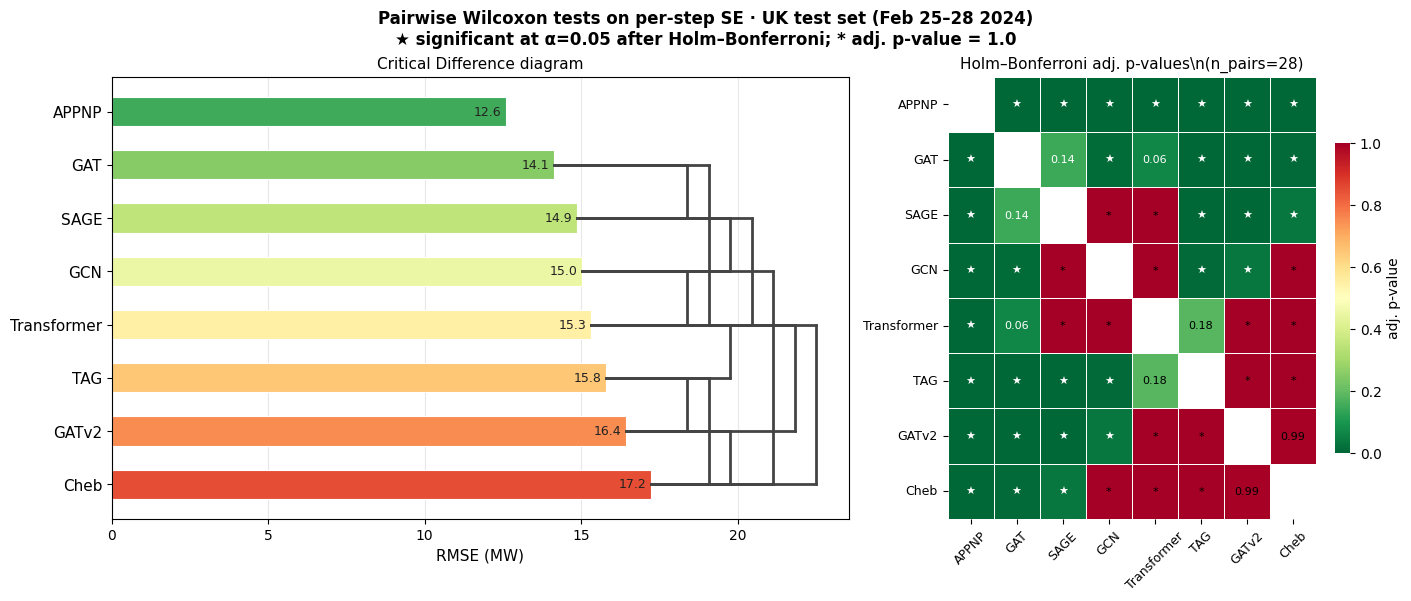

In [19]:
# Replot Wilcoxon CD diagram and heatmap with '*' for adj. p-value == 1.0
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from pathlib import Path

# Ensure minimal globals exist when running this cell in isolation
if 'results_root' not in globals():
    DATASET = globals().get('DATASET', 'unknown')
    results_root = Path(f"results_{DATASET}")
    results_root.mkdir(parents=True, exist_ok=True)

# Expecting these variables to exist in the kernel: padj_mat, models_sig, model_rmse, K,
# tick_labels, rmse_vals, unit, block_desc, dataset_label, n_pairs, alpha

fig, axes = plt.subplots(1, 2, figsize=(14, max(4, K * 0.55 + 1.5)),
                          gridspec_kw={'width_ratios': [2, 1]},
                          constrained_layout=True)

# Left: CD diagram
ax = axes[0]
y_pos = np.arange(K)[::-1]
colors = plt.cm.RdYlGn_r(np.linspace(0.15, 0.85, K))
bars = ax.barh(y_pos, rmse_vals, height=0.55, color=colors, edgecolor='white', linewidth=0.8, zorder=2)

vmax = max(rmse_vals)
lbl_gap = vmax * 0.012
lbl_width = vmax * 0.055
brk_step = vmax * 0.04
brk_start = vmax + lbl_gap + lbl_width

val_fmt = lambda v: f'{v:.1f}' if v < 10 else f'{v:.1f}'
for bar, val in zip(bars, rmse_vals):
    ax.text(val - 5*lbl_gap, bar.get_y() + bar.get_height() / 2,
            val_fmt(val), va='center', ha='left', fontsize=9, color='#222222', zorder=5)

# Reuse bracket logic from previous cell (if bracket_cols exists) or recompute
bracket_cols = {}
for i in range(K):
    for j in range(i + 1, K):
        if np.isnan(padj_mat[i, j]) or (padj_mat[i, j] < alpha):
            continue
        yi, yj = y_pos[i], y_pos[j]
        y_lo, y_hi = min(yi, yj), max(yi, yj)
        col = 0
        while True:
            occupied = bracket_cols.get(col, [])
            if all(y_hi < lo - 0.25 or y_lo > hi + 0.25 for lo, hi in occupied):
                break
            col += 1
        bracket_cols.setdefault(col, []).append((y_lo, y_hi))
        xb = brk_start + col * brk_step
        ax.plot([xb, xb], [yi, yj], color='#444444', lw=2.0, zorder=3, solid_capstyle='round')
        ax.plot([rmse_vals[i], xb], [yi, yi], color='#444444', lw=2.0, zorder=3)
        ax.plot([rmse_vals[j], xb], [yj, yj], color='#444444', lw=2.0, zorder=3)

n_cols = max(bracket_cols.keys()) + 1 if bracket_cols else 0
ax.set_xlim(0, brk_start + n_cols * brk_step + brk_step * 0.5)
ax.set_yticks(y_pos)
ax.set_yticklabels(tick_labels, fontsize=11)
ax.set_xlabel(f'RMSE ({unit})', fontsize=11)
ax.set_title('Critical Difference diagram', fontsize=11, pad=6)
ax.xaxis.grid(True, alpha=0.3, zorder=0)
ax.set_axisbelow(True)

# Right: heatmap with annotations
ax2 = axes[1]
mask = np.eye(K, dtype=bool)
sns.heatmap(padj_mat, annot=False, mask=mask,
            xticklabels=tick_labels, yticklabels=tick_labels,
            cmap='RdYlGn_r', vmin=0, vmax=1,
            linewidths=0.4, linecolor='white',
            ax=ax2, cbar_kws={'label': 'adj. p-value', 'shrink': 0.7})

for r in range(K):
    for c in range(K):
        if r == c or np.isnan(padj_mat[r, c]):
            continue
        sig = padj_mat[r, c] < alpha
        is_one = np.isclose(padj_mat[r, c], 1.0)
        if sig:
            txt = '★'
        elif is_one:
            txt = '*'
        else:
            txt = f'{padj_mat[r, c]:.2f}'
        ax2.text(c + 0.5, r + 0.5, txt,
                 ha='center', va='center', fontsize=8,
                 fontweight='bold' if sig else 'normal',
                 color='white' if padj_mat[r, c] < 0.15 else 'black')

ax2.tick_params(axis='x', rotation=45, labelsize=9)
ax2.tick_params(axis='y', rotation=0, labelsize=9)
ax2.set_title(f'Holm–Bonferroni adj. p-values\\n(n_pairs={n_pairs})', fontsize=11, pad=6)

fig.suptitle(
    f'Pairwise Wilcoxon tests on {block_desc} · {dataset_label}\n'
    f'★ significant at α={alpha} after Holm–Bonferroni; * adj. p-value = 1.0',
    fontsize=12, fontweight='bold',
)

out_pdf = results_root / f'wilcoxon_cd_{DATASET}_v2.pdf'
plt.savefig(out_pdf, bbox_inches='tight')
print(f"Saved: {out_pdf}")
plt.show()
